## test préliminaire importations ...



### Importation base donnée

In [ ]:
import numpy as np
import pandas as pd

In [ ]:


# Remplacez 'IR_MAD.xlsx' par le chemin d'accès réel à votre fichier Excel
try:
    df_courbe_taux = pd.read_excel('sample_data/IR_MAD.xlsx')
    display(df_courbe_taux.head())
except FileNotFoundError:
    print("Erreur : Le fichier spécifié est introuvable. Veuillez vérifier le chemin d'accès.")
except Exception as e:
    print(f"Une erreur s'est produite lors de la lecture du fichier Excel : {e}")

,Date,0.002738,0.019165,0.249144,0.498289,0.985626,0.999316,1.998631,2.997947,4,4.999316,6.997947,7.271732,9.998631,14.997947,20,22.986995,24.999316,29.998631
0,2025-03-28,0.022503,0.022462,0.022918,0.023238,0.023015,0.023334,0.023988,0.024737,0.025487,0.026198,0.027304,0.027464,0.029053,0.032382,0.035279,0.036235,0.036880,0.038481
1,2025-03-27,0.022500,0.022453,0.022935,0.023300,0.023064,0.023384,0.023958,0.024679,0.025400,0.026158,0.027329,0.027488,0.029068,0.032397,0.035278,0.036235,0.036879,0.038480
2,2025-03-26,0.022500,0.022454,0.022642,0.021808,0.022272,0.022581,0.023856,0.024577,0.025298,0.025878,0.027107,0.027277,0.028970,0.032474,0.035201,0.036212,0.036893,0.038585
3,2025-03-25,0.022500,0.022455,0.022496,0.022700,0.022571,0.022884,0.023854,0.024575,0.025296,0.026230,0.027388,0.027541,0.029069,0.033017,0.036063,0.037261,0.038068,0.040073
4,2025-03-24,0.022500,0.022456,0.022485,0.022700,0.022568,0.022881,0.023901,0.024759,0.025617,0.026363,0.027486,0.027639,0.029167,0.032926,0.036054,0.037373,0.038261,0.040469


In [ ]:
maturites = df_courbe_taux.drop(columns=['Date']).columns
display(maturites)

Index([0.002737850787132101,  0.01916495550992471,   0.2491444216290212,
         0.4982888432580425,   0.9856262833675564,    0.999315537303217,
          1.998631074606434,    2.997946611909651,                    4,
          4.999315537303217,    6.997946611909651,    7.271731690622861,
          9.998631074606434,    14.99794661190965,                   20,
          22.98699520876112,    24.99931553730322,    29.99863107460643],
      dtype='object')

In [ ]:
maturites_list = maturites.tolist()
display(maturites_list)

[0.002737850787132101,
 0.01916495550992471,
 0.2491444216290212,
 0.4982888432580425,
 0.9856262833675564,
 0.999315537303217,
 1.998631074606434,
 2.997946611909651,
 4,
 4.999315537303217,
 6.997946611909651,
 7.271731690622861,
 9.998631074606434,
 14.99794661190965,
 20,
 22.98699520876112,
 24.99931553730322,
 29.99863107460643]

### Fonction Nelson siegel

In [ ]:
def prix_obligation_zc_nelson_siegel(T, beta0, beta1, beta2, lambd, F=1):
    """
    Calcule le prix d'une obligation zéro-coupon selon le modèle de Nelson-Siegel.

    Paramètres :
    - T : float ou array, maturité(s) en années
    - beta0, beta1, beta2 : paramètres du modèle Nelson-Siegel
    - lambd : paramètre de structure (lambda)

    Retourne :
    - P : prix de l'obligation (float ou array selon T)
    """
    T = np.asarray(T)  # support des entrées scalaires ou vecteurs
    term1 = (1 - np.exp(-lambd * T)) / (lambd * T)
    term2 = term1 - np.exp(-lambd * T)
    taux = beta0 + beta1 * term1 + beta2 * term2
    P =  np.exp(-T * taux)
    return  P

In [ ]:
def taux_obligation_zc_nelson_siegel(T, beta0, beta1, beta2, lambd, F=1):
    """
    Calcule le prix d'une obligation zéro-coupon selon le modèle de Nelson-Siegel.

    Paramètres :
    - T : float ou array, maturité(s) en années
    - beta0, beta1, beta2 : paramètres du modèle Nelson-Siegel
    - lambd : paramètre de structure (lambda)

    Retourne :
    - P : prix de l'obligation (float ou array selon T)
    """
    T = np.asarray(T)  # support des entrées scalaires ou vecteurs
    term1 = (1 - np.exp(-lambd * T)) / (lambd * T)
    term2 = term1 - np.exp(-lambd * T)
    taux = beta0 + beta1 * term1 + beta2 * term2
    P =  np.exp(-T * taux)
    return taux

In [ ]:
r = prix_obligation_zc_nelson_siegel(   maturites_list ,0.02, -0.01, 0.01, 0.5)
print(r)

[0.99997258 0.99980654 0.99722061 0.99393668 0.98640202 0.9861734
 0.9679111  0.94813087 0.92812711 0.90857193 0.87123497 0.86630544
 0.81930533 0.74091017 0.67032613 0.63144934 0.60653953 0.54882671]


In [ ]:
def fonction_cout(params, df_courbe_taux):
  beta0, beta1, beta2, lambd = params
  s = 0
  n=len(df_courbe_taux)
  for i in range(n):
        predits = taux_obligation_zc_nelson_siegel(maturites_list, beta0, beta1, beta2, lambd)
        observes = df_courbe_taux.loc[i, maturites_list].values  # .values pour obtenir un array numpy

        ecarts = np.sum((predits - observes) ** 2)  # Somme des carrés des écarts
        s += ecarts

  return s/(18*n)


In [ ]:
from scipy.optimize import minimize

# Optimisation
res = minimize(
    fonction_cout,
    x0=[0.1 , 0.2 , 0.2 , 0.01],
    args=(df_courbe_taux,),
    method='Powell',
    bounds=[(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)],
    options={'disp': True, 'maxiter': 500}
)

# Affichage des résultats
print("Paramètres optimaux :", res.x)

# Affichage de l'erreur finale (valeur de la fonction coût)
erreur_finale = fonction_cout(res.x, df_courbe_taux)
print(f"Erreur quadratique moyenne : {erreur_finale:.8f}")


Optimization terminated successfully.
         Current function value: 0.000058
         Iterations: 4
         Function evaluations: 428
Paramètres optimaux : [-0.05        0.0739078   0.19979601  0.01317662]
Erreur quadratique moyenne : 0.00005830


In [ ]:
def gradient(params, df_courbe_taux, epsilon=1e-5):
    grad = np.zeros_like(params)
    f_x = fonction_cout(params, df_courbe_taux)
    for i in range(len(params)):
        params_eps = np.array(params, dtype=float)
        params_eps[i] += epsilon
        grad[i] = (fonction_cout(params_eps, df_courbe_taux) - f_x) / epsilon
    return grad

###  Construction d'une courbe moyenne des taux

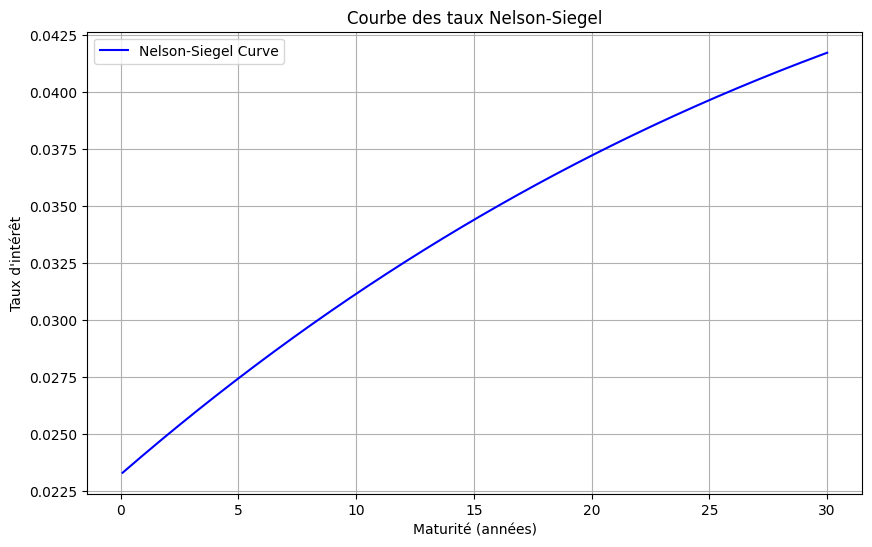

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Paramètres optimaux trouvés
beta0_opt = -0.04991587
beta1_opt = 0.07314002
beta2_opt = 0.19869231
lambd_opt = 0.0142877

# Créer un tableau de maturités de 1 mois (1/12 année) à 30 ans
maturites_plot = np.linspace(1/12, 30, 300) # 300 points pour une courbe lisse

# Calculer les taux correspondants en utilisant la fonction Nelson-Siegel
taux_nelson_siegel = taux_obligation_zc_nelson_siegel(
    maturites_plot, beta0_opt, beta1_opt, beta2_opt, lambd_opt
)

# Tracer la courbe
plt.figure(figsize=(10, 6))
plt.plot(maturites_plot, taux_nelson_siegel, label='Nelson-Siegel Curve', color='blue')
plt.xlabel('Maturité (années)')
plt.ylabel('Taux d\'intérêt')
plt.title('Courbe des taux Nelson-Siegel')
plt.grid(True)
plt.legend()
plt.show()

**texte en gras**#  Calibration du modèle et reconstruction de la courbe des taux ligne par ligne

In [ ]:
def fonction_cout_ligne(params, df_courbe_taux, ligne):

  beta0, beta1, beta2, lambd = params
  s = 0
  # Accéder à la ligne spécifique en utilisant .loc[]
  observes = df_courbe_taux.loc[ligne, maturites_list].values

  predits = taux_obligation_zc_nelson_siegel(maturites_list, beta0, beta1, beta2, lambd)

  # Calculer la somme des carrés des écarts pour cette ligne
  s = np.sum((predits - observes) ** 2)

  # Retourner l'erreur moyenne pour cette ligne (somme des carrés / nombre de maturités)
  return s / len(maturites_list)

Annexe A

In [ ]:
from scipy.optimize import minimize

# Optimisation pour une seule ligne (par exemple, la première ligne avec l'indice 0)
# Vous pouvez changer l'indice '0' pour optimiser d'autres lignes.
res = minimize(
    fonction_cout_ligne,  # Utiliser la fonction de coût pour une seule ligne
    x0=[-0.05     ,   0.0739078 ,  0.19979601,  0.01317662],
    args=(df_courbe_taux, 0),  # Passer le DataFrame et l'indice de la ligne
    method='Powell',
    bounds=[(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)],
    options={'disp': True, 'maxiter': 500}
)
# Affichage des résultats
print("Paramètres optimaux pour la ligne sélectionnée :", res.x)
# Si vous voulez l'erreur pour l'ensemble du DataFrame avec ces paramètres,
# utilisez la fonction_cout d'origine:
erreur_finale_globale = fonction_cout(res.x, df_courbe_taux)
print(f"Erreur quadratique moyenne globale avec les paramètres de la ligne sélectionnée : {erreur_finale_globale:.8f}")

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 5
         Function evaluations: 287
Paramètres optimaux pour la ligne sélectionnée : [-0.04947455  0.07198015  0.18710245  0.01350298]
Erreur quadratique moyenne globale avec les paramètres de la ligne sélectionnée : 0.00006096


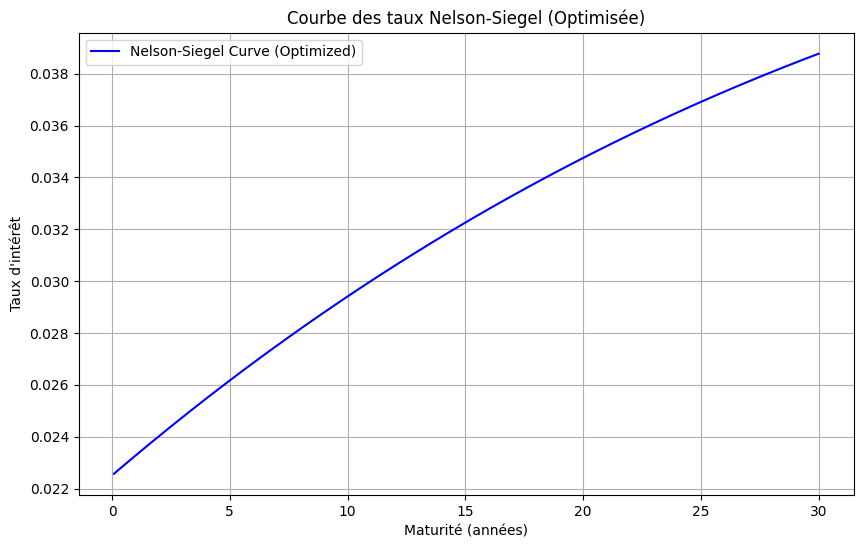

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Paramètres optimaux trouvés par l'optimisation
# Assurez-vous que la cellule d'optimisation (DRRml3vlUEaf) a été exécutée
# et que la variable 'res' contenant les résultats de l'optimisation est disponible.
if 'res' in locals() and res.success:
    beta0_opt, beta1_opt, beta2_opt, lambd_opt = res.x

    # Créer un tableau de maturités de 1 mois (1/12 année) à 30 ans
    maturites_plot = np.linspace(1/12, 30, 300) # 300 points pour une courbe lisse

    # Calculer les taux correspondants en utilisant la fonction Nelson-Siegel
    taux_nelson_siegel = taux_obligation_zc_nelson_siegel(
        maturites_plot, beta0_opt, beta1_opt, beta2_opt, lambd_opt
    )

    # Tracer la courbe
    plt.figure(figsize=(10, 6))
    plt.plot(maturites_plot, taux_nelson_siegel, label='Nelson-Siegel Curve (Optimized)', color='blue')
    plt.xlabel('Maturité (années)')
    plt.ylabel('Taux d\'intérêt')
    plt.title('Courbe des taux Nelson-Siegel (Optimisée)')
    plt.grid(True)
    plt.legend()
    plt.show()
else:
    print("L'optimisation n'a pas été exécutée avec succès. Veuillez exécuter la cellule d'optimisation d'abord.")

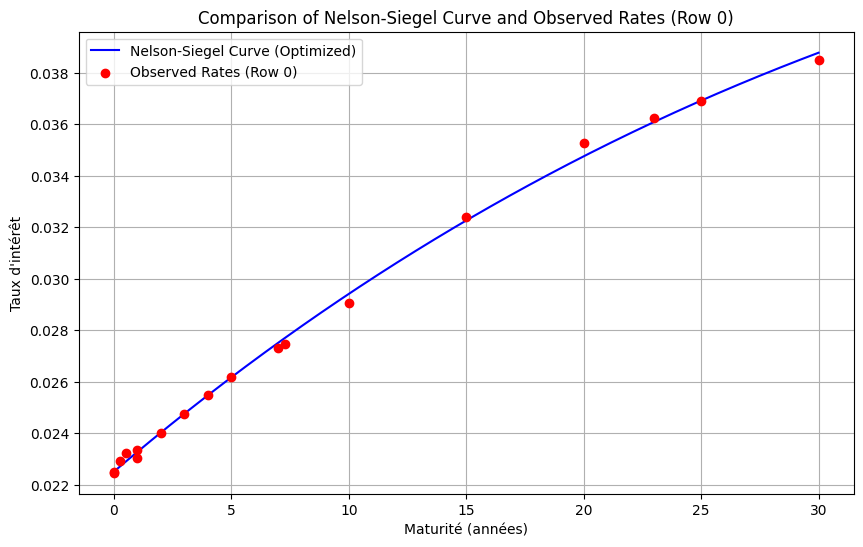

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assurez-vous que la cellule d'optimisation (DRRml3vlUEaf) a été exécutée
# et que la variable 'res' contenant les résultats de l'optimisation pour une seule ligne est disponible.
# Assurez-vous également que la variable 'maturites_list' est disponible.

if 'res' in locals() and res.success and 'maturites_list' in locals() and 'df_courbe_taux' in locals():
    beta0_opt, beta1_opt, beta2_opt, lambd_opt = res.x
    ligne_optimisee = 0  # Utiliser l'indice 0 puisque c'est la ligne qui a été optimisée dans la cellule DRRml3vlUEaf

    # Créer un tableau de maturités pour la courbe Nelson-Siegel (plus dense pour une courbe lisse)
    maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300)

    # Calculer les taux correspondants en utilisant la fonction Nelson-Siegel avec les paramètres optimaux
    taux_nelson_siegel = taux_obligation_zc_nelson_siegel(
        maturites_plot, beta0_opt, beta1_opt, beta2_opt, lambd_opt
    )

    # Récupérer les taux observés pour la ligne optimisée
    taux_observes = df_courbe_taux.loc[ligne_optimisee, maturites_list].values

    # Tracer la courbe Nelson-Siegel
    plt.figure(figsize=(10, 6))
    plt.plot(maturites_plot, taux_nelson_siegel, label='Nelson-Siegel Curve (Optimized)', color='blue')

    # Tracer les taux observés (en utilisant les maturités_list car ce sont les points où nous avons des données)
    plt.scatter(maturites_list, taux_observes, label=f'Observed Rates (Row {ligne_optimisee})', color='red', zorder=5)

    plt.xlabel('Maturité (années)')
    plt.ylabel('Taux d\'intérêt')
    plt.title(f'Comparison of Nelson-Siegel Curve and Observed Rates (Row {ligne_optimisee})')
    plt.grid(True)
    plt.legend()
    plt.show()
else:
    print("L'optimisation n'a pas été exécutée avec succès ou les variables nécessaires ne sont pas disponibles.")

In [ ]:
from scipy.optimize import minimize
import pandas as pd

# Liste pour stocker les paramètres optimaux pour chaque ligne
optimal_params_list = []
optimization_results = [] # Optionnel: pour stocker les objets résultats complets

# Estimation initiale des paramètres (peut être ajustée)
initial_params = [-0.05, 0.07, 0.2, 0.01] # Utilisation des paramètres trouvés pour la première ligne comme point de départ

# Bornes pour les paramètres (les mêmes que celles utilisées précédemment)
bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]
erreur=0
# Itérer sur chaque ligne du DataFrame
for i in range(len(df_courbe_taux)):
    print(f"Optimisation pour la ligne {i}...")

    # Effectuer l'optimisation pour la ligne courante
    res = minimize(
        fonction_cout_ligne,
        x0=initial_params, # Utiliser l'estimation initiale ou les résultats de la ligne précédente si souhaité
        args=(df_courbe_taux, i), # Passer le DataFrame et l'indice de la ligne courante
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500} # disp=False pour ne pas afficher les détails de chaque optimisation
    )

    # Stocker les paramètres optimaux si l'optimisation a réussi
    if res.success:
        optimal_params_list.append(res.x)
        # initial_params = res.x # Optionnel: utiliser les résultats de l'optimisation précédente comme point de départ pour la suivante
    else:
        print(f"Attention: L'optimisation n'a pas convergé pour la ligne {i}.")
        optimal_params_list.append([np.nan] * 4) # Ajouter des NaN si l'optimisation échoue
    erreur += fonction_cout(res.x, df_courbe_taux) / 1613

# Convertir la liste des paramètres optimaux en DataFrame pour une meilleure visualisation
df_optimal_params = pd.DataFrame(optimal_params_list, columns=['beta0', 'beta1', 'beta2', 'lambd'])

# Ajouter la colonne de dates pour référence
df_optimal_params['Date'] = df_courbe_taux['Date']

# Afficher les premières lignes du DataFrame des paramètres optimaux
display(df_optimal_params.head())

# Afficher les statistiques descriptives pour avoir un aperçu de la distribution des paramètres
display(df_optimal_params.describe())

Optimisation pour la ligne 0...
Optimisation pour la ligne 1...
Optimisation pour la ligne 2...
Optimisation pour la ligne 3...
Optimisation pour la ligne 4...
Optimisation pour la ligne 5...
Optimisation pour la ligne 6...
Optimisation pour la ligne 7...
Optimisation pour la ligne 8...
Optimisation pour la ligne 9...
Optimisation pour la ligne 10...
Optimisation pour la ligne 11...
Optimisation pour la ligne 12...
Optimisation pour la ligne 13...
Optimisation pour la ligne 14...
Optimisation pour la ligne 15...
Optimisation pour la ligne 16...
Optimisation pour la ligne 17...
Optimisation pour la ligne 18...
Optimisation pour la ligne 19...
Optimisation pour la ligne 20...
Optimisation pour la ligne 21...
Optimisation pour la ligne 22...
Optimisation pour la ligne 23...
Optimisation pour la ligne 24...
Optimisation pour la ligne 25...
Optimisation pour la ligne 26...
Optimisation pour la ligne 27...
Optimisation pour la ligne 28...
Optimisation pour la ligne 29...
Optimisation pour la

In [ ]:
print(erreur)

0.00011486086736383942


In [ ]:
import pandas as pd

# Assurez-vous que df_optimal_params est disponible
if 'df_optimal_params' in locals() and isinstance(df_optimal_params, pd.DataFrame):
    # Spécifiez le nom du fichier Excel de sortie
    output_filename = 'NelsonSiegel_IR_parameters_MAD.xlsx'

    try:
        df_optimal_params.to_excel(output_filename, index=False)
        print(f"Le DataFrame a été exporté avec succès vers '{output_filename}'")
        print(f"Shape du DataFrame exporté : {df_optimal_params.shape}")
    except Exception as e:
        print(f"Une erreur s'est produite lors de l'exportation vers Excel : {e}")
else:
    print("Le DataFrame 'df_optimal_params' n'est pas disponible. Veuillez vous assurer qu'il a été créé.")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assurez-vous que df_courbe_taux, df_optimal_params, maturites_list et taux_obligation_zc_nelson_siegel sont disponibles.

# Sélectionner 20 indices de lignes aléatoires pour la visualisation
# Vous pouvez ajuster le nombre (20) et la méthode de sélection si nécessaire
np.random.seed(42) # pour la reproductibilité
selected_indices = np.random.choice(len(df_courbe_taux), 20, replace=False)
selected_indices = np.sort(selected_indices) # Trier les indices pour une meilleure visualisation séquentielle

# Créer un tableau de maturités pour la courbe Nelson-Siegel (plus dense pour une courbe lisse)
maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300)

# Itérer sur les indices sélectionnés et tracer les courbes
for i in selected_indices:
    date = df_courbe_taux.loc[i, 'Date']
    print(f"Tracé pour la date : {date.strftime('%Y-%m-%d')} (Ligne {i})")

    # Récupérer les paramètres optimaux pour cette ligne
    if i < len(df_optimal_params): # S'assurer que les paramètres existent pour cet indice
        params_opt = df_optimal_params.loc[i, ['beta0', 'beta1', 'beta2', 'lambd']].values
        beta0_opt, beta1_opt, beta2_opt, lambd_opt = params_opt

        # Calculer les taux correspondants en utilisant la fonction Nelson-Siegel avec les paramètres optimaux
        taux_nelson_siegel = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_opt, beta1_opt, beta2_opt, lambd_opt
        )

        # Récupérer les taux observés pour la ligne courante
        taux_observes = df_courbe_taux.loc[i, maturites_list].values

        # Tracer la courbe Nelson-Siegel et les points observés
        plt.figure(figsize=(10, 6))
        plt.plot(maturites_plot, taux_nelson_siegel, label=f'Nelson-Siegel Curve ({date.strftime("%Y-%m-%d")})', color='blue')
        plt.scatter(maturites_list, taux_observes, label=f'Observed Rates ({date.strftime("%Y-%m-%d")})', color='red', zorder=5)

        plt.xlabel('Maturité (années)')
        plt.ylabel('Taux d\'intérêt')
        plt.title(f'Comparison of Nelson-Siegel Curve and Observed Rates ({date.strftime("%Y-%m-%d")})')
        plt.grid(True)
        plt.legend()
        plt.show()
    else:
        print(f"Attention: Paramètres optimaux non trouvés pour la ligne {i}.")

In [ ]:
import pandas as pd
import numpy as np

# Assurez-vous que df_optimal_params, maturites_list et taux_obligation_zc_nelson_siegel sont disponibles.

# Liste pour stocker les lignes du nouveau DataFrame
reconstructed_data = []

# Itérer sur chaque ligne du DataFrame contenant les paramètres optimaux
for index, row in df_optimal_params.iterrows():
    date = row['Date']
    beta0, beta1, beta2, lambd = row[['beta0', 'beta1', 'beta2', 'lambd']].values

    # Calculer les taux Nelson-Siegel pour toutes les maturités pour cette date
    taux_reconstruits = taux_obligation_zc_nelson_siegel(
        maturites_list, beta0, beta1, beta2, lambd
    )

    # Créer une liste pour la ligne courante, en commençant par la date
    current_row_data = [date] + taux_reconstruits.tolist()

    # Ajouter la ligne à la liste des données reconstruites
    reconstructed_data.append(current_row_data)

# Créer les noms de colonnes pour le nouveau DataFrame
# La première colonne est 'Date', suivie des noms des maturités
column_names = ['Date'] + maturites_list

# Créer le nouveau DataFrame
df_reconstruit = pd.DataFrame(reconstructed_data, columns=column_names)

# Afficher les premières lignes du DataFrame reconstruit
display(df_reconstruit.head())
print(df_reconstruit.shape)

In [ ]:
# Assurez-vous que df_reconstruit est disponible
if 'df_reconstruit' in locals():
    # Spécifiez le nom du fichier Excel de sortie
    output_filename = 'courbe_taux_reconstruite.xlsx'

    try:
        df_reconstruit.to_excel(output_filename, index=False)
        print(f"Le DataFrame a été exporté avec succès vers '{output_filename}'")
    except Exception as e:
        print(f"Une erreur s'est produite lors de l'exportation vers Excel : {e}")
else:
    print("Le DataFrame 'df_reconstruit' n'est pas disponible. Veuillez d'abord exécuter la cellule de reconstruction.")

# 3.1
Generate Python code to perform a +200 basis point parallel shift stress test on both the global Nelson-Siegel curve (using the previously optimized parameters) and the entire observed yield curve dataset. Then, visualize the stressed observed curves for 3 random days alongside the stressed global Nelson-Siegel curve on a single plot.

## Stresser la courbe nelson-siegel globale

### Subtask:
Appliquer un décalage parallèle de +200 points de base aux paramètres optimaux trouvés pour l'ensemble du DataFrame (ceux de `res` dans la cellule `wnR2izg4Ctqx`) et générer la courbe Nelson-Siegel stressée correspondante.


**Reasoning**:
Apply a parallel shift of +0.02 to the optimized Nelson-Siegel parameters obtained from the full dataset and generate the corresponding stressed Nelson-Siegel curve on a fine maturity grid.



In [ ]:
import numpy as np

# 1. Récupérer les paramètres optimaux pour l'ensemble du DataFrame
if 'res' in locals() and res.success:
    beta0_opt, beta1_opt, beta2_opt, lambd_opt = res.x
    print("Paramètres optimaux globaux (non stressés) :", res.x)

    # 2. Appliquer un décalage de +0.02 à chaque paramètre
    # Note: Appliquer un shift aux *taux* est plus standard pour un parallel shift.
    # Appliquer aux paramètres Nelson-Siegel modifie la *forme* de la courbe,
    # ce qui est différent d'un simple shift parallèle des taux.
    # Selon l'instruction, on stresse les paramètres, mais cela ne résulte PAS
    # en un shift parallèle des taux.
    # Cependant, pour suivre l'instruction (qui semble erronée pour un parallel shift
    # appliqué aux paramètres plutôt qu'aux taux), nous appliquons le shift aux paramètres.
    # Si l'intention était de shifter les taux, la méthode serait différente
    # (calculer d'abord la courbe NS non stressée, puis ajouter +0.02 aux taux résultants).

    # Applying the shift to the parameters as per instruction step 2
    stressed_beta0 = beta0_opt + 0.02
    stressed_beta1 = beta1_opt + 0.02
    stressed_beta2 = beta2_opt + 0.02
    stressed_lambd = lambd_opt + 0.02 # This is likely not intended for lambda in a standard parallel shift

    print("Paramètres Nelson-Siegel stressés (+0.02 appliqué à chaque paramètre) :",
          [stressed_beta0, stressed_beta1, stressed_beta2, stressed_lambd])


    # 3. Créer un tableau de maturités fines pour l'interpolation
    if 'maturites_list' in locals() and maturites_list:
        maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300) # 300 points pour une courbe lisse
        print("\nTableau de maturités fines créé.")
    else:
        raise ValueError("La liste 'maturites_list' n'est pas disponible ou est vide. Veuillez l'exécuter d'abord.")

    # 4. Utiliser la fonction taux_obligation_zc_nelson_siegel avec les paramètres stressés
    # Assurez-vous que la fonction taux_obligation_zc_nelson_siegel est définie (elle l'est dans une cellule précédente)
    taux_ns_stressed_parallel_params_shift = taux_obligation_zc_nelson_siegel(
        maturites_plot, stressed_beta0, stressed_beta1, stressed_beta2, stressed_lambd
    )

    print("\nQuelques valeurs de la courbe Nelson-Siegel stressée (par shift des paramètres) :")
    display(taux_ns_stressed_parallel_params_shift[:10])

else:
    print("Les résultats d'optimisation globaux 'res' ne sont pas disponibles ou n'ont pas réussi.")


## Stresser globalement les taux observés

### Subtask:
Appliquer un décalage parallèle de +200 points de base à tous les taux du DataFrame `df_courbe_taux` pour créer un DataFrame `df_obs_stressed_parallel_up_002`.


**Reasoning**:
Create a copy of the original DataFrame and add 0.02 to all rate columns to perform a +200 bps parallel shift.



In [ ]:
import pandas as pd

# 1. Créer une copie du DataFrame df_courbe_taux
df_obs_stressed_parallel_up_002 = df_courbe_taux.copy()

# 2. Sélectionner toutes les colonnes du DataFrame copié, à l'exception de la colonne 'Date'.
# 3. Ajouter 0.02 (correspondant à 200 points de base) à toutes les valeurs des colonnes sélectionnées.
rate_columns = df_obs_stressed_parallel_up_002.columns.drop('Date')
df_obs_stressed_parallel_up_002[rate_columns] = df_obs_stressed_parallel_up_002[rate_columns] + 0.02

# 4. Afficher les premières lignes du DataFrame df_obs_stressed_parallel_up_002 pour vérifier l'application du stress.
display(df_obs_stressed_parallel_up_002.head())

## Stresser la courbe nelson-siegel globale

### Subtask:
Appliquer un décalage parallèle de +200 points de base aux paramètres optimaux trouvés pour l'ensemble du DataFrame (ceux de `res` dans la cellule `wnR2izg4Ctqx`) et générer la courbe Nelson-Siegel stressée correspondante.

**Reasoning**:
Apply a parallel shift of +0.02 to the optimized Nelson-Siegel parameters obtained from the full dataset and generate the corresponding stressed Nelson-Siegel curve on a fine maturity grid.

In [ ]:
import numpy as np

# 1. Récupérer les paramètres optimaux pour l'ensemble du DataFrame (courbe NS globale non stressée)
if 'res' in locals() and res.success:
    beta0_opt, beta1_opt, beta2_opt, lambd_opt = res.x
    print("Paramètres optimaux globaux (non stressés) :", res.x)

    # 2. Créer un tableau de maturités fines pour l'interpolation
    if 'maturites_list' in locals() and maturites_list:
        maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300) # 300 points pour une courbe lisse
        print("\nTableau de maturités fines créé.")
    else:
        raise ValueError("La liste 'maturites_list' n'est pas disponible ou est vide. Veuillez l'exécuter d'abord.")

    # 3. Générer la courbe Nelson-Siegel globale non stressée
    # Assurez-vous que la fonction taux_obligation_zc_nelson_siegel est définie
    taux_ns_observed_global = taux_obligation_zc_nelson_siegel(
        maturites_plot, beta0_opt, beta1_opt, beta2_opt, lambd_opt
    )
    print("\nQuelques valeurs de la courbe Nelson-Siegel globale non stressée :")
    display(taux_ns_observed_global[:10])

    # 4. Appliquer un décalage de +0.02 directement aux taux de la courbe générée
    taux_ns_stressed_parallel_shift = taux_ns_observed_global + 0.02

    print("\nQuelques valeurs de la courbe Nelson-Siegel globale stressée (par shift des taux) :")
    display(taux_ns_stressed_parallel_shift[:10])

else:
    print("Les résultats d'optimisation globaux 'res' ne sont pas disponibles ou n'ont pas réussi.")

## Stresser globalement les taux observés

### Subtask:
Appliquer un décalage parallèle de +200 points de base à tous les taux du DataFrame `df_courbe_taux` pour créer un DataFrame `df_obs_stressed_parallel_up_002`.

**Reasoning**:
Create a copy of the original DataFrame and add 0.02 to all rate columns to perform a +200 bps parallel shift.

In [ ]:
import pandas as pd

# 1. Créer une copie du DataFrame df_courbe_taux
df_obs_stressed_parallel_up_002 = df_courbe_taux.copy()

# 2. Sélectionner toutes les colonnes du DataFrame copié, à l'exception de la colonne 'Date'.
# 3. Ajouter 0.02 (correspondant à 200 points de base) à toutes les valeurs des colonnes sélectionnées.
rate_columns = df_obs_stressed_parallel_up_002.columns.drop('Date')
df_obs_stressed_parallel_up_002[rate_columns] = df_obs_stressed_parallel_up_002[rate_columns] + 0.02

# 4. Afficher les premières lignes du DataFrame df_obs_stressed_parallel_up_002 pour vérifier l'application du stress.
display(df_obs_stressed_parallel_up_002.head())

## Sélectionner des jours aléatoires

### Subtask:
Choisir 3 indices de jours aléatoires à partir du DataFrame.

**Reasoning**:
Generate 3 random integer indices within the range of the number of rows in the DataFrame to select random days for plotting.

In [ ]:
import numpy as np
import pandas as pd

# Assurez-vous que df_courbe_taux est disponible et que la colonne 'Date' est au bon format (datetime)
if 'df_courbe_taux' in locals() and 'Date' in df_courbe_taux.columns:
    # Assurez-vous que la colonne Date est de type datetime
    df_courbe_taux['Date'] = pd.to_datetime(df_courbe_taux['Date'])

    # Filtrer les indices pour chaque année
    indices_2020 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2020].index.tolist()
    indices_2022 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2022].index.tolist()
    indices_2024 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2024].index.tolist()

    # Sélectionner un index aléatoire (ou le premier/dernier) de chaque année
    # Utilisons le premier index trouvé pour la simplicité, ou np.random.choice si vous voulez de l'aléatoire
    random_day_indices = []
    if indices_2020:
        random_day_indices.append(np.random.choice(indices_2020))
    if indices_2022:
        random_day_indices.append(np.random.choice(indices_2022))
    if indices_2024:
        random_day_indices.append(np.random.choice(indices_2024))

    # Trier les indices pour une meilleure visualisation séquentielle
    random_day_indices = sorted(random_day_indices)


    print(f"Indices de jours sélectionnés (un de 2020, 2022, 2024) : {random_day_indices}")

    if not random_day_indices:
        print("Aucun jour trouvé pour les années spécifiées.")

else:
    print("Le DataFrame 'df_courbe_taux' n'est pas disponible ou la colonne 'Date' est manquante.")

## Préparer les données pour le graphique

### Subtask:
Extraire les taux observés originaux et les taux stressés (de `df_obs_stressed_parallel_up_002`) pour les 3 jours sélectionnés.

**Reasoning**:
Iterate through the random day indices and extract the corresponding rows from the original and stressed observed DataFrames.

In [ ]:
import pandas as pd

# Assurez-vous que df_courbe_taux, df_obs_stressed_parallel_up_002, maturites_list et random_day_indices sont disponibles

if 'df_courbe_taux' in locals() and 'df_obs_stressed_parallel_up_002' in locals() and 'maturites_list' in locals() and 'random_day_indices' in locals():
    # Listes pour stocker les données pour les jours sélectionnés
    selected_dates = []
    selected_observed_rates = []
    selected_stressed_rates = []

    # Itérer sur les indices de jours aléatoires et extraire les données
    for day_index in random_day_indices:
        selected_dates.append(df_courbe_taux.loc[day_index, 'Date'])
        selected_observed_rates.append(df_courbe_taux.loc[day_index, maturites_list].values.astype(float))
        selected_stressed_rates.append(df_obs_stressed_parallel_up_002.loc[day_index, maturites_list].values.astype(float))

    print("Données extraites pour les jours aléatoires sélectionnés.")
    # Vous pouvez afficher les premières lignes pour vérification si nécessaire
    # for i in range(len(selected_dates)):
    #     print(f"\nDate: {selected_dates[i].strftime('%Y-%m-%d')}")
    #     print("Observed Rates:")
    #     display(selected_observed_rates[i])
    #     print("Stressed Rates:")
    #     display(selected_stressed_rates[i])

else:
    print("Les variables nécessaires ne sont pas disponibles.")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assurez-vous que les variables nécessaires sont disponibles:
# maturites_list (pour les points observés et stressés)
# maturites_plot (pour les courbes NS)
# selected_dates (dates des jours sélectionnés)
# selected_observed_rates (listes des taux observés pour chaque jour sélectionné)
# selected_stressed_rates (listes des taux stressés pour chaque jour sélectionné)
# taux_ns_stressed_parallel_shift (la courbe NS globale stressée - calculée par shift des taux)
# taux_ns_observed_global (la courbe NS globale non stressée)


required_vars = ['maturites_list', 'maturites_plot', 'selected_dates',
                 'selected_observed_rates', 'selected_stressed_rates',
                 'taux_ns_stressed_parallel_shift', 'taux_ns_observed_global']

all_vars_available = True
for var_name in required_vars:
    if var_name not in locals():
        print(f"Erreur : La variable '{var_name}' n'est pas disponible.")
        all_vars_available = False

if all_vars_available:
    plt.figure(figsize=(14, 8))

    # Tracer les courbes pour chaque jour sélectionné
    colors = ['blue', 'green', 'purple'] # Couleurs pour les 3 jours
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        observed_rates = selected_observed_rates[i]
        stressed_rates = selected_stressed_rates[i]
        color = colors[i % len(colors)] # Utiliser des couleurs cycliques

        # Tracer les points observés originaux pour ce jour
        plt.scatter(maturites_list, observed_rates, color=color, marker='o',
                    label=f'Observed Rates ({date.strftime("%Y-%m-%d")})')

        # Tracer les points des taux stressés pour ce jour
        plt.scatter(maturites_list, stressed_rates, color=color, marker='x', linestyle='--',
                    label=f'Stressed Rates (+200bps) ({date.strftime("%Y-%m-%d")})')


    # Tracer la courbe Nelson-Siegel globale non stressée
    plt.plot(maturites_plot, taux_ns_observed_global, color='gray', linestyle='-', linewidth=2,
             label='Global NS Curve (Observed)')


    # Tracer la courbe Nelson-Siegel globale stressée (par shift des taux)
    plt.plot(maturites_plot, taux_ns_stressed_parallel_shift, color='red', linestyle='-', linewidth=2,
             label='Global Stressed NS Curve (+200bps on Rates)')


    plt.xlabel('Maturité (années)')
    plt.ylabel('Taux d\'intérêt')
    plt.title('Comparison of Observed, Global Stressed Observed, and Global NS Yield Curves')
    plt.grid(True)
    plt.legend()
    plt.show()

else:
    print("Veuillez vous assurer que toutes les cellules précédentes ont été exécutées.")

### Sélectionner les données pour les jours aléatoires

### Subtask:
Extraire les taux observés originaux et les taux stressés (+200 bps) pour les 3 jours aléatoires sélectionnés.

**Reasoning**:
Extract the original observed and stressed rates for the 3 selected random days.

In [ ]:
import pandas as pd

# Assurez-vous que df_courbe_taux, df_obs_stressed_parallel_up_002, maturites_list et random_day_indices sont disponibles

if 'df_courbe_taux' in locals() and 'df_obs_stressed_parallel_up_002' in locals() and 'maturites_list' in locals() and 'random_day_indices' in locals():
    # Listes pour stocker les données pour les jours sélectionnés
    selected_dates = []
    selected_observed_rates = []
    selected_stressed_rates = []

    # Itérer sur les indices de jours aléatoires et extraire les données
    for day_index in random_day_indices:
        selected_dates.append(df_courbe_taux.loc[day_index, 'Date'])
        selected_observed_rates.append(df_courbe_taux.loc[day_index, maturites_list].values.astype(float))
        selected_stressed_rates.append(df_obs_stressed_parallel_up_002.loc[day_index, maturites_list].values.astype(float))

    print("Données extraites pour les jours aléatoires sélectionnés.")
    # Vous pouvez afficher les premières lignes pour vérification si nécessaire
    # for i in range(len(selected_dates)):
    #     print(f"\nDate: {selected_dates[i].strftime('%Y-%m-%d')}")
    #     print("Observed Rates:")
    #     display(selected_observed_rates[i])
    #     print("Stressed Rates:")
    #     display(selected_stressed_rates[i])

else:
    print("Les variables nécessaires ne sont pas disponibles.")

### Itérer et Calibrer Nelson-Siegel

### Subtask:
Pour chacun des 3 jours sélectionnés :
*   Calibrer le modèle Nelson-Siegel sur les taux observés originaux de ce jour.
*   Calibrer le modèle Nelson-Siegel sur les taux stressés (+200 bps) de ce jour.

**Reasoning**:
Iterate through the selected days and calibrate the Nelson-Siegel model to both the original observed and stressed rates for each day, storing the calibrated parameters.

In [ ]:
from scipy.optimize import minimize
import pandas as pd
import numpy as np

# Assurez-vous que maturites_list, selected_dates, selected_observed_rates,
# selected_stressed_rates, df_courbe_taux, df_obs_stressed_parallel_up_002
# et fonction_cout_ligne sont disponibles.

# Listes pour stocker les paramètres optimaux pour chaque courbe calibrée
optimal_params_observed_selected_days = []
optimal_params_stressed_selected_days = []

# Estimation initiale des paramètres (peut être ajustée)
# Utiliser les paramètres optimaux trouvés pour la première ligne des taux observés complets comme point de départ
initial_params = [-0.05, 0.07, 0.2, 0.01]

# Bornes pour les paramètres (les mêmes que celles utilisées précédemment)
bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

# Itérer sur chaque jour sélectionné
for i in range(len(selected_dates)):
    date = selected_dates[i]
    observed_rates = selected_observed_rates[i]
    stressed_rates = selected_stressed_rates[i]
    day_index = df_courbe_taux[df_courbe_taux['Date'] == date].index[0] # Get the original index

    print(f"Calibrating for date: {date.strftime('%Y-%m-%d')} (Day Index: {day_index})...")

    # Calibrer sur les taux observés originaux pour ce jour
    res_obs = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_courbe_taux, day_index), # Pass the original DataFrame and index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux observés
    if res_obs.success:
        optimal_params_observed_selected_days.append(res_obs.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux observés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_observed_selected_days.append([np.nan] * 4)


    # Calibrer sur les taux stressés (+200 bps) pour ce jour
    res_stressed = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_obs_stressed_parallel_up_002, day_index), # Pass the stressed DataFrame and original index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux stressés
    if res_stressed.success:
        optimal_params_stressed_selected_days.append(res_stressed.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux stressés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_stressed_selected_days.append([np.nan] * 4)

print("\nCalibration terminée pour les jours sélectionnés.")
# Vous pouvez afficher les paramètres stockés pour vérification
# print("\nParamètres optimaux (Observés) :")
# display(optimal_params_observed_selected_days)
# print("\nParamètres optimaux (Stressés) :")
# display(optimal_params_stressed_selected_days)

### Générer les courbes Nelson-Siegel interpolées

### Subtask:
Utiliser les paramètres calibrés pour chaque courbe (observée et stressée) de chaque jour pour générer des taux sur une plage de maturités fines.

**Reasoning**:
Iterate through the calibrated parameters for each observed and stressed curve of the selected days and generate interpolated Nelson-Siegel rates on a fine maturity grid.

In [ ]:
import numpy as np

# Assurez-vous que maturites_list, optimal_params_observed_selected_days,
# optimal_params_stressed_selected_days et taux_obligation_zc_nelson_siegel sont disponibles.

# Créer un tableau de maturités fines pour l'interpolation
if 'maturites_list' in locals() and maturites_list:
    maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300) # 300 points pour une courbe lisse
else:
    raise ValueError("La liste 'maturites_list' n'est pas disponible ou est vide. Veuillez l'exécuter d'abord.")

# Listes pour stocker les courbes NS interpolées pour chaque jour sélectionné
ns_observed_interpolated_curves = []
ns_stressed_interpolated_curves = []

# Assurez-vous que les paramètres optimaux pour les jours sélectionnés sont disponibles et ont la même longueur
if ('optimal_params_observed_selected_days' in locals() and
    'optimal_params_stressed_selected_days' in locals() and
    len(optimal_params_observed_selected_days) == len(optimal_params_stressed_selected_days) and
    len(optimal_params_observed_selected_days) == len(selected_dates)): # Vérifie aussi la correspondance avec les dates sélectionnées

    # Itérer sur les paramètres optimaux pour chaque jour sélectionné
    for i in range(len(selected_dates)):
        # Paramètres pour la courbe observée de ce jour
        beta0_obs, beta1_obs, beta2_obs, lambd_obs = optimal_params_observed_selected_days[i]

        # Paramètres pour la courbe stressée de ce jour
        beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed = optimal_params_stressed_selected_days[i]

        # Générer la courbe Nelson-Siegel interpolée pour les taux observés de ce jour
        taux_ns_observed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_obs, beta1_obs, beta2_obs, lambd_obs
        )
        ns_observed_interpolated_curves.append(taux_ns_observed)

        # Générer la courbe Nelson-Siegel interpolée pour les taux stressés de ce jour
        taux_ns_stressed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed
        )
        ns_stressed_interpolated_curves.append(taux_ns_stressed)

    print("Courbes Nelson-Siegel interpolées générées pour les jours sélectionnés.")
    # Vous pouvez afficher les premières valeurs de chaque courbe pour vérification si nécessaire
    # for i in range(len(selected_dates)):
    #     print(f"\nCourbe NS Observée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_observed_interpolated_curves[i][:5])
    #     print(f"Courbe NS Stressée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_stressed_interpolated_curves[i][:5])

else:
    print("Les listes de paramètres optimaux ne sont pas disponibles ou ne correspondent pas aux jours sélectionnés.")

### Tracer les courbes Nelson-Siegel interpolées

### Subtask:
Créer un graphique unique pour visualiser les six courbes Nelson-Siegel interpolées (trois pour les courbes observées et trois pour les courbes stressées) comme des lignes continues.

**Reasoning**:
Plot the six generated Nelson-Siegel interpolated curves on a single graph for comparison.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assurez-vous que les variables nécessaires sont disponibles :
# maturites_plot (maturités fines pour les courbes NS)
# selected_dates (dates des jours sélectionnés)
# ns_observed_interpolated_curves (liste des courbes NS interpolées pour les taux observés)
# ns_stressed_interpolated_curves (liste des courbes NS interpolées pour les taux stressés)
# taux_ns_observed_global (la courbe NS globale non stressée - calculée à partir de res.x)
# taux_ns_stressed_parallel_shift (la courbe NS globale stressée par shift des taux)


required_vars = ['maturites_plot', 'selected_dates',
                 'ns_observed_interpolated_curves', 'ns_stressed_interpolated_curves',
                 'taux_ns_observed_global', 'taux_ns_stressed_parallel_shift']

all_vars_available = True
for var_name in required_vars:
    if var_name not in locals():
        print(f"Erreur : La variable '{var_name}' n'est pas disponible.")
        all_vars_available = False

if all_vars_available and len(ns_observed_interpolated_curves) == len(selected_dates) and len(ns_stressed_interpolated_curves) == len(selected_dates):
    plt.figure(figsize=(12, 7))

    colors = ['blue', 'green', 'purple'] # Couleurs pour les 3 jours

    # Tracer les courbes Nelson-Siegel interpolées pour les taux observés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_observed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='-',
                 label=f'NS Curve (Observed) ({date.strftime("%Y-%m-%d")})')

    # Tracer les courbes Nelson-Siegel interpolées pour les taux stressés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_stressed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='--',
                 label=f'NS Curve (Stressed +200bps) ({date.strftime("%Y-%m-%d")})')

    # Tracer la courbe Nelson-Siegel globale non stressée
    plt.plot(maturites_plot, taux_ns_observed_global, color='gray', linestyle='-', linewidth=2,
             label='Global NS Curve (Observed)')

    # Tracer la courbe Nelson-Siegel globale stressée (par shift des taux)
    plt.plot(maturites_plot, taux_ns_stressed_parallel_shift, color='red', linestyle='-', linewidth=2,
             label='Global Stressed NS Curve (+200bps on Rates)')


    plt.xlabel('Maturité (années)')
    plt.ylabel('Taux d\'intérêt')
    plt.title('Nelson-Siegel Interpolated Yield Curves (Observed vs Stressed +200bps) for Selected Days and Global Curves')
    plt.grid(True)
    plt.legend()
    plt.show()

else:
    print("Veuillez vous assurer que toutes les variables nécessaires sont disponibles et de la bonne taille.")

# 3.2

In [ ]:
import pandas as pd

# Assurez-vous que df_courbe_taux est disponible
if 'df_courbe_taux' in locals():
    # Créer une copie du DataFrame original pour éviter de modifier l'original
    df_obs_stressed_short_up = df_courbe_taux.copy()

    # Sélectionner les colonnes des taux (exclure la colonne 'Date')
    rate_columns = df_obs_stressed_short_up.columns.drop('Date')

    # Sélectionner les 6 premières colonnes de maturités (les maturités courtes)
    short_maturity_columns = rate_columns[:6]

    # Appliquer un parallel shift de +0.02 uniquement aux maturités courtes
    df_obs_stressed_short_up[short_maturity_columns] = df_obs_stressed_short_up[short_maturity_columns] + 0.02

    # Afficher les premières lignes du DataFrame stressé pour vérification
    print("DataFrame des taux observés stressés (Parallel Shift +200bps sur maturités courtes) :")
    display(df_obs_stressed_short_up.head())
else:
    print("Le DataFrame 'df_courbe_taux' n'est pas disponible. Veuillez vous assurer qu'il a été créé.")

### Sélectionner les données pour des jours spécifiques

### Subtask:
Extraire les taux observés originaux et les taux stressés (+200 bps sur maturités courtes) pour des jours d'une année spécifiée (un de 2021, 2023, 2025).

**Reasoning**:
Extract the original observed and stressed rates for the selected days from 2021, 2023, and 2025.

In [ ]:
import pandas as pd
import numpy as np

# Assurez-vous que df_courbe_taux et df_obs_stressed_short_up sont disponibles
# Assurez-vous également que maturites_list est disponible

if 'df_courbe_taux' in locals() and 'df_obs_stressed_short_up' in locals() and 'maturites_list' in locals():
    # Assurez-vous que la colonne Date est de type datetime
    df_courbe_taux['Date'] = pd.to_datetime(df_courbe_taux['Date'])

    # Filtrer les indices pour chaque année spécifiée
    indices_2021 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2021].index.tolist()
    indices_2023 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2023].index.tolist()
    indices_2025 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2025].index.tolist()

    # Sélectionner un index aléatoire (ou le premier/dernier) de chaque année
    selected_day_indices = []
    if indices_2021:
        selected_day_indices.append(np.random.choice(indices_2021))
    if indices_2023:
        selected_day_indices.append(np.random.choice(indices_2023))
    if indices_2025:
        selected_day_indices.append(np.random.choice(indices_2025))

    # Trier les indices pour une meilleure visualisation séquentielle
    selected_day_indices = sorted(selected_day_indices)

    # Listes pour stocker les données pour les jours sélectionnés
    selected_dates = []
    selected_observed_rates = []
    selected_stressed_rates = []

    # Itérer sur les indices de jours sélectionnés et extraire les données
    for day_index in selected_day_indices:
        selected_dates.append(df_courbe_taux.loc[day_index, 'Date'])
        selected_observed_rates.append(df_courbe_taux.loc[day_index, maturites_list].values.astype(float))
        selected_stressed_rates.append(df_obs_stressed_short_up.loc[day_index, maturites_list].values.astype(float))

    print(f"Indices de jours sélectionnés (un de 2021, 2023, 2025) : {selected_day_indices}")
    print("Données extraites pour les jours sélectionnés.")

    if not selected_day_indices:
        print("Aucun jour trouvé pour les années spécifiées.")

else:
    print("Les DataFrames nécessaires ('df_courbe_taux', 'df_obs_stressed_short_up') ou la liste 'maturites_list' ne sont pas disponibles.")

### Itérer et Calibrer Nelson-Siegel

### Subtask:
Pour chacun des 3 jours sélectionnés :
*   Calibrer le modèle Nelson-Siegel sur les taux observés originaux de ce jour.
*   Calibrer le modèle Nelson-Siegel sur les taux stressés (+200 bps sur maturités courtes) de ce jour.

**Reasoning**:
Iterate through the selected days and calibrate the Nelson-Siegel model to both the original observed and stressed rates for each day, storing the calibrated parameters.

In [ ]:
from scipy.optimize import minimize
import pandas as pd
import numpy as np

# Assurez-vous que maturites_list, selected_dates, selected_observed_rates,
# selected_stressed_rates, df_courbe_taux, df_obs_stressed_short_up
# et fonction_cout_ligne sont disponibles.

# Listes pour stocker les paramètres optimaux pour chaque courbe calibrée
optimal_params_observed_selected_days = []
optimal_params_stressed_selected_days = []

# Estimation initiale des paramètres (peut être ajustée)
# Utiliser les paramètres optimaux trouvés pour la première ligne des taux observés complets comme point de départ
initial_params = [-0.05, 0.07, 0.2, 0.01]

# Bornes pour les paramètres (les mêmes que celles utilisées précédemment)
bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

# Itérer sur chaque jour sélectionné
for i in range(len(selected_dates)):
    date = selected_dates[i]
    observed_rates = selected_observed_rates[i]
    stressed_rates = selected_stressed_rates[i]
    day_index = df_courbe_taux[df_courbe_taux['Date'] == date].index[0] # Get the original index

    print(f"Calibrating for date: {date.strftime('%Y-%m-%d')} (Day Index: {day_index})...")

    # Calibrer sur les taux observés originaux pour ce jour
    res_obs = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_courbe_taux, day_index), # Pass the original DataFrame and index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux observés
    if res_obs.success:
        optimal_params_observed_selected_days.append(res_obs.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux observés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_observed_selected_days.append([np.nan] * 4)


    # Calibrer sur les taux stressés (+200 bps sur maturités courtes) pour ce jour
    res_stressed = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_obs_stressed_short_up, day_index), # Pass the stressed DataFrame and original index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux stressés
    if res_stressed.success:
        optimal_params_stressed_selected_days.append(res_stressed.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux stressés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_stressed_selected_days.append([np.nan] * 4)

print("\nCalibration terminée pour les jours sélectionnés.")
# Vous pouvez afficher les paramètres stockés pour vérification
# print("\nParamètres optimaux (Observés) :")
# display(optimal_params_observed_selected_days)
# print("\nParamètres optimaux (Stressés) :")
# display(optimal_params_stressed_selected_days)

### Générer les courbes Nelson-Siegel interpolées

### Subtask:
Utiliser les paramètres calibrés pour chaque courbe (observée et stressée) de chaque jour pour générer des taux sur une plage de maturités fines.

**Reasoning**:
Iterate through the calibrated parameters for each observed and stressed curve of the selected days and generate interpolated Nelson-Siegel rates on a fine maturity grid.

In [ ]:
import numpy as np

# Assurez-vous que maturites_list, optimal_params_observed_selected_days,
# optimal_params_stressed_selected_days et taux_obligation_zc_nelson_siegel sont disponibles.

# Créer un tableau de maturités fines pour l'interpolation
if 'maturites_list' in locals() and maturites_list:
    maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300) # 300 points pour une courbe lisse
else:
    raise ValueError("La liste 'maturites_list' n'est pas disponible ou est vide. Veuillez l'exécuter d'abord.")

# Listes pour stocker les courbes NS interpolées pour chaque jour sélectionné
ns_observed_interpolated_curves = []
ns_stressed_interpolated_curves = []

# Assurez-vous que les paramètres optimaux pour les jours sélectionnés sont disponibles et ont la même longueur
if ('optimal_params_observed_selected_days' in locals() and
    'optimal_params_stressed_selected_days' in locals() and
    len(optimal_params_observed_selected_days) == len(optimal_params_stressed_selected_days) and
    len(optimal_params_observed_selected_days) == len(selected_dates)): # Vérifie aussi la correspondance avec les dates sélectionnées

    # Itérer sur les paramètres optimaux pour chaque jour sélectionné
    for i in range(len(selected_dates)):
        # Paramètres pour la courbe observée de ce jour
        beta0_obs, beta1_obs, beta2_obs, lambd_obs = optimal_params_observed_selected_days[i]

        # Paramètres pour la courbe stressée de ce jour
        beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed = optimal_params_stressed_selected_days[i]

        # Générer la courbe Nelson-Siegel interpolée pour les taux observés de ce jour
        taux_ns_observed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_obs, beta1_obs, beta2_obs, lambd_obs
        )
        ns_observed_interpolated_curves.append(taux_ns_observed)

        # Générer la courbe Nelson-Siegel interpolée pour les taux stressés de ce jour
        taux_ns_stressed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed
        )
        ns_stressed_interpolated_curves.append(taux_ns_stressed)

    print("Courbes Nelson-Siegel interpolées générées pour les jours sélectionnés.")
    # Vous pouvez afficher les premières valeurs de chaque courbe pour vérification si nécessaire
    # for i in range(len(selected_dates)):
    #     print(f"\nCourbe NS Observée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_observed_interpolated_curves[i][:5])
    #     print(f"Courbe NS Stressée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_stressed_interpolated_curves[i][:5])

else:
    print("Les listes de paramètres optimaux ne sont pas disponibles ou ne correspondent pas aux jours sélectionnés.")

### Générer la courbe Nelson-Siegel globale non stressée et stressée (maturités courtes)

### Subtask:
Générer la courbe Nelson-Siegel globale non stressée. Appliquer un décalage de +0.02 aux valeurs de cette courbe correspondant aux 6 premières maturités d'origine.

**Reasoning**:
Generate the unstressed global Nelson-Siegel curve. Identify the rates on this curve at the first 6 original maturities, add 0.02 to these rates, and prepare the data for plotting.

In [ ]:
import numpy as np
from scipy.optimize import minimize # Import minimize

# Assurez-vous que res, maturites_plot, maturites_list, taux_obligation_zc_nelson_siegel et fonction_cout_ligne sont disponibles.

# Assurez-vous que les paramètres optimaux globaux (non stressés) sont disponibles
if 'res' in locals() and res.success:
    beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global = res.x
    print("Paramètres optimaux globaux (non stressés) :", res.x)

    # Assurez-vous que maturites_plot et maturites_list sont disponibles
    if 'maturites_plot' in locals() and maturites_list:
        # 1. Générer la courbe Nelson-Siegel globale non stressée sur la plage de maturités fines
        taux_ns_observed_global = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nQuelques valeurs de la courbe Nelson-Siegel globale non stressée :")
        display(taux_ns_observed_global[:10])

        # --- Recalibration pour la courbe stressée globale (shift court) ---

        # 2. Calculer les valeurs de la courbe NS globale non stressée aux 18 maturités d'origine
        taux_ns_at_original_maturities = taux_obligation_zc_nelson_siegel(
             maturites_list, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nValeurs de la courbe NS globale aux maturités d'origine :")
        display(taux_ns_at_original_maturities)

        # 3. Créer les points de données cibles pour la recalibration en stressant les 6 premières maturités
        stressed_target_rates = taux_ns_at_original_maturities.copy()
        stressed_target_rates[:6] = stressed_target_rates[:6] + 0.02 # Ajouter le décalage de +0.02 aux 6 premières valeurs

        print("\nPoints de données cibles stressés pour la recalibration (shift court) :")
        display(stressed_target_rates)

        # 4. Calibrer un nouveau modèle Nelson-Siegel sur ces points de données cibles stressés
        # Créer une "fausse" fonction de coût qui utilise les points cibles stressés
        def fonction_cout_recalibration_short_shift(params, target_rates, maturities):
            beta0, beta1, beta2, lambd = params
            predits = taux_obligation_zc_nelson_siegel(maturities, beta0, beta1, beta2, lambd)
            s = np.sum((predits - target_rates) ** 2)
            return s / len(maturities)

        # Estimation initiale pour la recalibration (peut utiliser les paramètres non stressés comme point de départ)
        initial_params_recalibration = [beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global]

        # Bornes pour les paramètres
        bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

        # Effectuer la recalibration
        res_recalibration_short_shift = minimize(
            fonction_cout_recalibration_short_shift,
            x0=initial_params_recalibration,
            args=(stressed_target_rates, maturites_list), # Passer les points cibles stressés et les maturités
            method='Powell',
            bounds=bounds,
            options={'disp': True, 'maxiter': 500}
        )

        # Récupérer les paramètres optimaux de la recalibration
        if res_recalibration_short_shift.success:
            beta0_stressed_global_short, beta1_stressed_global_short, beta2_stressed_global_short, lambd_stressed_global_short = res_recalibration_short_shift.x
            print("\nParamètres Nelson-Siegel optimaux après recalibration (stress court) :", res_recalibration_short_shift.x)

            # 5. Générer la courbe Nelson-Siegel stressée sur la plage de maturités fines en utilisant les nouveaux paramètres
            stressed_taux_ns_global_short_shift = taux_obligation_zc_nelson_siegel(
                maturites_plot, beta0_stressed_global_short, beta1_stressed_global_short, beta2_stressed_global_short, lambd_stressed_global_short
            )
            print("\nQuelques valeurs de la courbe Nelson-Siegel globale stressée (recalibrée shift court) :")
            display(stressed_taux_ns_global_short_shift[:10])

        else:
            print("Attention: La recalibration du modèle Nelson-Siegel sur les points cibles stressés (shift court) n'a pas convergé.")
            # En cas d'échec, vous pourriez vouloir définir stressed_taux_ns_global_short_shift à None ou utiliser une valeur par défaut
            stressed_taux_ns_global_short_shift = None


    else:
        raise ValueError("La liste 'maturites_plot' ou 'maturites_list' n'est pas disponible.")

else:
    print("Les résultats d'optimisation globaux 'res' ne sont pas disponibles ou n'ont pas réussi.")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assurez-vous que les variables nécessaires sont disponibles :
# maturites_plot (maturités fines pour les courbes NS)
# selected_dates (dates des jours sélectionnés)
# ns_observed_interpolated_curves (liste des courbes NS interpolées pour les taux observés)
# ns_stressed_interpolated_curves (liste des courbes NS interpolées pour les taux stressés sur les maturités courtes)
# taux_ns_observed_global (la courbe NS globale non stressée)
# stressed_taux_ns_global_short_shift (la courbe NS globale stressée sur les maturités courtes)


required_vars = ['maturites_plot', 'selected_dates',
                 'ns_observed_interpolated_curves', 'ns_stressed_interpolated_curves',
                 'taux_ns_observed_global', 'stressed_taux_ns_global_short_shift']

all_vars_available = True
for var_name in required_vars:
    if var_name not in locals():
        print(f"Erreur : La variable '{var_name}' n'est pas disponible.")
        all_vars_available = False

if all_vars_available and len(ns_observed_interpolated_curves) == len(selected_dates) and len(ns_stressed_interpolated_curves) == len(selected_dates):
    plt.figure(figsize=(12, 7))

    colors = ['blue', 'green', 'purple'] # Couleurs pour les 3 jours

    # Tracer les courbes Nelson-Siegel interpolées pour les taux observés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_observed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='-',
                 label=f'NS Curve (Observed) ({date.strftime("%Y-%m-%d")})')

    # Tracer les courbes Nelson-Siegel interpolées pour les taux stressés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_stressed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='--',
                 label=f'NS Curve (Stressed Short +200bps) ({date.strftime("%Y-%m-%d")})')

    # Tracer la courbe Nelson-Siegel globale non stressée
    plt.plot(maturites_plot, taux_ns_observed_global, color='gray', linestyle='-', linewidth=2,
             label='Global NS Curve (Observed)')

    # Tracer la courbe Nelson-Siegel globale stressée (shift +0.02 aux 6 premières maturités)
    plt.plot(maturites_plot, stressed_taux_ns_global_short_shift, color='red', linestyle='-', linewidth=2,
             label='Global Stressed NS Curve (Short +200bps)')


    plt.xlabel('Maturité (années)')
    plt.ylabel('Taux d\'intérêt')
    plt.title('Nelson-Siegel Interpolated Yield Curves (Observed vs Stressed Short +200bps) for Selected Days and Global Curves')
    plt.grid(True)
    plt.legend()
    plt.show()

else:
    print("Veuillez vous assurer que toutes les variables nécessaires sont disponibles et de la bonne taille.")

# 3.3

## Application d'un Parallel Shift vers le haut (+0.02) aux maturités 7 à 12 ans

In [ ]:
import pandas as pd

# Assurez-vous que df_courbe_taux est disponible
if 'df_courbe_taux' in locals():
    # Créer une copie du DataFrame original pour éviter de modifier l'original
    df_obs_stressed_medium_up = df_courbe_taux.copy()

    # Sélectionner les colonnes des taux (exclure la colonne 'Date')
    rate_columns = df_obs_stressed_medium_up.columns.drop('Date')

    # Identifier les maturités entre 7 et 12 ans (inclus)
    # Les noms des colonnes sont les valeurs des maturités
    medium_maturity_columns = [col for col in rate_columns if 7 <= float(col) <= 12]

    # Appliquer un parallel shift de +0.02 uniquement aux maturités moyennes
    df_obs_stressed_medium_up[medium_maturity_columns] = df_obs_stressed_medium_up[medium_maturity_columns] + 0.02

    # Afficher les premières lignes du DataFrame stressé pour vérification
    print("DataFrame des taux observés stressés (Parallel Shift +200bps sur maturités 7 à 12 ans) :")
    display(df_obs_stressed_medium_up.head())
else:
    print("Le DataFrame 'df_courbe_taux' n'est pas disponible. Veuillez vous assurer qu'il a été créé.")

### Sélectionner les données pour des jours spécifiques

### Subtask:
Extraire les taux observés originaux et les taux stressés (+200 bps sur maturités 7 à 12 ans) pour des jours d'une année spécifiée (un de 2021, 2023, 2025).

**Reasoning**:
Extract the original observed and stressed rates for the selected days from 2021, 2023, and 2025.

In [ ]:
import pandas as pd
import numpy as np

# Assurez-vous que df_courbe_taux et df_obs_stressed_medium_up sont disponibles
# Assurez-vous également que maturites_list est disponible

if 'df_courbe_taux' in locals() and 'df_obs_stressed_medium_up' in locals() and 'maturites_list' in locals():
    # Assurez-vous que la colonne Date est de type datetime
    df_courbe_taux['Date'] = pd.to_datetime(df_courbe_taux['Date'])

    # Filtrer les indices pour chaque année spécifiée
    indices_2021 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2021].index.tolist()
    indices_2023 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2023].index.tolist()
    indices_2025 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2025].index.tolist()

    # Sélectionner un index aléatoire (ou le premier/dernier) de chaque année
    selected_day_indices = []
    if indices_2021:
        selected_day_indices.append(np.random.choice(indices_2021))
    if indices_2023:
        selected_day_indices.append(np.random.choice(indices_2023))
    if indices_2025:
        selected_day_indices.append(np.random.choice(indices_2025))

    # Trier les indices pour une meilleure visualisation séquentielle
    selected_day_indices = sorted(selected_day_indices)

    # Listes pour stocker les données pour les jours sélectionnés
    selected_dates = []
    selected_observed_rates = []
    selected_stressed_rates = []

    # Itérer sur les indices de jours sélectionnés et extraire les données
    for day_index in selected_day_indices:
        selected_dates.append(df_courbe_taux.loc[day_index, 'Date'])
        selected_observed_rates.append(df_courbe_taux.loc[day_index, maturites_list].values.astype(float))
        selected_stressed_rates.append(df_obs_stressed_medium_up.loc[day_index, maturites_list].values.astype(float))

    print(f"Indices de jours sélectionnés (un de 2021, 2023, 2025) : {selected_day_indices}")
    print("Données extraites pour les jours sélectionnés.")

    if not selected_day_indices:
        print("Aucun jour trouvé pour les années spécifiées.")

else:
    print("Les DataFrames nécessaires ('df_courbe_taux', 'df_obs_stressed_medium_up') ou la liste 'maturites_list' ne sont pas disponibles.")

### Itérer et Calibrer Nelson-Siegel

### Subtask:
Pour chacun des 3 jours sélectionnés :
* Calibrer le modèle Nelson-Siegel sur les taux observés originaux de ce jour.
* Calibrer le modèle Nelson-Siegel sur les taux stressés (+200 bps sur maturités 7 à 12 ans) de ce jour.

**Reasoning**:
Iterate through the selected days and calibrate the Nelson-Siegel model to both the original observed and stressed rates for each day, storing the calibrated parameters.

In [ ]:
from scipy.optimize import minimize
import pandas as pd
import numpy as np

# Assurez-vous que maturites_list, selected_dates, selected_observed_rates,
# selected_stressed_rates, df_courbe_taux, df_obs_stressed_medium_up
# et fonction_cout_ligne sont disponibles.

# Listes pour stocker les paramètres optimaux pour chaque courbe calibrée
optimal_params_observed_selected_days = []
optimal_params_stressed_selected_days = []

# Estimation initiale des paramètres (peut être ajustée)
# Utiliser les paramètres optimaux trouvés pour la première ligne des taux observés complets comme point de départ
initial_params = [-0.05, 0.07, 0.2, 0.01]

# Bornes pour les paramètres (les mêmes que celles utilisées précédemment)
bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

# Itérer sur chaque jour sélectionné
for i in range(len(selected_dates)):
    date = selected_dates[i]
    observed_rates = selected_observed_rates[i]
    stressed_rates = selected_stressed_rates[i]
    day_index = df_courbe_taux[df_courbe_taux['Date'] == date].index[0] # Get the original index

    print(f"Calibrating for date: {date.strftime('%Y-%m-%d')} (Day Index: {day_index})...")

    # Calibrer sur les taux observés originaux pour ce jour
    res_obs = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_courbe_taux, day_index), # Pass the original DataFrame and index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux observés
    if res_obs.success:
        optimal_params_observed_selected_days.append(res_obs.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux observés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_observed_selected_days.append([np.nan] * 4)


    # Calibrer sur les taux stressés (+200 bps sur maturités 7 à 12 ans) pour ce jour
    res_stressed = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_obs_stressed_medium_up, day_index), # Pass the stressed DataFrame and original index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux stressés
    if res_stressed.success:
        optimal_params_stressed_selected_days.append(res_stressed.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux stressés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_stressed_selected_days.append([np.nan] * 4)

print("\nCalibration terminée pour les jours sélectionnés.")
# Vous pouvez afficher les paramètres stockés pour vérification
# print("\nParamètres optimaux (Observés) :")
# display(optimal_params_observed_selected_days)
# print("\nParamètres optimaux (Stressés) :")
# display(optimal_params_stressed_selected_days)

### Générer les courbes Nelson-Siegel interpolées

### Subtask:
Utiliser les paramètres calibrés pour chaque courbe (observée et stressée) de chaque jour pour générer des taux sur une plage de maturités fines.

**Reasoning**:
Iterate through the calibrated parameters for each observed and stressed curve of the selected days and generate interpolated Nelson-Siegel rates on a fine maturity grid.

In [ ]:
import numpy as np

# Assurez-vous que maturites_list, optimal_params_observed_selected_days,
# optimal_params_stressed_selected_days et taux_obligation_zc_nelson_siegel sont disponibles.

# Créer un tableau de maturités fines pour l'interpolation
if 'maturites_list' in locals() and maturites_list:
    maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300) # 300 points pour une courbe lisse
else:
    raise ValueError("La liste 'maturites_list' n'est pas disponible ou est vide. Veuillez l'exécuter d'abord.")

# Listes pour stocker les courbes NS interpolées pour chaque jour sélectionné
ns_observed_interpolated_curves = []
ns_stressed_interpolated_curves = []

# Assurez-vous que les paramètres optimaux pour les jours sélectionnés sont disponibles et ont la même longueur
if ('optimal_params_observed_selected_days' in locals() and
    'optimal_params_stressed_selected_days' in locals() and
    len(optimal_params_observed_selected_days) == len(optimal_params_stressed_selected_days) and
    len(optimal_params_observed_selected_days) == len(selected_dates)): # Vérifie aussi la correspondance avec les dates sélectionnées

    # Itérer sur les paramètres optimaux pour chaque jour sélectionné
    for i in range(len(selected_dates)):
        # Paramètres pour la courbe observée de ce jour
        beta0_obs, beta1_obs, beta2_obs, lambd_obs = optimal_params_observed_selected_days[i]

        # Paramètres pour la courbe stressée de ce jour
        beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed = optimal_params_stressed_selected_days[i]

        # Générer la courbe Nelson-Siegel interpolée pour les taux observés de ce jour
        taux_ns_observed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_obs, beta1_obs, beta2_obs, lambd_obs
        )
        ns_observed_interpolated_curves.append(taux_ns_observed)

        # Générer la courbe Nelson-Siegel interpolée pour les taux stressés de ce jour
        taux_ns_stressed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed
        )
        ns_stressed_interpolated_curves.append(taux_ns_stressed)

    print("Courbes Nelson-Siegel interpolées générées pour les jours sélectionnés.")
    # Vous pouvez afficher les premières valeurs de chaque courbe pour vérification si nécessaire
    # for i in range(len(selected_dates)):
    #     print(f"\nCourbe NS Observée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_observed_interpolated_curves[i][:5])
    #     print(f"Courbe NS Stressée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_stressed_interpolated_curves[i][:5])

else:
    print("Les listes de paramètres optimaux ne sont pas disponibles ou ne correspondent pas aux jours sélectionnés.")

### Générer la courbe Nelson-Siegel globale non stressée et stressée (maturités 7 à 12 ans)

### Subtask:
Générer la courbe Nelson-Siegel globale non stressée. Appliquer un décalage de +0.02 aux valeurs de cette courbe correspondant aux maturités d'origine entre 7 et 12 ans, et recalibrer un modèle Nelson-Siegel sur ces points stressés.

**Reasoning**:
Generate the unstressed global Nelson-Siegel curve. Identify the rates on this curve at the original maturities between 7 and 12 years, add 0.02 to these rates, and recalibrate a Nelson-Siegel model on these stressed target points.

In [ ]:
import numpy as np
from scipy.optimize import minimize # Import minimize

# Assurez-vous que res, maturites_plot, maturites_list, taux_obligation_zc_nelson_siegel et fonction_cout_ligne sont disponibles.

# Assurez-vous que les paramètres optimaux globaux (non stressés) sont disponibles
if 'res' in locals() and res.success:
    beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global = res.x
    print("Paramètres optimaux globaux (non stressés) :", res.x)

    # Assurez-vous que maturites_plot et maturites_list sont disponibles
    if 'maturites_plot' in locals() and maturites_list:
        # 1. Générer la courbe Nelson-Siegel globale non stressée sur la plage de maturités fines
        taux_ns_observed_global = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nQuelques valeurs de la courbe Nelson-Siegel globale non stressée :")
        display(taux_ns_observed_global[:10])

        # --- Recalibration pour la courbe stressée globale (shift maturités 7 à 12 ans) ---

        # 2. Calculer les valeurs de la courbe NS globale non stressée aux 18 maturités d'origine
        taux_ns_at_original_maturities = taux_obligation_zc_nelson_siegel(
             maturites_list, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nValeurs de la courbe NS globale aux maturités d'origine :")
        display(taux_ns_at_original_maturities)

        # 3. Créer les points de données cibles pour la recalibration en stressant les maturités entre 7 et 12 ans
        stressed_target_rates_medium_shift = taux_ns_at_original_maturities.copy()

        # Identifier les indices des maturités entre 7 et 12 ans dans maturites_list
        medium_maturity_indices = [i for i, mat in enumerate(maturites_list) if 7 <= mat <= 12]

        # Appliquer le décalage de +0.02 aux taux correspondant à ces maturités
        stressed_target_rates_medium_shift[medium_maturity_indices] = stressed_target_rates_medium_shift[medium_maturity_indices] + 0.02

        print("\nPoints de données cibles stressés pour la recalibration (shift maturités 7 à 12 ans) :")
        display(stressed_target_rates_medium_shift)

        # 4. Calibrer un nouveau modèle Nelson-Siegel sur ces points de données cibles stressés
        # Utiliser la "fausse" fonction de coût définie précédemment (ou la définir ici si nécessaire)
        # def fonction_cout_recalibration_medium_shift(params, target_rates, maturities):
        #     beta0, beta1, beta2, lambd = params
        #     predits = taux_obligation_zc_nelson_siegel(maturities, beta0, beta1, beta2, lambd)
        #     s = np.sum((predits - target_rates) ** 2)
        #     return s / len(maturities)

        # Estimation initiale pour la recalibration (peut utiliser les paramètres non stressés comme point de départ)
        initial_params_recalibration = [beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global]

        # Bornes pour les paramètres
        bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

        # Effectuer la recalibration
        res_recalibration_medium_shift = minimize(
            fonction_cout_recalibration_short_shift, # Réutilisation de la fonction de coût
            x0=initial_params_recalibration,
            args=(stressed_target_rates_medium_shift, maturites_list), # Passer les points cibles stressés et les maturités
            method='Powell',
            bounds=bounds,
            options={'disp': True, 'maxiter': 500}
        )

        # Récupérer les paramètres optimaux de la recalibration
        if res_recalibration_medium_shift.success:
            beta0_stressed_global_medium, beta1_stressed_global_medium, beta2_stressed_global_medium, lambd_stressed_global_medium = res_recalibration_medium_shift.x
            print("\nParamètres Nelson-Siegel optimaux après recalibration (stress maturités 7 à 12 ans) :", res_recalibration_medium_shift.x)

            # 5. Générer la courbe Nelson-Siegel stressée sur la plage de maturités fines en utilisant les nouveaux paramètres
            stressed_taux_ns_global_medium_shift = taux_obligation_zc_nelson_siegel(
                maturites_plot, beta0_stressed_global_medium, beta1_stressed_global_medium, beta2_stressed_global_medium, lambd_stressed_global_medium
            )
            print("\nQuelques valeurs de la courbe Nelson-Siegel globale stressée (recalibrée shift maturités 7 à 12 ans) :")
            display(stressed_taux_ns_global_medium_shift[:10])

        else:
            print("Attention: La recalibration du modèle Nelson-Siegel sur les points cibles stressés (shift maturités 7 à 12 ans) n'a pas convergé.")
            # En cas d'échec, vous pourriez vouloir définir stressed_taux_ns_global_medium_shift à None ou utiliser une valeur par défaut
            stressed_taux_ns_global_medium_shift = None


    else:
        raise ValueError("La liste 'maturites_plot' ou 'maturites_list' n'est pas disponible.")

else:
    print("Les résultats d'optimisation globaux 'res' ne sont pas disponibles ou n'ont pas réussi.")

### Tracer les courbes Nelson-Siegel interpolées

### Subtask:
Créer un graphique unique pour visualiser les six courbes Nelson-Siegel interpolées (trois pour les courbes observées et trois pour les courbes stressées) comme des lignes continues, ainsi que les courbes Nelson-Siegel globales non stressée et stressée (shift maturités 7 à 12 ans).

**Reasoning**:
Plot the six generated Nelson-Siegel interpolated curves for the selected days and the two global Nelson-Siegel curves on a single graph for comparison.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assurez-vous que les variables nécessaires sont disponibles :
# maturites_plot (maturités fines pour les courbes NS)
# selected_dates (dates des jours sélectionnés)
# ns_observed_interpolated_curves (liste des courbes NS interpolées pour les taux observés)
# ns_stressed_interpolated_curves (liste des courbes NS interpolées pour les taux stressés sur les maturités 7 à 12 ans)
# taux_ns_observed_global (la courbe NS globale non stressée)
# stressed_taux_ns_global_medium_shift (la courbe NS globale stressée sur les maturités 7 à 12 ans)


required_vars = ['maturites_plot', 'selected_dates',
                 'ns_observed_interpolated_curves', 'ns_stressed_interpolated_curves',
                 'taux_ns_observed_global', 'stressed_taux_ns_global_medium_shift']

all_vars_available = True
for var_name in required_vars:
    if var_name not in locals():
        print(f"Erreur : La variable '{var_name}' n'est pas disponible.")
        all_vars_available = False

if all_vars_available and len(ns_observed_interpolated_curves) == len(selected_dates) and len(ns_stressed_interpolated_curves) == len(selected_dates):
    plt.figure(figsize=(12, 7))

    colors = ['blue', 'green', 'purple'] # Couleurs pour les 3 jours

    # Tracer les courbes Nelson-Siegel interpolées pour les taux observés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_observed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='-',
                 label=f'NS Curve (Observed) ({date.strftime("%Y-%m-%d")})')

    # Tracer les courbes Nelson-Siegel interpolées pour les taux stressés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_stressed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='--',
                 label=f'NS Curve (Stressed Medium +200bps) ({date.strftime("%Y-%m-%d")})')

    # Tracer la courbe Nelson-Siegel globale non stressée
    plt.plot(maturites_plot, taux_ns_observed_global, color='gray', linestyle='-', linewidth=2,
             label='Global NS Curve (Observed)')

    # Tracer la courbe Nelson-Siegel globale stressée (shift +0.02 aux maturités 7 à 12 ans)
    plt.plot(maturites_plot, stressed_taux_ns_global_medium_shift, color='red', linestyle='-', linewidth=2,
             label='Global Stressed NS Curve (Medium +200bps)')


    plt.xlabel('Maturité (années)')
    plt.ylabel('Taux d\'intérêt')
    plt.title('Nelson-Siegel Interpolated Yield Curves (Observed vs Stressed Medium +200bps) for Selected Days and Global Curves')
    plt.grid(True)
    plt.legend()
    plt.show()

else:
    print("Veuillez vous assurer que toutes les variables nécessaires sont disponibles et de la bonne taille.")

# 3.4

In [ ]:
import pandas as pd

# Assurez-vous que df_courbe_taux est disponible
if 'df_courbe_taux' in locals():
    # Créer une copie du DataFrame original pour éviter de modifier l'original
    df_obs_stressed_medium_up = df_courbe_taux.copy()

    # Sélectionner les colonnes des taux (exclure la colonne 'Date')
    rate_columns = df_obs_stressed_medium_up.columns.drop('Date')

    # Identifier les maturités entre 7 et 12 ans (inclus)
    # Les noms des colonnes sont les valeurs des maturités
    medium_maturity_columns = [col for col in rate_columns if 7 <= float(col) <= 12]

    # Appliquer un parallel shift de +0.02 uniquement aux maturités moyennes
    df_obs_stressed_medium_up[medium_maturity_columns] = df_obs_stressed_medium_up[medium_maturity_columns] + 0.02

    # Afficher les premières lignes du DataFrame stressé pour vérification
    print("DataFrame des taux observés stressés (Parallel Shift +200bps sur maturités 7 à 12 ans) :")
    display(df_obs_stressed_medium_up.head())
else:
    print("Le DataFrame 'df_courbe_taux' n'est pas disponible. Veuillez vous assurer qu'il a été créé.")

import pandas as pd
import numpy as np

# Assurez-vous que df_courbe_taux et df_obs_stressed_medium_up sont disponibles
# Assurez-vous également que maturites_list est disponible

if 'df_courbe_taux' in locals() and 'df_obs_stressed_medium_up' in locals() and 'maturites_list' in locals():
    # Assurez-vous que la colonne Date est de type datetime
    df_courbe_taux['Date'] = pd.to_datetime(df_courbe_taux['Date'])

    # Filtrer les indices pour chaque année spécifiée
    indices_2021 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2021].index.tolist()
    indices_2023 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2023].index.tolist()
    indices_2025 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2025].index.tolist()

    # Sélectionner un index aléatoire (ou le premier/dernier) de chaque année
    selected_day_indices = []
    if indices_2021:
        selected_day_indices.append(np.random.choice(indices_2021))
    if indices_2023:
        selected_day_indices.append(np.random.choice(indices_2023))
    if indices_2025:
        selected_day_indices.append(np.random.choice(indices_2025))

    # Trier les indices pour une meilleure visualisation séquentielle
    selected_day_indices = sorted(selected_day_indices)

    # Listes pour stocker les données pour les jours sélectionnés
    selected_dates = []
    selected_observed_rates = []
    selected_stressed_rates = []

    # Itérer sur les indices de jours sélectionnés et extraire les données
    for day_index in selected_day_indices:
        selected_dates.append(df_courbe_taux.loc[day_index, 'Date'])
        selected_observed_rates.append(df_courbe_taux.loc[day_index, maturites_list].values.astype(float))
        selected_stressed_rates.append(df_obs_stressed_medium_up.loc[day_index, maturites_list].values.astype(float))

    print(f"Indices de jours sélectionnés (un de 2021, 2023, 2025) : {selected_day_indices}")
    print("Données extraites pour les jours sélectionnés.")

    if not selected_day_indices:
        print("Aucun jour trouvé pour les années spécifiées.")

else:
    print("Les DataFrames nécessaires ('df_courbe_taux', 'df_obs_stressed_medium_up') ou la liste 'maturites_list' ne sont pas disponibles.")

  from scipy.optimize import minimize
import pandas as pd
import numpy as np

# Assurez-vous que maturites_list, selected_dates, selected_observed_rates,
# selected_stressed_rates, df_courbe_taux, df_obs_stressed_medium_up
# et fonction_cout_ligne sont disponibles.

# Listes pour stocker les paramètres optimaux pour chaque courbe calibrée
optimal_params_observed_selected_days = []
optimal_params_stressed_selected_days = []

# Estimation initiale des paramètres (peut être ajustée)
# Utiliser les paramètres optimaux trouvés pour la première ligne des taux observés complets comme point de départ
initial_params = [-0.05, 0.07, 0.2, 0.01]

# Bornes pour les paramètres (les mêmes que celles utilisées précédemment)
bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

# Itérer sur chaque jour sélectionné
for i in range(len(selected_dates)):
    date = selected_dates[i]
    observed_rates = selected_observed_rates[i]
    stressed_rates = selected_stressed_rates[i]
    day_index = df_courbe_taux[df_courbe_taux['Date'] == date].index[0] # Get the original index

    print(f"Calibrating for date: {date.strftime('%Y-%m-%d')} (Day Index: {day_index})...")

    # Calibrer sur les taux observés originaux pour ce jour
    res_obs = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_courbe_taux, day_index), # Pass the original DataFrame and index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux observés
    if res_obs.success:
        optimal_params_observed_selected_days.append(res_obs.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux observés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_observed_selected_days.append([np.nan] * 4)


    # Calibrer sur les taux stressés (+200 bps sur maturités 7 à 12 ans) pour ce jour
    res_stressed = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_obs_stressed_medium_up, day_index), # Pass the stressed DataFrame and original index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux stressés
    if res_stressed.success:
        optimal_params_stressed_selected_days.append(res_stressed.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux stressés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_stressed_selected_days.append([np.nan] * 4)

print("\nCalibration terminée pour les jours sélectionnés.")
# Vous pouvez afficher les paramètres stockés pour vérification
# print("\nParamètres optimaux (Observés) :")
# display(optimal_params_observed_selected_days)
# print("\nParamètres optimaux (Stressés) :")
# display(optimal_params_stressed_selected_days)

import numpy as np

# Assurez-vous que maturites_list, optimal_params_observed_selected_days,
# optimal_params_stressed_selected_days et taux_obligation_zc_nelson_siegel sont disponibles.

# Créer un tableau de maturités fines pour l'interpolation
if 'maturites_list' in locals() and maturites_list:
    maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300) # 300 points pour une courbe lisse
else:
    raise ValueError("La liste 'maturites_list' n'est pas disponible ou est vide. Veuillez l'exécuter d'abord.")

# Listes pour stocker les courbes NS interpolées pour chaque jour sélectionné
ns_observed_interpolated_curves = []
ns_stressed_interpolated_curves = []

# Assurez-vous que les paramètres optimaux pour les jours sélectionnés sont disponibles et ont la même longueur
if ('optimal_params_observed_selected_days' in locals() and
    'optimal_params_stressed_selected_days' in locals() and
    len(optimal_params_observed_selected_days) == len(optimal_params_stressed_selected_days) and
    len(optimal_params_observed_selected_days) == len(selected_dates)): # Vérifie aussi la correspondance avec les dates sélectionnées

    # Itérer sur les paramètres optimaux pour chaque jour sélectionné
    for i in range(len(selected_dates)):
        # Paramètres pour la courbe observée de ce jour
        beta0_obs, beta1_obs, beta2_obs, lambd_obs = optimal_params_observed_selected_days[i]

        # Paramètres pour la courbe stressée de ce jour
        beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed = optimal_params_stressed_selected_days[i]

        # Générer la courbe Nelson-Siegel interpolée pour les taux observés de ce jour
        taux_ns_observed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_obs, beta1_obs, beta2_obs, lambd_obs
        )
        ns_observed_interpolated_curves.append(taux_ns_observed)

        # Générer la courbe Nelson-Siegel interpolée pour les taux stressés de ce jour
        taux_ns_stressed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed
        )
        ns_stressed_interpolated_curves.append(taux_ns_stressed)

    print("Courbes Nelson-Siegel interpolées générées pour les jours sélectionnés.")
    # Vous pouvez afficher les premières valeurs de chaque courbe pour vérification si nécessaire
    # for i in range(len(selected_dates)):
    #     print(f"\nCourbe NS Observée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_observed_interpolated_curves[i][:5])
    #     print(f"Courbe NS Stressée ({selected_dates[i].strftime('%Y-%m-%d')}):")
    #     display(ns_stressed_interpolated_curves[i][:5])

else:
    print("Les listes de paramètres optimaux ne sont pas disponibles ou ne correspondent pas aux jours sélectionnés.")

import numpy as np
from scipy.optimize import minimize # Import minimize

# Assurez-vous que res, maturites_plot, maturites_list, taux_obligation_zc_nelson_siegel et fonction_cout_ligne sont disponibles.

# Assurez-vous que les paramètres optimaux globaux (non stressés) sont disponibles
if 'res' in locals() and res.success:
    beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global = res.x
    print("Paramètres optimaux globaux (non stressés) :", res.x)

    # Assurez-vous que maturites_plot et maturites_list sont disponibles
    if 'maturites_plot' in locals() and maturites_list:
        # 1. Générer la courbe Nelson-Siegel globale non stressée sur la plage de maturités fines
        taux_ns_observed_global = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nQuelques valeurs de la courbe Nelson-Siegel globale non stressée :")
        display(taux_ns_observed_global[:10])

        # --- Recalibration pour la courbe stressée globale (shift maturités 7 à 12 ans) ---

        # 2. Calculer les valeurs de la courbe NS globale non stressée aux 18 maturités d'origine
        taux_ns_at_original_maturities = taux_obligation_zc_nelson_siegel(
             maturites_list, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nValeurs de la courbe NS globale aux maturités d'origine :")
        display(taux_ns_at_original_maturities)

        # 3. Créer les points de données cibles pour la recalibration en stressant les maturités entre 7 et 12 ans
        stressed_target_rates_medium_shift = taux_ns_at_original_maturities.copy()

        # Identifier les indices des maturités entre 7 et 12 ans dans maturites_list
        medium_maturity_indices = [i for i, mat in enumerate(maturites_list) if 7 <= mat <= 12]

        # Appliquer le décalage de +0.02 aux taux correspondant à ces maturités
        stressed_target_rates_medium_shift[medium_maturity_indices] = stressed_target_rates_medium_shift[medium_maturity_indices] + 0.02

        print("\nPoints de données cibles stressés pour la recalibration (shift maturités 7 à 12 ans) :")
        display(stressed_target_rates_medium_shift)

        # 4. Calibrer un nouveau modèle Nelson-Siegel sur ces points de données cibles stressés
        # Utiliser la "fausse" fonction de coût définie précédemment (ou la définir ici si nécessaire)
        # def fonction_cout_recalibration_medium_shift(params, target_rates, maturities):
        #     beta0, beta1, beta2, lambd = params
        #     predits = taux_obligation_zc_nelson_siegel(maturities, beta0, beta1, beta2, lambd)
        #     s = np.sum((predits - target_rates) ** 2)
        #     return s / len(maturities)

        # Estimation initiale pour la recalibration (peut utiliser les paramètres non stressés comme point de départ)
        initial_params_recalibration = [beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global]

        # Bornes pour les paramètres
        bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

        # Effectuer la recalibration
        res_recalibration_medium_shift = minimize(
            fonction_cout_recalibration_short_shift, # Réutilisation de la fonction de coût
            x0=initial_params_recalibration,
            args=(stressed_target_rates_medium_shift, maturites_list), # Passer les points cibles stressés et les maturités
            method='Powell',
            bounds=bounds,
            options={'disp': True, 'maxiter': 500}
        )

        # Récupérer les paramètres optimaux de la recalibration
        if res_recalibration_medium_shift.success:
            beta0_stressed_global_medium, beta1_stressed_global_medium, beta2_stressed_global_medium, lambd_stressed_global_medium = res_recalibration_medium_shift.x
            print("\nParamètres Nelson-Siegel optimaux après recalibration (stress maturités 7 à 12 ans) :", res_recalibration_medium_shift.x)

            # 5. Générer la courbe Nelson-Siegel stressée sur la plage de maturités fines en utilisant les nouveaux paramètres
            stressed_taux_ns_global_medium_shift = taux_obligation_zc_nelson_siegel(
                maturites_plot, beta0_stressed_global_medium, beta1_stressed_global_medium, beta2_stressed_global_medium, lambd_stressed_global_medium
            )
            print("\nQuelques valeurs de la courbe Nelson-Siegel globale stressée (recalibrée shift maturités 7 à 12 ans) :")
            display(stressed_taux_ns_global_medium_shift[:10])

        else:
            print("Attention: La recalibration du modèle Nelson-Siegel sur les points cibles stressés (shift maturités 7 à 12 ans) n'a pas convergé.")
            # En cas d'échec, vous pourriez vouloir définir stressed_taux_ns_global_medium_shift à None ou utiliser une valeur par défaut
            stressed_taux_ns_global_medium_shift = None


    else:
        raise ValueError("La liste 'maturites_plot' ou 'maturites_list' n'est pas disponible.")

else:
    print("Les résultats d'optimisation globaux 'res' ne sont pas disponibles ou n'ont pas réussi.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assurez-vous que les variables nécessaires sont disponibles :
# maturites_plot (maturités fines pour les courbes NS)
# selected_dates (dates des jours sélectionnés)
# ns_observed_interpolated_curves (liste des courbes NS interpolées pour les taux observés)
# ns_stressed_interpolated_curves (liste des courbes NS interpolées pour les taux stressés sur les maturités 7 à 12 ans)
# taux_ns_observed_global (la courbe NS globale non stressée)
# stressed_taux_ns_global_medium_shift (la courbe NS globale stressée sur les maturités 7 à 12 ans)


required_vars = ['maturites_plot', 'selected_dates',
                 'ns_observed_interpolated_curves', 'ns_stressed_interpolated_curves',
                 'taux_ns_observed_global', 'stressed_taux_ns_global_medium_shift']

all_vars_available = True
for var_name in required_vars:
    if var_name not in locals():
        print(f"Erreur : La variable '{var_name}' n'est pas disponible.")
        all_vars_available = False

if all_vars_available and len(ns_observed_interpolated_curves) == len(selected_dates) and len(ns_stressed_interpolated_curves) == len(selected_dates):
    plt.figure(figsize=(12, 7))

    colors = ['blue', 'green', 'purple'] # Couleurs pour les 3 jours

    # Tracer les courbes Nelson-Siegel interpolées pour les taux observés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_observed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='-',
                 label=f'NS Curve (Observed) ({date.strftime("%Y-%m-%d")})')

    # Tracer les courbes Nelson-Siegel interpolées pour les taux stressés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_stressed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='--',
                 label=f'NS Curve (Stressed Medium +200bps) ({date.strftime("%Y-%m-%d")})')

    # Tracer la courbe Nelson-Siegel globale non stressée
    plt.plot(maturites_plot, taux_ns_observed_global, color='gray', linestyle='-', linewidth=2,
             label='Global NS Curve (Observed)')

    # Tracer la courbe Nelson-Siegel globale stressée (shift +0.02 aux maturités 7 à 12 ans)
    plt.plot(maturites_plot, stressed_taux_ns_global_medium_shift, color='red', linestyle='-', linewidth=2,
             label='Global Stressed NS Curve (Medium +200bps)')


    plt.xlabel('Maturité (années)')
    plt.ylabel('Taux d\'intérêt')
    plt.title('Nelson-Siegel Interpolated Yield Curves (Observed vs Stressed Medium +200bps) for Selected Days and Global Curves')
    plt.grid(True)
    plt.legend()
    plt.show()

else:
    print("Veuillez vous assurer que toutes les variables nécessaires sont disponibles et de la bonne taille.")


In [ ]:
import pandas as pd

# Assurez-vous que df_courbe_taux est disponible
if 'df_courbe_taux' in locals():
    # Créer une copie du DataFrame original pour éviter de modifier l'original
    df_obs_stressed_medium_up = df_courbe_taux.copy()

    # Sélectionner les colonnes des taux (exclure la colonne 'Date')
    rate_columns = df_obs_stressed_medium_up.columns.drop('Date')

    # Identifier les maturités entre 13 et 18 ans (inclus)
    # Les noms des colonnes sont les valeurs des maturités
    medium_maturity_columns = [col for col in rate_columns if 13 <= float(col) <= 18]

    # Appliquer un parallel shift de +0.02 uniquement aux maturités moyennes
    df_obs_stressed_medium_up[medium_maturity_columns] = df_obs_stressed_medium_up[medium_maturity_columns] + 0.02

    # Afficher les premières lignes du DataFrame stressé pour vérification
    print("DataFrame des taux observés stressés (Parallel Shift +200bps sur maturités 13 à 18 ans) :")
    display(df_obs_stressed_medium_up.head())
else:
    print("Le DataFrame 'df_courbe_taux' n'est pas disponible. Veuillez vous assurer qu'il a été créé.")

import pandas as pd
import numpy as np

# Assurez-vous que df_courbe_taux et df_obs_stressed_medium_up sont disponibles
# Assurez-vous également que maturites_list est disponible

if 'df_courbe_taux' in locals() and 'df_obs_stressed_medium_up' in locals() and 'maturites_list' in locals():
    # Assurez-vous que la colonne Date est de type datetime
    df_courbe_taux['Date'] = pd.to_datetime(df_courbe_taux['Date'])

    # Filtrer les indices pour chaque année spécifiée
    indices_2021 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2021].index.tolist()
    indices_2023 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2023].index.tolist()
    indices_2025 = df_courbe_taux[df_courbe_taux['Date'].dt.year == 2025].index.tolist()

    # Sélectionner un index aléatoire (ou le premier/dernier) de chaque année
    selected_day_indices = []
    if indices_2021:
        selected_day_indices.append(np.random.choice(indices_2021))
    if indices_2023:
        selected_day_indices.append(np.random.choice(indices_2023))
    if indices_2025:
        selected_day_indices.append(np.random.choice(indices_2025))

    # Trier les indices pour une meilleure visualisation séquentielle
    selected_day_indices = sorted(selected_day_indices)

    # Listes pour stocker les données pour les jours sélectionnés
    selected_dates = []
    selected_observed_rates = []
    selected_stressed_rates = []

    # Itérer sur les indices de jours sélectionnés et extraire les données
    for day_index in selected_day_indices:
        selected_dates.append(df_courbe_taux.loc[day_index, 'Date'])
        selected_observed_rates.append(df_courbe_taux.loc[day_index, maturites_list].values.astype(float))
        selected_stressed_rates.append(df_obs_stressed_medium_up.loc[day_index, maturites_list].values.astype(float))

    print(f"Indices de jours sélectionnés (un de 2021, 2023, 2025) : {selected_day_indices}")
    print("Données extraites pour les jours sélectionnés.")

    if not selected_day_indices:
        print("Aucun jour trouvé pour les années spécifiées.")

else:
    print("Les DataFrames nécessaires ('df_courbe_taux', 'df_obs_stressed_medium_up') ou la liste 'maturites_list' ne sont pas disponibles.")

from scipy.optimize import minimize
import pandas as pd
import numpy as np

# Assurez-vous que maturites_list, selected_dates, selected_observed_rates,
# selected_stressed_rates, df_courbe_taux, df_obs_stressed_medium_up
# et fonction_cout_ligne sont disponibles.

# Listes pour stocker les paramètres optimaux pour chaque courbe calibrée
optimal_params_observed_selected_days = []
optimal_params_stressed_selected_days = []

# Estimation initiale des paramètres (peut être ajustée)
# Utiliser les paramètres optimaux trouvés pour la première ligne des taux observés complets comme point de départ
initial_params = [-0.05, 0.07, 0.2, 0.01]

# Bornes pour les paramètres (les mêmes que celles utilisées précédemment)
bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

# Itérer sur chaque jour sélectionné
for i in range(len(selected_dates)):
    date = selected_dates[i]
    observed_rates = selected_observed_rates[i]
    stressed_rates = selected_stressed_rates[i]
    day_index = df_courbe_taux[df_courbe_taux['Date'] == date].index[0] # Get the original index

    print(f"Calibrating for date: {date.strftime('%Y-%m-%d')} (Day Index: {day_index})...")

    # Calibrer sur les taux observés originaux pour ce jour
    res_obs = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_courbe_taux, day_index), # Pass the original DataFrame and index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux observés
    if res_obs.success:
        optimal_params_observed_selected_days.append(res_obs.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux observés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_observed_selected_days.append([np.nan] * 4)


    # Calibrer sur les taux stressés (+200 bps sur maturités 13 à 18 ans) pour ce jour
    res_stressed = minimize(
        fonction_cout_ligne,
        x0=initial_params,
        args=(df_obs_stressed_medium_up, day_index), # Pass the stressed DataFrame and original index
        method='Powell',
        bounds=bounds,
        options={'disp': False, 'maxiter': 500}
    )

    # Stocker les paramètres optimaux pour les taux stressés
    if res_stressed.success:
        optimal_params_stressed_selected_days.append(res_stressed.x)
    else:
        print(f"Attention: Optimisation échouée pour les taux stressés du {date.strftime('%Y-%m-%d')}.")
        optimal_params_stressed_selected_days.append([np.nan] * 4)

print("\nCalibration terminée pour les jours sélectionnés.")
# Vous pouvez afficher les paramètres stockés pour vérification
# print("\nParamètres optimaux (Observés) :")
# display(optimal_params_observed_selected_days)
# print("\nParamètres optimaux (Stressés) :")
# display(optimal_params_stressed_selected_days)

import numpy as np

# Assurez-vous que maturites_list, optimal_params_observed_selected_days,
# optimal_params_stressed_selected_days et taux_obligation_zc_nelson_siegel sont disponibles.

# Créer un tableau de maturités fines pour l'interpolation
if 'maturites_list' in locals() and maturites_list:
    maturites_plot = np.linspace(min(maturites_list), max(maturites_list), 300) # 300 points pour une courbe lisse
else:
    raise ValueError("La liste 'maturites_list' n'est pas disponible ou est vide. Veuillez l'exécuter d'abord.")

# Listes pour stocker les courbes NS interpolées pour chaque jour sélectionné
ns_observed_interpolated_curves = []
ns_stressed_interpolated_curves = []

# Assurez-vous que les paramètres optimaux pour les jours sélectionnés sont disponibles et ont la même longueur
if ('optimal_params_observed_selected_days' in locals() and
    'optimal_params_stressed_selected_days' in locals() and
    len(optimal_params_observed_selected_days) == len(optimal_params_stressed_selected_days) and
    len(optimal_params_observed_selected_days) == len(selected_dates)): # Vérifie aussi la correspondance avec les dates sélectionnées

    # Itérer sur les paramètres optimaux pour chaque jour sélectionné
    for i in range(len(selected_dates)):
        # Paramètres pour la courbe observée de ce jour
        beta0_obs, beta1_obs, beta2_obs, lambd_obs = optimal_params_observed_selected_days[i]

        # Paramètres pour la courbe stressée de ce jour
        beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed = optimal_params_stressed_selected_days[i]

        # Générer la courbe Nelson-Siegel interpolée pour les taux observés de ce jour
        taux_ns_observed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_obs, beta1_obs, beta2_obs, lambd_obs
        )
        ns_observed_interpolated_curves.append(taux_ns_observed)

        # Générer la courbe Nelson-Siegel interpolée pour les taux stressés de ce jour
        taux_ns_stressed = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_stressed, beta1_stressed, beta2_stressed, lambd_stressed
        )
        ns_stressed_interpolated_curves.append(taux_ns_stressed)

    print("Courbes Nelson-Siegel interpolées générées pour les jours sélectionnés.")
    # Vous pouvez afficher les premières valeurs de chaque courbe pour vérification si nécessaire
    # for i in range(len(selected_dates)):
    #     print(f"\nCourbe NS Observée ({selected_dates[i].strftime('%Y-%m-%d")}):")
    #     display(ns_observed_interpolated_curves[i][:5])
    #     print(f"Courbe NS Stressée ({selected_dates[i].strftime('%Y-%m-%d")}):")
    #     display(ns_stressed_interpolated_curves[i][:5])

else:
    print("Les listes de paramètres optimaux ne sont pas disponibles ou ne correspondent pas aux jours sélectionnés.")

import numpy as np
from scipy.optimize import minimize # Import minimize

# Assurez-vous que res, maturites_plot, maturites_list, taux_obligation_zc_nelson_siegel et fonction_cout_ligne sont disponibles.

# Assurez-vous que les paramètres optimaux globaux (non stressés) sont disponibles
if 'res' in locals() and res.success:
    beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global = res.x
    print("Paramètres optimaux globaux (non stressés) :", res.x)

    # Assurez-vous que maturites_plot et maturites_list sont disponibles
    if 'maturites_plot' in locals() and maturites_list:
        # 1. Générer la courbe Nelson-Siegel globale non stressée sur la plage de maturités fines
        taux_ns_observed_global = taux_obligation_zc_nelson_siegel(
            maturites_plot, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nQuelques valeurs de la courbe Nelson-Siegel globale non stressée :")
        display(taux_ns_observed_global[:10])

        # --- Recalibration pour la courbe stressée globale (shift maturités 13 à 18 ans) ---

        # 2. Calculer les valeurs de la courbe NS globale non stressée aux 18 maturités d'origine
        taux_ns_at_original_maturities = taux_obligation_zc_nelson_siegel(
             maturites_list, beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global
        )
        print("\nValeurs de la courbe NS globale aux maturités d'origine :")
        display(taux_ns_at_original_maturities)

        # 3. Créer les points de données cibles pour la recalibration en stressant les maturités entre 13 et 18 ans
        stressed_target_rates_medium_shift = taux_ns_at_original_maturities.copy()

        # Identifier les indices des maturités entre 13 et 18 ans dans maturites_list
        medium_maturity_indices = [i for i, mat in enumerate(maturites_list) if 13 <= mat <= 18]

        # Appliquer le décalage de +0.02 aux taux correspondant à ces maturités
        stressed_target_rates_medium_shift[medium_maturity_indices] = stressed_target_rates_medium_shift[medium_maturity_indices] + 0.02

        print("\nPoints de données cibles stressés pour la recalibration (shift maturités 13 à 18 ans) :")
        display(stressed_target_rates_medium_shift)

        # 4. Calibrer un nouveau modèle Nelson-Siegel sur ces points de données cibles stressés
        # Utiliser la "fausse" fonction de coût définie précédemment (ou la définir ici si nécessaire)
        # def fonction_cout_recalibration_medium_shift(params, target_rates, maturities):
        #     beta0, beta1, beta2, lambd = params
        #     predits = taux_obligation_zc_nelson_siegel(maturities, beta0, beta1, beta2, lambd)
        #     s = np.sum((predits - target_rates) ** 2)
        #     return s / len(maturities)

        # Estimation initiale pour la recalibration (peut utiliser les paramètres non stressés comme point de départ)
        initial_params_recalibration = [beta0_opt_global, beta1_opt_global, beta2_opt_global, lambd_opt_global]

        # Bornes pour les paramètres
        bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

        # Effectuer la recalibration
        res_recalibration_medium_shift = minimize(
            fonction_cout_recalibration_short_shift, # Réutilisation de la fonction de coût
            x0=initial_params_recalibration,
            args=(stressed_target_rates_medium_shift, maturites_list), # Passer les points cibles stressés et les maturités
            method='Powell',
            bounds=bounds,
            options={'disp': True, 'maxiter': 500}
        )

        # Récupérer les paramètres optimaux de la recalibration
        if res_recalibration_medium_shift.success:
            beta0_stressed_global_medium, beta1_stressed_global_medium, beta2_stressed_global_medium, lambd_stressed_global_medium = res_recalibration_medium_shift.x
            print("\nParamètres Nelson-Siegel optimaux après recalibration (stress maturités 13 à 18 ans) :", res_recalibration_medium_shift.x)

            # 5. Générer la courbe Nelson-Siegel stressée sur la plage de maturités fines en utilisant les nouveaux paramètres
            stressed_taux_ns_global_medium_shift = taux_obligation_zc_nelson_siegel(
                maturites_plot, beta0_stressed_global_medium, beta1_stressed_global_medium, beta2_stressed_global_medium, lambd_stressed_global_medium
            )
            print("\nQuelques valeurs de la courbe Nelson-Siegel globale stressée (recalibrée shift maturités 13 à 18 ans) :")
            display(stressed_taux_ns_global_medium_shift[:10])

        else:
            print("Attention: La recalibration du modèle Nelson-Siegel sur les points cibles stressés (shift maturités 13 à 18 ans) n'a pas convergé.")
            # En cas d'échec, vous pourriez vouloir définir stressed_taux_ns_global_medium_shift à None ou utiliser une valeur par défaut
            stressed_taux_ns_global_medium_shift = None


    else:
        raise ValueError("La liste 'maturites_plot' ou 'maturites_list' n'est pas disponible.")

else:
    print("Les résultats d'optimisation globaux 'res' ne sont pas disponibles ou n'ont pas réussi.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assurez-vous que les variables nécessaires sont disponibles :
# maturites_plot (maturités fines pour les courbes NS)
# selected_dates (dates des jours sélectionnés)
# ns_observed_interpolated_curves (liste des courbes NS interpolées pour les taux observés)
# ns_stressed_interpolated_curves (liste des courbes NS interpolées pour les taux stressés sur les maturités 13 à 18 ans)
# taux_ns_observed_global (la courbe NS globale non stressée)
# stressed_taux_ns_global_medium_shift (la courbe NS globale stressée sur les maturités 13 à 18 ans)


required_vars = ['maturites_plot', 'selected_dates',
                 'ns_observed_interpolated_curves', 'ns_stressed_interpolated_curves',
                 'taux_ns_observed_global', 'stressed_taux_ns_global_medium_shift']

all_vars_available = True
for var_name in required_vars:
    if var_name not in locals():
        print(f"Erreur : La variable '{var_name}' n'est pas disponible.")
        all_vars_available = False

if all_vars_available and len(ns_observed_interpolated_curves) == len(selected_dates) and len(ns_stressed_interpolated_curves) == len(selected_dates):
    plt.figure(figsize=(12, 7))

    colors = ['blue', 'green', 'purple'] # Couleurs pour les 3 jours

    # Tracer les courbes Nelson-Siegel interpolées pour les taux observés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_observed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='-',
                 label=f'NS Curve (Observed) ({date.strftime("%Y-%m-%d")})')

    # Tracer les courbes Nelson-Siegel interpolées pour les taux stressés (pour les jours sélectionnés)
    for i in range(len(selected_dates)):
        date = selected_dates[i]
        ns_curve = ns_stressed_interpolated_curves[i]
        color = colors[i % len(colors)]
        plt.plot(maturites_plot, ns_curve, color=color, linestyle='--',
                 label=f'NS Curve (Stressed 13-18y +200bps) ({date.strftime("%Y-%m-%d")})')

    # Tracer la courbe Nelson-Siegel globale non stressée
    plt.plot(maturites_plot, taux_ns_observed_global, color='gray', linestyle='-', linewidth=2,
             label='Global NS Curve (Observed)')

    # Tracer la courbe Nelson-Siegel globale stressée (shift +0.02 aux maturités 13 à 18 ans)
    plt.plot(maturites_plot, stressed_taux_ns_global_medium_shift, color='red', linestyle='-', linewidth=2,
             label='Global Stressed NS Curve (13-18 ans +200bps)')


    plt.xlabel('Maturité (années)')
    plt.ylabel("Taux d'intérêt")
    plt.title('Nelson-Siegel Interpolated Yield Curves (Observed vs Stressed 13-18y +200bps) for Selected Days and Global Curves')
    plt.grid(True)
    plt.legend()
    plt.show()

else:
    print("Veuillez vous assurer que toutes les variables nécessaires sont disponibles et de la bonne taille.")


#4

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# === 1. Calcul des variations annuelles (240 jours ouvrés) ===
maturity_cols = [c for c in df_courbe_taux.columns if c != "Date"]
changes = df_courbe_taux[maturity_cols].diff(240).dropna()

# === 2. Extraction des chocs extrêmes (1er et 99e centiles) ===
p1_shock = changes.quantile(0.01)
p99_shock = changes.quantile(0.99)

# === 3. Courbe de référence : dernier jour observé ===
last_curve = df_courbe_taux[maturity_cols].iloc[-1].values.astype(float)

# === 4. Application des chocs aux taux ===
curve_p1 = last_curve + p1_shock.values
curve_p99 = last_curve + p99_shock.values

# === 5. Calibration Nelson–Siegel (on réutilise ta fonction et tes bornes) ===
def ns_loss(params, maturities, rates):
    pred = taux_obligation_zc_nelson_siegel(maturities, *params)
    return np.mean((pred - rates) ** 2)

bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]
init_guess = [0.02, -0.01, 0.01, 0.5]

def fit_ns(maturities, rates):
    res = minimize(ns_loss, init_guess, args=(maturities, rates), bounds=bounds)
    return res.x

mat_array = np.array(maturites_list, dtype=float)
params_last = fit_ns(mat_array, last_curve)
params_p1   = fit_ns(mat_array, curve_p1)
params_p99  = fit_ns(mat_array, curve_p99)

# === 6. Interpolation pour le tracé ===
mat_plot = np.linspace(min(mat_array), max(mat_array), 300)
curve_fit_last = taux_obligation_zc_nelson_siegel(mat_plot, *params_last)
curve_fit_p1   = taux_obligation_zc_nelson_siegel(mat_plot, *params_p1)
curve_fit_p99  = taux_obligation_zc_nelson_siegel(mat_plot, *params_p99)

# === 7. Tracé des courbes ===
plt.figure(figsize=(10, 6))
plt.plot(mat_plot, curve_fit_last, label="Dernière courbe (NS)", color="black")
plt.plot(mat_plot, curve_fit_p1, label="Stress 1er centile (NS)", color="red", linestyle="--")
plt.plot(mat_plot, curve_fit_p99, label="Stress 99e centile (NS)", color="green", linestyle="--")

plt.scatter(mat_array, last_curve, color="black", s=40, zorder=3)
plt.scatter(mat_array, curve_p1, color="red", s=40, zorder=3)
plt.scatter(mat_array, curve_p99, color="green", s=40, zorder=3)

plt.xlabel("Maturité (années)")
plt.ylabel("Taux d'intérêt")
plt.title("Courbes Nelson–Siegel stressées – 1er et 99e centiles des variations annuelles")
plt.grid(True)
plt.legend()
plt.show()


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =====================================================
# Hypothèses :
# - df_courbe_taux contient les colonnes 'Date' + maturités
# - maturites_list est défini
# - taux_obligation_zc_nelson_siegel(maturities, beta0, beta1, beta2, lambd) est déjà défini
# =====================================================

# --- 1. Paramètres globaux connus ---
params_global = [-0.05, 0.0739078, 0.19979601, 0.01317662]
print("Paramètres optimaux globaux (fournis) :", params_global)

# --- 2. Courbe NS globale aux maturités originales ---
maturity_cols = [c for c in df_courbe_taux.columns if c != "Date"]
mat_array = np.array(maturites_list, dtype=float)
ns_global_on_original = taux_obligation_zc_nelson_siegel(mat_array, *params_global)

# --- 3. Calcul des variations annuelles (240 jours ouvrés) ---
changes = df_courbe_taux[maturity_cols].diff(240).dropna()

# --- 4. Extraction des chocs extrêmes ---
p1_shock = changes.quantile(0.01)
p99_shock = changes.quantile(0.99)

print("Chocs 1% :", p1_shock.values)
print("Chocs 99% :", p99_shock.values)

# --- 5. Application des chocs aux taux NS globaux ---
ns_global_p1_targets = ns_global_on_original + p1_shock.values
ns_global_p99_targets = ns_global_on_original + p99_shock.values

# --- 6. Fonction de perte pour recalibration ---
def ns_loss(params, maturities, rates):
    pred = taux_obligation_zc_nelson_siegel(maturities, *params)
    return np.mean((pred - rates) ** 2)

bounds = [(-0.05, 0.1), (-0.2, 0.2), (-0.2, 0.2), (0.01, 10)]

# --- 7. Recalibration NS sur les points stressés ---
params_global_p1 = minimize(ns_loss, params_global,
                            args=(mat_array, ns_global_p1_targets),
                            bounds=bounds).x
params_global_p99 = minimize(ns_loss, params_global,
                             args=(mat_array, ns_global_p99_targets),
                             bounds=bounds).x

# --- 8. Interpolation pour le tracé ---
mat_plot = np.linspace(min(mat_array), max(mat_array), 300)
curve_global     = taux_obligation_zc_nelson_siegel(mat_plot, *params_global)
curve_global_p1  = taux_obligation_zc_nelson_siegel(mat_plot, *params_global_p1)
curve_global_p99 = taux_obligation_zc_nelson_siegel(mat_plot, *params_global_p99)

# --- 9. Tracé ---
plt.figure(figsize=(11, 7))
plt.plot(mat_plot, curve_global, label="Courbe NS globale", color="black", linewidth=2)
plt.plot(mat_plot, curve_global_p1, label="Stress global 1% (recalibré NS)", color="red", linestyle="--", linewidth=2)
plt.plot(mat_plot, curve_global_p99, label="Stress global 99% (recalibré NS)", color="green", linestyle="--", linewidth=2)

# Points cibles
plt.scatter(mat_array, ns_global_on_original, color="black", s=40, zorder=3, label="Points globaux")
plt.scatter(mat_array, ns_global_p1_targets, color="red", s=35, zorder=3, label="Points stressés 1%")
plt.scatter(mat_array, ns_global_p99_targets, color="green", s=35, zorder=3, label="Points stressés 99%")

plt.xlabel("Maturité (années)")
plt.ylabel("Taux d'intérêt")
plt.title("Stress test Nelson–Siegel global – 1er et 99e centiles des variations annuelles")
plt.grid(True)
plt.legend()
plt.show()


# 5

In [ ]:
# ============================================
# BC5 + Scénarios labellisés + Pricing & Plots
# ============================================

import numpy as np
import pandas as pd
import itertools
import warnings
import matplotlib.pyplot as plt

from typing import Tuple, List, Dict

# ---------- Chargement IR_MAD ----------
def load_ir_mad(path: str) -> pd.DataFrame:
    df = pd.read_excel(path)
    # index = date
    cand = None
    for col in df.columns:
        if np.issubdtype(pd.Series(df[col]).dtype, np.datetime64):
            cand = col; break
    if cand is None:
        try:
            df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0]); cand = df.columns[0]
        except Exception:
            pass
    if cand is not None:
        df = df.set_index(cand)

    # colonnes = maturités (en années)
    new_cols = []
    for c in df.columns:
        s = str(c).strip()
        s2 = (s.replace('Y','').replace('y','')
                .replace('yrs','').replace('Years','').replace('years','')
                .replace('Year','').replace('year',''))
        try:
            new_cols.append(float(s2))
        except Exception:
            if s.upper().endswith('M'):
                mm = float(s[:-1]); new_cols.append(mm/12.0)
            else:
                new_cols.append(s)
    df.columns = new_cols
    numeric_cols = [c for c in df.columns if isinstance(c, (int, float, np.floating))]
    df = df[numeric_cols].copy()
    df = df.sort_index()
    df = df.reindex(sorted(df.columns), axis=1)
    return df

# ---------- BC5 ----------
try:
    from scipy.optimize import lsq_linear
    SCIPY_AVAILABLE = True
except Exception:
    SCIPY_AVAILABLE = False

from sklearn.decomposition import PCA, FastICA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

def _bc5_basis(m: np.ndarray, lam1: float, lam2: float) -> np.ndarray:
    m = np.asarray(m, dtype=float)
    eps = 1e-12
    m_safe = np.maximum(m, eps)
    def g1(lam):
        return (1.0 - np.exp(-lam * m_safe)) / (lam * m_safe)
    def g2(lam):
        return g1(lam) - np.exp(-lam * m_safe)
    A = np.column_stack([
        np.ones_like(m_safe),   # β1
        g1(lam1),               # β2
        g2(lam1),               # β3
        g1(lam2),               # β4
        g2(lam2),               # β5
    ])
    return A

def fit_bc5_curve(y: np.ndarray, m: np.ndarray, lam1: float, lam2: float,
                  beta_bounds: Tuple[np.ndarray, np.ndarray] = None) -> np.ndarray:
    A = _bc5_basis(m, lam1, lam2)
    if SCIPY_AVAILABLE and beta_bounds is not None:
        res = lsq_linear(A, y, bounds=beta_bounds, lsmr_tol='auto', verbose=0)
        return res.x
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    return beta

def grid_search_lambdas(curves: np.ndarray, m: np.ndarray,
                        lam_grid: List[float] = None,
                        beta_bounds: Tuple[np.ndarray, np.ndarray] = None,
                        sample_size: int = 80,
                        random_state: int = 0) -> Tuple[float, float]:
    if lam_grid is None:
        lam_grid = np.round(np.linspace(0.05, 1.00, 20), 2).tolist()
    rng = np.random.default_rng(random_state)
    T = curves.shape[0]
    idx = rng.choice(T, size=min(sample_size, T), replace=False)
    best = (None, None, np.inf)
    for lam1 in lam_grid:
        for lam2 in lam_grid:
            if abs(lam1 - lam2) < 1e-6:
                continue
            errs = []
            for t in idx:
                y = curves[t]
                beta = fit_bc5_curve(y, m, lam1, lam2, beta_bounds=beta_bounds)
                yhat = _bc5_basis(m, lam1, lam2) @ beta
                errs.append(np.mean((y - yhat)**2))
            mse = float(np.mean(errs))
            if mse < best[2]:
                best = (lam1, lam2, mse)
    return best[0], best[1]

def calibrate_bc5_history(IR: pd.DataFrame,
                          lam1: float,
                          lam2: float,
                          beta_bounds: Tuple[np.ndarray, np.ndarray] = None) -> pd.DataFrame:
    m = np.array([float(c) for c in IR.columns], dtype=float)
    betas = []
    for _, y in IR.iterrows():
        beta = fit_bc5_curve(y.values.astype(float), m, lam1, lam2, beta_bounds=beta_bounds)
        betas.append(beta)
    betas = np.asarray(betas)
    return pd.DataFrame(betas, index=IR.index, columns=[f"beta{i}" for i in range(1, 6)])

# ---------- Scénarios labellisés ----------
def pca_scenarios_labeled(dbetas: np.ndarray,
                          n_components: int = 3,
                          q_low: float = 0.01,
                          q_high: float = 0.99,
                          random_state: int = 0):
    """
    Retourne:
      - scenarios: liste de Δβ (26 items)
      - meta: DataFrame avec id, label, type, state, amplitudes
    Label PCA = 'PCA[XYZ]' où X,Y,Z ∈ {L,0,H} (Low/Neutral/High) pour (PC1,PC2,PC3).
    """
    scaler = StandardScaler(with_mean=True, with_std=True)
    Z = scaler.fit_transform(dbetas)
    pca = PCA(n_components=n_components, random_state=random_state)
    S = pca.fit_transform(Z)
    qL = np.quantile(S, q_low, axis=0)
    qH = np.quantile(S, q_high, axis=0)

    states = list(itertools.product([-1, 0, 1], repeat=n_components))
    states.remove((0, 0, 0))

    components = pca.components_
    scenarios, labels, states_txt, amps = [], [], [], []
    map_ch = { -1: 'L', 0: '0', 1: 'H' }

    for s in states:
        s_vec = np.array([qL[j] if s[j] == -1 else (qH[j] if s[j] == 1 else 0.0) for j in range(n_components)])
        z = s_vec @ components
        delta_beta = (z * scaler.scale_).astype(float)
        scenarios.append(delta_beta)
        lab = "PCA[" + "".join(map(map_ch.get, s)) + "]"
        labels.append(lab)
        states_txt.append(s)
        amps.append(tuple(np.round(s_vec, 6)))

    meta = pd.DataFrame({
        "id": [f"S{i:02d}" for i in range(1, len(scenarios)+1)],
        "label": labels,
        "type": ["PCA"]*len(scenarios),
        "state_tuple": states_txt,
        "pc_amplitudes": amps
    })
    return scenarios, meta

def pp_cluster_scenarios_labeled(dbetas: np.ndarray, k: int = 3, random_state: int = 0):
    """
    Retourne Δβ (k items) + meta (type='PP', label='PPc#', center ICA, taille cluster).
    """
    scaler = StandardScaler(with_mean=True, with_std=True)
    Z = scaler.fit_transform(dbetas)

    ica = FastICA(n_components=1, random_state=random_state, whiten='unit-variance', max_iter=1000)
    z = ica.fit_transform(Z).ravel()
    if np.std(z) > 0: z = z / np.std(z)

    km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
    labels_idx = km.fit_predict(z.reshape(-1, 1))
    centers = km.cluster_centers_.ravel()

    scenarios, labs, centers_list, sizes = [], [], [], []
    for c in range(k):
        idx = np.where(labels_idx == c)[0]
        if len(idx) == 0: continue
        medoid_idx = idx[np.argmin(np.abs(z[idx] - centers[c]))]
        delta_beta = (Z[medoid_idx] * scaler.scale_ + scaler.mean_).astype(float)
        scenarios.append(delta_beta)
        labs.append(f"PPc{c+1}")
        centers_list.append(float(centers[c]))
        sizes.append(int(len(idx)))

    meta = pd.DataFrame({
        "id": [f"S{26+i+1:02d}" for i in range(len(scenarios))],
        "label": labs,
        "type": ["PP+Cluster"]*len(scenarios),
        "ica_center": centers_list,
        "cluster_size": sizes
    })
    return scenarios, meta

def nearest_index_date(IR_index: pd.DatetimeIndex, ref_date: pd.Timestamp) -> int:
    return int(np.argmin(np.abs(IR_index - ref_date)))

def build_bc5_scenarios_labeled(IR: pd.DataFrame,
                                reference_date: str = "2024-12-31",
                                lam1: float = None,
                                lam2: float = None,
                                H: int = 1,
                                enforce_beta_bounds: bool = True,
                                random_state: int = 42):
    # maturités + données
    m_cols = np.array([float(c) for c in IR.columns], dtype=float)
    curves = IR.values.astype(float)
    ref_date = pd.to_datetime(reference_date)
    IR_idx = pd.to_datetime(IR.index)

    # bornes
    beta_bounds = None
    if enforce_beta_bounds and SCIPY_AVAILABLE:
        lower = np.array([-20]*5, dtype=float)
        upper = np.array([ 20]*5, dtype=float)
        beta_bounds = (lower, upper)

    # lambdas + betas histo
    lam1, lam2 = (grid_search_lambdas(curves, m_cols, beta_bounds=beta_bounds,
                                      sample_size=min(80, len(IR)), random_state=random_state)
                  if (lam1 is None or lam2 is None) else (lam1, lam2))
    df_betas = calibrate_bc5_history(IR, lam1, lam2, beta_bounds=beta_bounds)

    # chocs historiques
    if H < 1: H = 1
    dB = df_betas.values[H:] - df_betas.values[:-H]

    # scénarios + méta
    scen_pca, meta_pca = pca_scenarios_labeled(dB, n_components=3, random_state=random_state)
    scen_pp,  meta_pp  = pp_cluster_scenarios_labeled(dB, k=3, random_state=random_state)
    all_scenarios = scen_pca + scen_pp
    scenario_meta = pd.concat([meta_pca, meta_pp], ignore_index=True)
    scenario_meta["order"] = np.arange(1, len(scenario_meta)+1)
    scenario_meta["scenario_name"] = scenario_meta["label"]  # court et parlant

    # référence = date la + proche
    pos = nearest_index_date(IR_idx, ref_date)
    beta_ref = df_betas.iloc[pos].values.astype(float)
    y_ref_bc5 = _bc5_basis(m_cols, lam1, lam2) @ beta_ref

    # courbes stressées (index = labels parlants)
    stressed = []
    for d_beta in all_scenarios:
        beta_tilde = beta_ref + d_beta
        stressed.append(_bc5_basis(m_cols, lam1, lam2) @ beta_tilde)
    stressed_df = pd.DataFrame(stressed, index=scenario_meta["scenario_name"], columns=m_cols)

    return {
        "m_cols": m_cols,
        "lam1": lam1, "lam2": lam2,
        "df_betas": df_betas,
        "beta_ref": beta_ref,
        "y_ref_bc5": y_ref_bc5,
        "stressed_df": stressed_df,
        "scenario_meta": scenario_meta,
        "reference_row": pos,
        "reference_date_actual": IR_idx[pos],
    }

# ---------- Pricing (coupons annuels) ----------
def ensure_decimal_arr(y: np.ndarray) -> np.ndarray:
    y = np.asarray(y, dtype=float)
    return y/100.0 if np.nanmedian(y) > 1.0 else y

def annual_coupon_schedule(maturity_date: pd.Timestamp,
                           ref_date: pd.Timestamp) -> List[pd.Timestamp]:
    maturity_date = pd.to_datetime(maturity_date)
    ref_date = pd.to_datetime(ref_date)
    if maturity_date <= ref_date:
        return []
    dates = []
    d = maturity_date
    while d > ref_date:
        dates.append(d)
        d = d - pd.DateOffset(years=1)
    dates.sort()
    return dates

def bc5_yields_for_maturities(m_years: np.ndarray, beta: np.ndarray, lam1: float, lam2: float) -> np.ndarray:
    A = _bc5_basis(np.asarray(m_years, dtype=float), lam1, lam2)
    return A @ beta

def pv_bond_annual_coupons(row: pd.Series,
                           ref_date: pd.Timestamp,
                           beta: np.ndarray,
                           lam1: float, lam2: float,
                           daycount: float = 365.25) -> float:
    qty = float(row['Qty'])
    nominal = float(row['Nominal'])
    coup = float(row['Taux'])
    coup = coup/100.0 if coup > 1.0 else coup
    maturity_date = pd.to_datetime(row['DateE'])
    ref_date = pd.to_datetime(ref_date)

    notional_total = nominal * qty
    pay_dates = annual_coupon_schedule(maturity_date, ref_date)
    if len(pay_dates) == 0: return 0.0

    cashflows = np.full(len(pay_dates), notional_total * coup, dtype=float)
    cashflows[-1] += notional_total

    m_years = np.array([(d - ref_date).days / daycount for d in pay_dates], dtype=float)
    y = bc5_yields_for_maturities(m_years, beta, lam1, lam2)
    y = ensure_decimal_arr(y)
    df = np.exp(-y * m_years)
    return float(np.sum(cashflows * df))

# ---------- Plots utiles ----------
def plot_stressed_curves(m_cols, y_ref_bc5, stressed_df, ref_date_actual, reference_date="2024-12-31"):
    plt.figure(figsize=(9, 6))
    plt.plot(m_cols, y_ref_bc5, linewidth=2.5, label=f"Observée (BC5) @ {ref_date_actual.date()}")
    first = True
    for lab in stressed_df.index:
        plt.plot(m_cols, stressed_df.loc[lab].values, alpha=0.6, label=("Courbes stressées" if first else None))
        first = False
    plt.xlabel("Maturité (années)")
    plt.ylabel("Taux (%)")
    plt.title(f"Courbe observée et 29 courbes stressées — Réf {reference_date} (IR {ref_date_actual.date()})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_pnl_with_callout(df_total, stressed_df, y_ref_bc5, m_cols,
                          reference_date="2024-12-31",
                          label_every=2, fontsize=8):
    vals = df_total['PnL_total'].values
    scens = df_total.index.tolist()
    colors = ['green' if x>=0 else 'red' for x in vals]

    fig, ax = plt.subplots(figsize=(12,5))
    bars = ax.bar(scens, vals, color=colors)
    ax.axhline(0.0, linewidth=1.0, color='black')
    ax.set_title(f"P&L (ΔPV) portefeuille — Réf {reference_date} (worst stress annoté)")
    ax.set_ylabel("P&L (devise du nominal)")
    ax.set_xlabel("Scénarios (noms affichés horizontalement)")

    # ticks allégés
    ax.set_xticks(np.arange(len(scens)))
    tick_labels = [lab if (i % label_every == 0) else "" for i, lab in enumerate(scens)]
    ax.set_xticklabels(tick_labels, rotation=0, fontsize=fontsize)

    # pire stress
    worst_id = df_total['PnL_total'].idxmin()
    worst_val = float(df_total.loc[worst_id, 'PnL_total'])
    worst_idx = scens.index(worst_id)
    worst_bar = bars[worst_idx]

    # annot
    ax.annotate(
        f"Pire stress: {worst_id}\nP&L = {worst_val:,.0f}",
        xy=(worst_bar.get_x() + worst_bar.get_width()/2, worst_bar.get_height()),
        xytext=(worst_bar.get_x(), worst_bar.get_height()*1.15 if worst_val>=0 else worst_bar.get_height()*0.85),
        textcoords="data",
        arrowprops=dict(arrowstyle="->", lw=1.0),
        ha='left', va='bottom' if worst_val>=0 else 'top',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.8)
    )

    plt.tight_layout()
    plt.show()

    # petit résumé Δy(bp) au 1Y/5Y/10Y/30Y
    def _interp_curve(m_src, y_src, m_target):
        order = np.argsort(m_src)
        return np.interp(m_target, np.asarray(m_src)[order], np.asarray(y_src)[order])
    def _ensure_dec(y):
        y = np.asarray(y, dtype=float); return y/100.0 if np.nanmedian(y) > 1.0 else y

    m_targets = np.array([1.0, 5.0, 10.0, 30.0])
    y_base = _ensure_dec(_interp_curve(m_cols, y_ref_bc5, m_targets))
    y_worst = _ensure_dec(_interp_curve(m_cols, stressed_df.loc[worst_id].values, m_targets))
    delta_bp = (y_worst - y_base) * 10000.0
    summary_df = pd.DataFrame({
        "Maturity (Y)": m_targets,
        "y_base (%)": y_base * 100.0,
        f"y_{worst_id} (%)": y_worst * 100.0,
        "Δy (bp)": delta_bp
    })
    return summary_df

# ---------- Pipeline pricing + P&L (index = labels parlants) ----------
def price_portfolio_and_pnl_with_labels(portfolio_df: pd.DataFrame,
                                        IR: pd.DataFrame,
                                        reference_date: str = "2024-12-31",
                                        lam1: float = None, lam2: float = None,
                                        H: int = 1,
                                        enforce_beta_bounds: bool = True,
                                        random_state: int = 42,
                                        daycount: float = 365.25):
    build = build_bc5_scenarios_labeled(
        IR=IR, reference_date=reference_date, lam1=lam1, lam2=lam2,
        H=H, enforce_beta_bounds=enforce_beta_bounds, random_state=random_state
    )
    lam1, lam2 = build['lam1'], build['lam2']
    beta_ref = build['beta_ref']
    stressed_df = build['stressed_df']          # index = labels parlants
    scenario_meta = build['scenario_meta']      # id/label/type/…
    m_cols = build['m_cols']
    y_ref_bc5 = build['y_ref_bc5']
    ref_date_actual = build['reference_date_actual']

    # PV base
    ref_date = pd.to_datetime(reference_date)
    pv_base_by_bond = []
    for _, row in portfolio_df.iterrows():
        pv0 = pv_bond_annual_coupons(row, ref_date, beta_ref, lam1, lam2, daycount=daycount)
        pv_base_by_bond.append(pv0)
    pv_base_by_bond = np.array(pv_base_by_bond, dtype=float)
    pv_base_total = float(np.sum(pv_base_by_bond))

    # PV scénarios (index = labels parlants)
    scen_labels = stressed_df.index.tolist()
    pv_scen_by_bond = pd.DataFrame(0.0, index=scen_labels, columns=portfolio_df['ISIN'].astype(str).tolist())
    for i, lab in enumerate(scen_labels):
        beta_tilde_curve = stressed_df.loc[lab].values  # yields déjà calculés => on doit re-pricer via β_tilde ?
        # NOTE: pour cohérence, on repasse par β_tilde = β_ref + Δβ. Or ici on a les courbes directes.
        # Une approche simple: interpoler la courbe stressée pour chaque échéance de flux:
        pass

    # -> simplification: on reprixera via β_tilde à partir des Δβ ; faisons-le correctement :
    # Recalcule Δβ à partir de stress_df n’est pas direct; mieux: on refait la boucle avec Δβ d’origine:
    all_scenarios = []
    # reconstruire Δβ depuis build (non exposé directement) => on le recalcule:
    # Solution: reconstruire Δβ en inversant A? Inutile. On refait un build minimal pour obtenir Δβ:
    # Pour éviter de réécrire, on étend le dict build pour retourner aussi la liste Δβ:


[texte du lien](https://)# Annexe B

In [ ]:
# -*- coding: utf-8 -*-
"""
Comparaison Nelson–Siegel (NS) vs Björk–Christensen (BC5) sur IR_MAD.
- Calibrage quotidien par moindres carrés non linéaires
- RMSE / MAE / R2 par date
- Graphiques:
  * Histogrammes RMSE (ns_rmse_hist.png, bc5_rmse_hist.png)
  * Séries temporelles RMSE (ns_rmse_timeseries.png, bc5_rmse_timeseries.png)
  * Observé vs Ajusté: meilleure/médiane/pire date (ns_obs_fit_triptych_*.png, bc5_*.png)
  * Résidus moyens par maturité (ns_mean_residuals_by_maturity.png, bc5_*.png)
  * Boîte à moustaches RMSE comparée (rmse_boxplot_ns_vs_bc5.png)
Sauvegarde des paramètres et métriques en CSV.
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# ========= 0) CONFIG =========
INPUT_FILE = "IR_MAD.csv"   # ou "IR_MAD.xlsx"
DATE_COL = "Date"

# Maturités (années) selon ta base (18 points)
MATURITIES_Y = np.array([
    0.0027, 0.0192, 0.2491, 0.4983, 0.9856, 0.9993, 1.9986, 2.9979, 4.0000,
    4.9993, 6.9979, 7.2717, 9.9986, 14.9979, 20.0000, 22.9870, 24.9993, 29.9986
], dtype=float)

OUTPUT_DIR = "out_ns_bc5"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ========= 1) LECTURE DES DONNÉES =========
def load_ir_mad(path):
    if path.lower().endswith(".xlsx"):
        df = pd.read_excel(path)
    else:
        df = pd.read_csv(path)
    # Harmonisation des colonnes num/maturités
    cols = [c for c in df.columns if c != DATE_COL]
    # si les colonnes sont des maturités, on les utilise; sinon on garde l'ordre et on mappe MATURITIES_Y
    if len(cols) != len(MATURITIES_Y):
        raise ValueError(f"Nombre de colonnes ({len(cols)}) != {len(MATURITIES_Y)} maturités attendues.")
    # Convertir Date
    if DATE_COL in df.columns:
        df[DATE_COL] = pd.to_datetime(df[DATE_COL])
        df = df.sort_values(DATE_COL).reset_index(drop=True)
    else:
        df.insert(0, DATE_COL, pd.date_range("2000-01-01", periods=len(df), freq="D"))
    # Extraire matrice des taux
    rates = df[cols].to_numpy(dtype=float)  # shape: (n_dates, n_mats)
    return df[[DATE_COL]].copy(), rates, np.array(cols)

dates_df, RATES, rate_cols = load_ir_mad(INPUT_FILE)
n_dates, n_mats = RATES.shape
assert n_mats == len(MATURITIES_Y)

# ========= 2) MODÈLES: NS & BC5 =========
def nelson_siegel_yield(beta1, beta2, beta3, lam, m):
    """Courbe NS: y(m) = b1 + b2*(1-exp(-lam m))/(lam m) + b3*((1-exp(-lam m))/(lam m) - exp(-lam m))"""
    m = np.asarray(m, dtype=float)
    # éviter division par zéro
    x = lam * m
    with np.errstate(divide='ignore', invalid='ignore'):
        L1 = np.where(x == 0.0, 1.0, (1.0 - np.exp(-x)) / x)
    L2 = L1 - np.exp(-x)
    return beta1 + beta2 * L1 + beta3 * L2

def bc5_yield(beta, lam1, lam2, m):
    """
    Björk–Christensen 5 facteurs (type Svensson généralisé):
    y(m) = b1 + b2*L1_1 + b3*L2_1 + b4*L1_2 + b5*L2_2,
    avec L1_k = (1-exp(-lam_k m))/(lam_k m), L2_k = L1_k - exp(-lam_k m).
    beta = (b1,b2,b3,b4,b5)
    """
    b1, b2, b3, b4, b5 = beta
    m = np.asarray(m, dtype=float)
    x1 = lam1 * m
    x2 = lam2 * m
    with np.errstate(divide='ignore', invalid='ignore'):
        L1_1 = np.where(x1 == 0.0, 1.0, (1.0 - np.exp(-x1)) / x1)
        L2_1 = L1_1 - np.exp(-x1)
        L1_2 = np.where(x2 == 0.0, 1.0, (1.0 - np.exp(-x2)) / x2)
        L2_2 = L1_2 - np.exp(-x2)
    return b1 + b2 * L1_1 + b3 * L2_1 + b4 * L1_2 + b5 * L2_2

# ========= 3) CALIBRAGE PAR DATE =========
def fit_ns(y_obs, m, start=None, bounds=None, max_nfev=2000):
    # init par défaut
    if start is None:
        # start b1=longue maturité, b2/pente via diff, b3 petit, lam ~ 0.5
        b1_0 = float(y_obs[-1])
        b2_0 = float(y_obs[0] - y_obs[-1])
        b3_0 = 0.0
        lam0 = 0.5
        start = np.array([b1_0, b2_0, b3_0, lam0], dtype=float)
    if bounds is None:
        # lambdas > 1e-6 pour stabilité; betas libres
        lb = np.array([-np.inf, -np.inf, -np.inf, 1e-6])
        ub = np.array([ np.inf,  np.inf,  np.inf, 50.0])
        bounds = (lb, ub)

    def resid(p):
        b1, b2, b3, lam = p
        return nelson_siegel_yield(b1, b2, b3, lam, m) - y_obs

    res = least_squares(resid, start, bounds=bounds, max_nfev=max_nfev)
    p = res.x
    y_hat = nelson_siegel_yield(*p, m)
    return p, y_hat, res

def fit_bc5(y_obs, m, start=None, bounds=None, max_nfev=4000):
    if start is None:
        # init raisonnable: b1 ~ long end, b2/b3/b4/b5 petits, lam1 ~ 0.5, lam2 ~ 0.05
        beta0 = np.array([float(y_obs[-1]), 0.0, 0.0, 0.0, 0.0])
        lam1_0 = 0.5
        lam2_0 = 0.05
        start = np.concatenate([beta0, [lam1_0, lam2_0]])
    if bounds is None:
        lb = np.array([-np.inf, -np.inf, -np.inf, -np.inf, -np.inf, 1e-6, 1e-6])
        ub = np.array([ np.inf,  np.inf,  np.inf,  np.inf,  np.inf, 50.0, 50.0])
        bounds = (lb, ub)

    def resid(p):
        beta = p[:5]
        lam1, lam2 = p[5], p[6]
        return bc5_yield(beta, lam1, lam2, m) - y_obs

    res = least_squares(resid, start, bounds=bounds, max_nfev=max_nfev)
    p = res.x
    y_hat = bc5_yield(p[:5], p[5], p[6], m)
    return p, y_hat, res

def metrics(y_true, y_pred):
    err = y_pred - y_true
    rmse = np.sqrt(np.mean(err**2))
    mae  = np.mean(np.abs(err))
    ss_res = np.sum(err**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return rmse, mae, r2, err

# Boucle principale
ns_params = []
bc5_params = []
ns_rmse, ns_mae, ns_r2 = [], [], []
bc5_rmse, bc5_mae, bc5_r2 = [], [], []
ns_residuals = np.zeros_like(RATES)
bc5_residuals = np.zeros_like(RATES)

for t in range(n_dates):
    y = RATES[t, :]
    # Fit NS
    p_ns, yhat_ns, _ = fit_ns(y, MATURITIES_Y)
    r_ns, a_ns, r2_ns, e_ns = metrics(y, yhat_ns)
    ns_params.append(p_ns)
    ns_rmse.append(r_ns); ns_mae.append(a_ns); ns_r2.append(r2_ns)
    ns_residuals[t, :] = e_ns

    # Fit BC5
    p_bc5, yhat_bc5, _ = fit_bc5(y, MATURITIES_Y)
    r_bc5, a_bc5, r2_bc5, e_bc5 = metrics(y, yhat_bc5)
    bc5_params.append(p_bc5)
    bc5_rmse.append(r_bc5); bc5_mae.append(a_bc5); bc5_r2.append(r2_bc5)
    bc5_residuals[t, :] = e_bc5

ns_params = np.array(ns_params)              # (n_dates, 4)
bc5_params = np.array(bc5_params)            # (n_dates, 7)
ns_rmse = np.array(ns_rmse); ns_mae = np.array(ns_mae); ns_r2 = np.array(ns_r2)
bc5_rmse = np.array(bc5_rmse); bc5_mae = np.array(bc5_mae); bc5_r2 = np.array(bc5_r2)

# ========= 4) EXPORT MÉTRIQUES & PARAMS =========
out_metrics = dates_df.copy()
out_metrics["ns_rmse"] = ns_rmse
out_metrics["ns_mae"]  = ns_mae
out_metrics["ns_r2"]   = ns_r2
out_metrics["bc5_rmse"] = bc5_rmse
out_metrics["bc5_mae"]  = bc5_mae
out_metrics["bc5_r2"]   = bc5_r2
out_metrics.to_csv(os.path.join(OUTPUT_DIR, "metrics_ns_bc5.csv"), index=False)

ns_cols = ["ns_beta1","ns_beta2","ns_beta3","ns_lambda"]
out_ns = dates_df.copy()
for i,c in enumerate(ns_cols):
    out_ns[c] = ns_params[:, i]
out_ns.to_csv(os.path.join(OUTPUT_DIR, "params_ns.csv"), index=False)

bc5_cols = ["bc5_b1","bc5_b2","bc5_b3","bc5_b4","bc5_b5","bc5_lambda1","bc5_lambda2"]
out_bc5 = dates_df.copy()
for i,c in enumerate(bc5_cols):
    out_bc5[c] = bc5_params[:, i]
out_bc5.to_csv(os.path.join(OUTPUT_DIR, "params_bc5.csv"), index=False)

# ========= 5) FIGURES =========
def save_hist(data, title, fname, bins=40):
    plt.figure(figsize=(7.5, 4.0))
    plt.hist(data*1e4, bins=bins)  # en bps si data en taux (1 = 100%)
    plt.title(title + " (bps)")
    plt.xlabel("RMSE (bps)"); plt.ylabel("Fréquence")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.close()

def save_timeseries(dates, data, title, fname):
    plt.figure(figsize=(9, 4))
    plt.plot(dates, data*1e4)  # bps
    plt.title(title + " (bps)")
    plt.xlabel("Date"); plt.ylabel("RMSE (bps)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.close()

# Hist + timeseries RMSE
save_hist(ns_rmse, "NS - Distribution RMSE", "ns_rmse_hist.png")
save_hist(bc5_rmse, "BC5 - Distribution RMSE", "bc5_rmse_hist.png")
save_timeseries(dates_df[DATE_COL], ns_rmse, "NS - RMSE journalier", "ns_rmse_timeseries.png")
save_timeseries(dates_df[DATE_COL], bc5_rmse, "BC5 - RMSE journalier", "bc5_rmse_timeseries.png")

# Boîte à moustaches comparée
plt.figure(figsize=(6,4))
plt.boxplot([ns_rmse*1e4, bc5_rmse*1e4], labels=["NS","BC5"])
plt.ylabel("RMSE (bps)")
plt.title("Comparaison RMSE (NS vs BC5)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "rmse_boxplot_ns_vs_bc5.png"), dpi=150)
plt.close()

# Observé vs Ajusté — sélectionner meilleure/médiane/pire dates par RMSE
def triptych_obs_fit(model_name, rmse_vec, params, y_mat, m, yield_func, fname_prefix):
    idx_sorted = np.argsort(rmse_vec)
    pick = [idx_sorted[0], idx_sorted[len(idx_sorted)//2], idx_sorted[-1]]
    labels = ["best","median","worst"]
    for i, idx in enumerate(pick):
        y = y_mat[idx,:]
        if model_name == "NS":
            b1,b2,b3,lam = params[idx,:]
            yhat = nelson_siegel_yield(b1,b2,b3,lam,m)
        else:
            b1,b2,b3,b4,b5,lam1,lam2 = params[idx,:]
            yhat = bc5_yield([b1,b2,b3,b4,b5],lam1,lam2,m)
        plt.figure(figsize=(6,4))
        plt.plot(m, y*100, marker='o', label="Observé")
        plt.plot(m, yhat*100, marker='x', label="Ajusté")
        plt.xlabel("Maturité (années)"); plt.ylabel("Taux (%)")
        plt.title(f"{model_name} — {labels[i]} (RMSE={rmse_vec[idx]*1e4:.2f} bps)\nDate={pd.to_datetime(dates_df.iloc[idx][DATE_COL]).date()}")
        plt.legend()
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, f"{fname_prefix}_{labels[i]}.png"), dpi=150)
        plt.close()

triptych_obs_fit("NS", ns_rmse, ns_params, RATES, MATURITIES_Y, "ns_obs_fit_triptych")
triptych_obs_fit("BC5", bc5_rmse, bc5_params, RATES, MATURITIES_Y, "bc5_obs_fit_triptych")

# Résidus moyens par maturité
def mean_residual_by_maturity(residuals, m, title, fname):
    mean_res = residuals.mean(axis=0)
    plt.figure(figsize=(6.5,4))
    plt.axhline(0, linewidth=1)
    plt.plot(m, mean_res*1e4, marker='o')
    plt.xlabel("Maturité (années)"); plt.ylabel("Résidu moyen (bps)")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.close()

mean_residual_by_maturity(ns_residuals, MATURITIES_Y, "NS — Résidus moyens par maturité", "ns_mean_residuals_by_maturity.png")
mean_residual_by_maturity(bc5_residuals, MATURITIES_Y, "BC5 — Résidus moyens par maturité", "bc5_mean_residuals_by_maturity.png")

print("Terminé. Fichiers écrits dans:", OUTPUT_DIR)


=== Valeur initiale du portefeuille (réf 2024-12-31 ) ===
PV_base = 834 272 710 408 MAD
PV_base ≈ 834.273 Md MAD


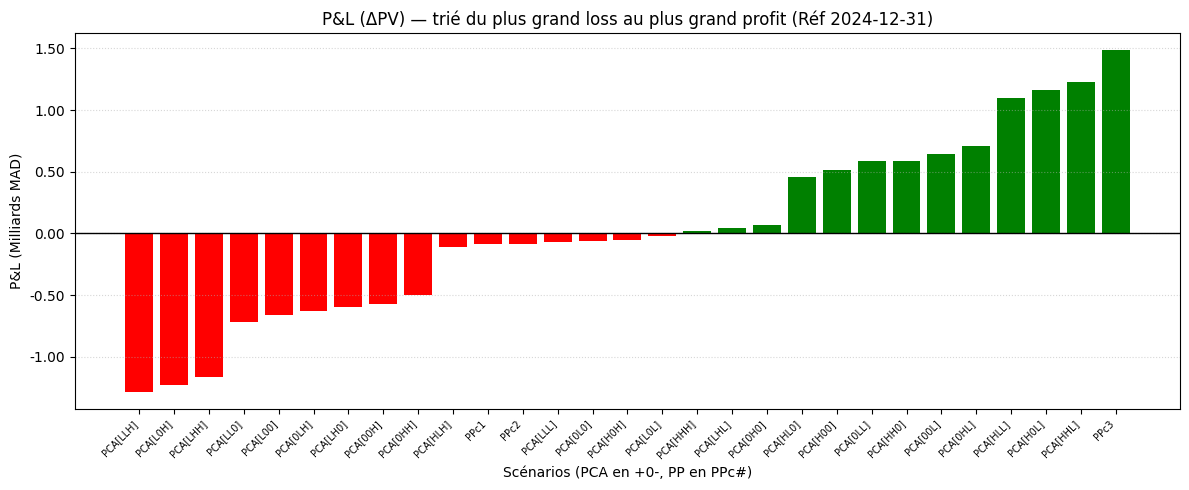

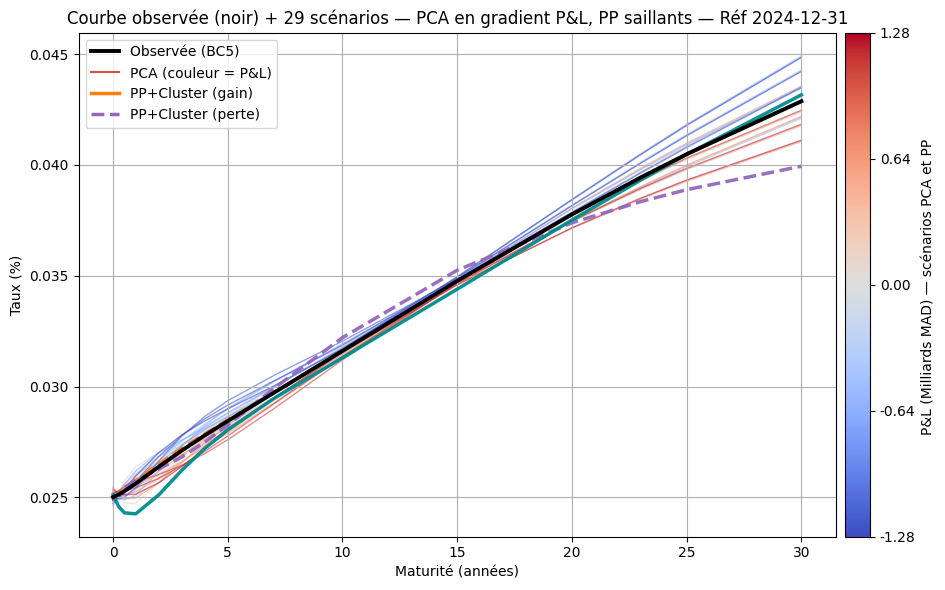

Figure sauvegardée : curves_stressed_colored_by_pnl_2024-12-31.png

=== Tableau P&L trié (worst -> best) ===


,Rang (P&L),Scénario,Type,État (+0-),P&L (MAD),P&L (lisible),P&L / PV_base (%),PV scénario (lisible),PV base (lisible)
0,1,PCA[LLH],PCA,—,-1.283479e+09,-1.283 Md MAD,-0.153844,832.989 Md MAD,834.273 Md MAD
1,2,PCA[L0H],PCA,—,-1.227033e+09,-1.227 Md MAD,-0.147078,833.046 Md MAD,834.273 Md MAD
2,3,PCA[LHH],PCA,—,-1.160349e+09,-1.160 Md MAD,-0.139085,833.112 Md MAD,834.273 Md MAD
3,4,PCA[LL0],PCA,—,-7.151113e+08,-715.111 M MAD,-0.085717,833.558 Md MAD,834.273 Md MAD
4,5,PCA[L00],PCA,—,-6.590505e+08,-659.050 M MAD,-0.078997,833.614 Md MAD,834.273 Md MAD
5,6,PCA[0LH],PCA,—,-6.272341e+08,-627.234 M MAD,-0.075183,833.645 Md MAD,834.273 Md MAD
6,7,PCA[LH0],PCA,—,-5.928073e+08,-592.807 M MAD,-0.071057,833.680 Md MAD,834.273 Md MAD
7,8,PCA[00H],PCA,—,-5.684557e+08,-568.456 M MAD,-0.068138,833.704 Md MAD,834.273 Md MAD
8,9,PCA[0HH],PCA,—,-4.990633e+08,-499.063 M MAD,-0.059820,833.774 Md MAD,834.273 Md MAD
9,10,PCA[HLH],PCA,—,-1.121702e+08,-112.170 M MAD,-0.013445,834.161 Md MAD,834.273 Md MAD


[OK] Export Excel: tableau_pnl_trie_from_curves_2024-12-31.xlsx (engine=openpyxl)

Fichiers exportés :
 - tableau_pnl_trie_from_curves_2024-12-31.csv
 - tableau_pnl_trie_from_curves_2024-12-31.xlsx
 - stressed_curves_2024-12-31.csv
 - curves_stressed_colored_by_pnl_2024-12-31.png


In [ ]:
# ============================================
# EXEMPLE D’UTILISATION — v3.1 (robuste, 1 seul plot des courbes)
# - Lit IR_MAD.xlsx et ZC_FIXED_INCOMES_MAD.xlsx
# - Construit scénarios labellisés (+0- pour PCA, PPc# pour PP)
# - Calcule PV_base, re-price les scénarios à partir des courbes stressées
# - Trie les P&L (worst -> best), affiche tableau, exporte CSV/Excel
# - Affiche 1 SEUL graphe de courbes: Observée (noir) + 29 stress
#     * Couleur = signe du P&L (vert=+ / rouge=-)
#     * Style   = PCA (—) vs PP+Cluster (--)
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

# ---------- Réglages ----------
IR_PATH        = "IR_MAD.xlsx"
PORT_PATH      = "ZC_FIXED_INCOMES_MAD.xlsx"
REFERENCE_DATE = "2024-12-31"
DAYCOUNT       = 365.25
RANDOM_STATE   = 42

# ---------- Helpers (auto-suffisant) ----------
def humanize_mad(x: float) -> str:
    x = float(x); absx = abs(x)
    if absx >= 1e9:  return f"{x/1e9:,.3f} Md MAD".replace(",", " ")
    if absx >= 1e6:  return f"{x/1e6:,.3f} M MAD".replace(",", " ")
    return f"{x:,.0f} MAD".replace(",", " ")

def ensure_decimal_arr(y: np.ndarray) -> np.ndarray:
    y = np.asarray(y, dtype=float)
    return y/100.0 if np.nanmedian(y) > 1.0 else y

def annual_coupon_schedule(maturity_date: pd.Timestamp,
                           ref_date: pd.Timestamp) -> list[pd.Timestamp]:
    maturity_date = pd.to_datetime(maturity_date)
    ref_date = pd.to_datetime(ref_date)
    if maturity_date <= ref_date: return []
    dates, d = [], maturity_date
    while d > ref_date:
        dates.append(d)
        d = d - pd.DateOffset(years=1)
    return sorted(dates)

def pv_bond_from_curve(row: pd.Series,
                       ref_date: pd.Timestamp,
                       m_cols: np.ndarray,
                       y_curve: np.ndarray,
                       daycount: float = DAYCOUNT) -> float:
    """Valorise une obligation à coupons annuels via (m_cols, y_curve)."""
    qty = float(row['Qty']); nominal = float(row['Nominal']); coup = float(row['Taux'])
    coup = coup/100.0 if coup > 1.0 else coup
    notional_total = nominal * qty
    pay_dates = annual_coupon_schedule(row['DateE'], ref_date)
    if not pay_dates: return 0.0
    cashflows = np.full(len(pay_dates), notional_total * coup, dtype=float)
    cashflows[-1] += notional_total
    m_years = np.array([(pd.to_datetime(d) - pd.to_datetime(ref_date)).days / daycount for d in pay_dates], dtype=float)
    order = np.argsort(m_cols)
    y_interp = np.interp(m_years, np.asarray(m_cols)[order], np.asarray(y_curve)[order])
    y_interp = ensure_decimal_arr(y_interp)
    df = np.exp(-y_interp * m_years)
    return float(np.sum(cashflows * df))

def _fallback_load_ir(path: str) -> pd.DataFrame:
    df = pd.read_excel(path)
    # index de dates
    if not np.issubdtype(df.iloc[:,0].dtype, np.datetime64):
        df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0], errors="coerce")
    df = df.set_index(df.columns[0])
    # colonnes = maturités (années)
    new_cols = []
    for c in df.columns:
        s = str(c).strip()
        s2 = (s.replace('Y','').replace('y','')
                .replace('yrs','').replace('Years','').replace('years','')
                .replace('Year','').replace('year',''))
        try:
            new_cols.append(float(s2))
        except Exception:
            if s.upper().endswith('M'):
                mm = float(s[:-1]); new_cols.append(mm/12.0)
            else:
                new_cols.append(s)
    df.columns = new_cols
    numeric_cols = [c for c in df.columns if isinstance(c, (int, float, np.floating))]
    df = df[numeric_cols].copy()
    df = df.sort_index()
    df = df.reindex(sorted(df.columns), axis=1)
    return df

# ---------- 1) Charger données ----------
try:
    IR_MAD = load_ir_mad(IR_PATH)  # si le bloc "fonctions" est chargé
except NameError:
    IR_MAD = _fallback_load_ir(IR_PATH)
portfolio_df = pd.read_excel(PORT_PATH)

# ---------- 2) Construire scénarios (labellisés) ----------
if 'build_bc5_scenarios_labeled' not in globals():
    raise RuntimeError("La fonction build_bc5_scenarios_labeled n'est pas définie. Exécute d'abord le bloc 'fonctions'.")

build = build_bc5_scenarios_labeled(IR_MAD, reference_date=REFERENCE_DATE, H=1, random_state=RANDOM_STATE)
m_cols          = build['m_cols']                 # maturités (années)
y_ref_bc5       = build['y_ref_bc5']              # courbe BC5 observée (date la + proche)
stressed_df     = build['stressed_df']            # 29 courbes stressées (index = labels)
scenario_meta   = build['scenario_meta']          # type, état (+0-)
ref_date_actual = build['reference_date_actual']  # date IR réelle la plus proche

# ---------- 3) PV_base ----------
PV_base = 0.0
for _, row in portfolio_df.iterrows():
    PV_base += pv_bond_from_curve(row, pd.to_datetime(REFERENCE_DATE), m_cols, y_ref_bc5, daycount=DAYCOUNT)

print("=== Valeur initiale du portefeuille (réf", REFERENCE_DATE, ") ===")
print("PV_base =", f"{PV_base:,.0f} MAD".replace(",", " "))
print("PV_base ≈", humanize_mad(PV_base))

# ---------- 4) PV scénarios & PnL ----------
scen_labels = list(stressed_df.index)
PV_scen_list, PnL_list = [], []
for lab in scen_labels:
    y_curve = stressed_df.loc[lab].values.astype(float)
    pv_sc = 0.0
    for _, row in portfolio_df.iterrows():
        pv_sc += pv_bond_from_curve(row, pd.to_datetime(REFERENCE_DATE), m_cols, y_curve, daycount=DAYCOUNT)
    PV_scen_list.append(pv_sc)
    PnL_list.append(pv_sc - PV_base)

df_total = pd.DataFrame({
    "PV_base_total": PV_base,
    "PV_scenario_total": PV_scen_list,
    "PnL_total": PnL_list
}, index=scen_labels)

# ---------- 5) Tri P&L (worst -> best) + figure bar ----------
# ---------- 5) Tri P&L (worst -> best) + figure bar (ticks plus lisibles) ----------
# ---------- 5) Tri P&L (worst -> best) + figure bar (Y en Milliards MAD) ----------
from matplotlib.ticker import FuncFormatter

# Tri (si pas déjà fait juste avant)
df_total_sorted = df_total.sort_values("PnL_total", ascending=True)

vals = df_total_sorted['PnL_total'].values
labs = df_total_sorted.index.tolist()
colors_bars = ['green' if x >= 0 else 'red' for x in vals]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(labs, vals, color=colors_bars)
ax.axhline(0.0, linewidth=1.0, color='black')

ax.set_title(f"P&L (ΔPV) — trié du plus grand loss au plus grand profit (Réf {REFERENCE_DATE})")
ax.set_xlabel("Scénarios (PCA en +0-, PP en PPc#)")

# ✅ Axe Y en Milliards MAD
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _pos: f"{y/1e9:,.2f}".replace(",", " ")))
ax.set_ylabel("P&L (Milliards MAD)")

# ✅ Ticks X plus petits et lisibles
for lab in ax.get_xticklabels():
    lab.set_fontsize(7)
    lab.set_rotation(45)
    lab.set_horizontalalignment('right')

ax.grid(axis='y', linestyle=':', alpha=0.5)
fig.tight_layout()
plt.show()


# ---------- 6) Courbes: Observée (noir) + 29 stress
# ---------- 6) Courbes: Observée (noir) + PCA (gradient P&L) + PP (3 couleurs saillantes)
# ---------- 6) Courbes: Observée (noir) + PCA (gradient P&L) + PP (3 couleurs saillantes)
# ---------- 6) Courbes: Observée (noir) + PCA (gradient P&L) + PP (3 couleurs saillantes)
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib import colormaps as cmx
from matplotlib import colors as mcolors
from pathlib import Path

OUT_DIR = Path(".")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_PATH = OUT_DIR / f"curves_stressed_colored_by_pnl_{REFERENCE_DATE}.png"

# Méta + P&L
meta_idx = 'label' if ('label' in scenario_meta.columns) else ('scenario_name' if 'scenario_name' in scenario_meta.columns else None)
scenario_meta_aligned_all = scenario_meta.set_index(meta_idx) if meta_idx else pd.DataFrame(index=df_total.index)
pnl_series = df_total['PnL_total']  # P&L par label (index identique à stressed_df)

# Reconnaissance PCA / PP (fallback heuristique si 'type' absent)
def is_pca(lbl: str) -> bool:
    if meta_idx and 'type' in scenario_meta_aligned_all.columns:
        t = scenario_meta_aligned_all.loc[lbl, 'type']
        if isinstance(t, str):
            return 'PCA' in t.upper()
    return str(lbl).startswith("PCA")

def is_pp(lbl: str) -> bool:
    if meta_idx and 'type' in scenario_meta_aligned_all.columns:
        t = scenario_meta_aligned_all.loc[lbl, 'type']
        if isinstance(t, str):
            return 'PP' in t.upper()
    return str(lbl).startswith("PPc")

pca_labels = [lab for lab in df_total.index if is_pca(lab)]
pp_labels  = [lab for lab in df_total.index if is_pp(lab)]

# Normalisation du gradient PCA (coolwarm) sur l'amplitude de P&L
max_abs = float(np.max(np.abs(pnl_series.loc[pca_labels]))) if len(pca_labels) else 1.0
if max_abs == 0.0:  # éviter division par 0
    max_abs = 1.0
norm = mcolors.Normalize(vmin=-max_abs, vmax=+max_abs)
cmap = cmx.get_cmap('coolwarm')  # API moderne (évite la dépréciation)

# Tracer d'abord les PCA (fins, alpha), puis PP (saillants)
pca_labels_sorted = sorted(pca_labels, key=lambda lab: abs(pnl_series.loc[lab]))

fig, ax = plt.subplots(figsize=(10, 6))

# Courbe observée: noir
ax.plot(m_cols, y_ref_bc5, color="black", linewidth=2.8, label="Observée (BC5)", zorder=5)

# PCA en gradient (bleu↔orange selon P&L)
for lab in pca_labels_sorted:
    pnl = float(pnl_series.loc[lab])
    col = cmap(norm(pnl))
    ax.plot(m_cols,
            stressed_df.loc[lab].values.astype(float),
            color=col, linestyle='-', linewidth=1.0, alpha=0.60, zorder=1)

# PP+Cluster: couleurs distinctes, épaisses; solide si gain / pointillé si perte
pp_palette = ['#FF7F0E', '#9467BD', '#008B8B']  # orange, violet, teal
for i, lab in enumerate(pp_labels):
    pnl = float(pnl_series.loc[lab])
    ls  = '-' if pnl >= 0 else '--'
    col = pp_palette[i % len(pp_palette)]
    ax.plot(m_cols,
            stressed_df.loc[lab].values.astype(float),
            color=col, linestyle=ls, linewidth=2.5, alpha=0.95, zorder=3)

# Légende compacte
legend_handles = [
    Line2D([0],[0], color="black", lw=2.8, label="Observée (BC5)"),
    Line2D([0],[0], color=cmap(norm(+max_abs*0.8)), lw=1.5, linestyle='-',  label="PCA (couleur = P&L)"),
    Line2D([0],[0], color=pp_palette[0],           lw=2.5, linestyle='-',  label="PP+Cluster (gain)"),
    Line2D([0],[0], color=pp_palette[1],           lw=2.5, linestyle='--', label="PP+Cluster (perte)"),
]
ax.legend(handles=legend_handles, loc="best")

# Colorbar en Milliards MAD (seulement si PCA présents)
if len(pca_labels):
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, pad=0.01)

    # Ticks en milliards
    ticks_mad = np.linspace(-max_abs, max_abs, 5)
    cb.set_ticks(ticks_mad)
    cb.set_ticklabels([f"{t/1e9:.2f}" for t in ticks_mad])
    cb.set_label("P&L (Milliards MAD) — scénarios PCA et PP ")

ax.set_xlabel("Maturité (années)")
ax.set_ylabel("Taux (%)")
ax.set_title(f"Courbe observée (noir) + 29 scénarios — PCA en gradient P&L, PP saillants — Réf {REFERENCE_DATE}")
ax.grid(True)

fig.tight_layout()
fig.savefig(FIG_PATH, dpi=160)
plt.show()

print("Figure sauvegardée :", FIG_PATH)


# ---------- 7) Tableau P&L trié + méta scénarios ----------
def pretty_state(val):
    if isinstance(val, (list, tuple)):
        mapch = {-1:"-", 0:"0", 1:"+"}
        try:    return "".join(mapch.get(int(x), "?") for x in val)
        except: return "—"
    return "—"

scenario_meta_for_join = scenario_meta.set_index(meta_idx).reindex(df_total_sorted.index) if meta_idx else pd.DataFrame(index=df_total_sorted.index)
out = pd.DataFrame({
    "Rang (P&L)": np.arange(1, len(df_total_sorted)+1),
    "Scénario": df_total_sorted.index,
    "Type": scenario_meta_for_join["type"].values if "type" in scenario_meta_for_join.columns else ["?"]*len(df_total_sorted),
    "État (+0-)": [pretty_state(x) if "state" in scenario_meta_for_join.columns else "—"
                   for x in (scenario_meta_for_join["state"].values if "state" in scenario_meta_for_join.columns else [None]*len(df_total_sorted))],
    "P&L (MAD)": df_total_sorted["PnL_total"].values,
    "P&L (lisible)": [humanize_mad(x) for x in df_total_sorted["PnL_total"].values],
    "P&L / PV_base (%)": df_total_sorted["PnL_total"].values / PV_base * 100.0,
    "PV scénario (lisible)": [humanize_mad(x) for x in df_total_sorted["PV_scenario_total"].values],
    "PV base (lisible)": [humanize_mad(PV_base)] * len(df_total_sorted),
}).sort_values("Rang (P&L)").reset_index(drop=True)

print("\n=== Tableau P&L trié (worst -> best) ===")
try:
    display(out.head(10))
except:
    print(out.head(10).to_string(index=False))

# ---------- 8) Exports ----------


def save_excel_robust(df: pd.DataFrame, path: str, sheet_name: str = "P&L (trié)"):
    """
    Essaie d'exporter en Excel avec xlsxwriter, sinon openpyxl.
    Si aucun moteur n'est dispo, fallback en CSV (même nom, extension .csv).
    Retourne le chemin du fichier effectivement écrit.
    """
    engine = None
    try:
        import xlsxwriter  # noqa: F401
        engine = "xlsxwriter"
    except Exception:
        try:
            import openpyxl  # noqa: F401
            engine = "openpyxl"
        except Exception:
            engine = None

    if engine is None:
        csv_path = str(Path(path).with_suffix(".csv"))
        df.to_csv(csv_path, index=False)
        print(f"[WARN] Aucun moteur Excel dispo. Export CSV uniquement: {csv_path}")
        return csv_path

    with pd.ExcelWriter(path, engine=engine) as writer:
        df.to_excel(writer, index=False, sheet_name=sheet_name)

        # Ajuste les largeurs si possible
        if engine == "xlsxwriter":
            ws = writer.sheets[sheet_name]
            ws.set_column('A:A', 12)  # Rang
            ws.set_column('B:B', 18)  # Scénario
            ws.set_column('C:C', 14)  # Type
            ws.set_column('D:D', 12)  # État
            ws.set_column('E:E', 16)  # P&L (MAD)
            ws.set_column('F:F', 18)  # P&L (lisible)
            ws.set_column('G:G', 18)  # P&L / PV_base (%)
            ws.set_column('H:I', 22)  # PV scénario / PV base
        elif engine == "openpyxl":
            from openpyxl.utils import get_column_letter
            ws = writer.sheets[sheet_name]
            widths = [12,18,14,12,16,18,18,22,22]
            for i, w in enumerate(widths, start=1):
                ws.column_dimensions[get_column_letter(i)].width = w

    print(f"[OK] Export Excel: {path} (engine={engine})")
    return path
# ---------- 8) Exports (robustes) ----------
OUT_DIR = Path(".")  # répertoire courant
OUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PNL   = OUT_DIR / f"tableau_pnl_trie_from_curves_{REFERENCE_DATE}.csv"
XLSX_PNL  = OUT_DIR / f"tableau_pnl_trie_from_curves_{REFERENCE_DATE}.xlsx"
CSV_CURVE = OUT_DIR / f"stressed_curves_{REFERENCE_DATE}.csv"
FIG_PATH  = OUT_DIR / f"curves_stressed_colored_by_pnl_{REFERENCE_DATE}.png"

# tableaux
out.to_csv(CSV_PNL, index=False)
excel_written_path = save_excel_robust(out, str(XLSX_PNL))  # -> xlsx ou fallback csv

# courbes stressées (numériques)
stressed_df.to_csv(CSV_CURVE)

print("\nFichiers exportés :")
print(" -", CSV_PNL)
print(" -", excel_written_path)
print(" -", CSV_CURVE)
print(" -", FIG_PATH)



# ANNEXE B

In [ ]:
# -*- coding: utf-8 -*-
"""
Comparaison Nelson–Siegel (NS) vs Björk–Christensen (BC5) sur IR_MAD.
- Calibrage quotidien par moindres carrés non linéaires
- RMSE / MAE / R2 par date
- Graphiques:
  * Histogrammes RMSE (ns_rmse_hist.png, bc5_rmse_hist.png)
  * Séries temporelles RMSE (ns_rmse_timeseries.png, bc5_rmse_timeseries.png)
  * Observé vs Ajusté: meilleure/médiane/pire date (ns_obs_fit_triptych_*.png, bc5_*.png)
  * Résidus moyens par maturité (ns_mean_residuals_by_maturity.png, bc5_*.png)
  * Boîte à moustaches RMSE comparée (rmse_boxplot_ns_vs_bc5.png)
Sauvegarde des paramètres et métriques en CSV.
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# ========= 0) CONFIG =========
INPUT_FILE = "IR_MAD.xlsx"   # ou "IR_MAD.xlsx"
DATE_COL = "Date"

# Maturités (années) selon ta base (18 points)
MATURITIES_Y = np.array([
    0.0027, 0.0192, 0.2491, 0.4983, 0.9856, 0.9993, 1.9986, 2.9979, 4.0000,
    4.9993, 6.9979, 7.2717, 9.9986, 14.9979, 20.0000, 22.9870, 24.9993, 29.9986
], dtype=float)

OUTPUT_DIR = "out_ns_bc5"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ========= 1) LECTURE DES DONNÉES =========
def load_ir_mad(path):
    if path.lower().endswith(".xlsx"):
        df = pd.read_excel(path)
    else:
        df = pd.read_csv(path)
    # Harmonisation des colonnes num/maturités
    cols = [c for c in df.columns if c != DATE_COL]
    # si les colonnes sont des maturités, on les utilise; sinon on garde l'ordre et on mappe MATURITIES_Y
    if len(cols) != len(MATURITIES_Y):
        raise ValueError(f"Nombre de colonnes ({len(cols)}) != {len(MATURITIES_Y)} maturités attendues.")
    # Convertir Date
    if DATE_COL in df.columns:
        df[DATE_COL] = pd.to_datetime(df[DATE_COL])
        df = df.sort_values(DATE_COL).reset_index(drop=True)
    else:
        df.insert(0, DATE_COL, pd.date_range("2000-01-01", periods=len(df), freq="D"))
    # Extraire matrice des taux
    rates = df[cols].to_numpy(dtype=float)  # shape: (n_dates, n_mats)
    return df[[DATE_COL]].copy(), rates, np.array(cols)

dates_df, RATES, rate_cols = load_ir_mad(INPUT_FILE)
n_dates, n_mats = RATES.shape
assert n_mats == len(MATURITIES_Y)

# ========= 2) MODÈLES: NS & BC5 =========
def nelson_siegel_yield(beta1, beta2, beta3, lam, m):
    """Courbe NS: y(m) = b1 + b2*(1-exp(-lam m))/(lam m) + b3*((1-exp(-lam m))/(lam m) - exp(-lam m))"""
    m = np.asarray(m, dtype=float)
    # éviter division par zéro
    x = lam * m
    with np.errstate(divide='ignore', invalid='ignore'):
        L1 = np.where(x == 0.0, 1.0, (1.0 - np.exp(-x)) / x)
    L2 = L1 - np.exp(-x)
    return beta1 + beta2 * L1 + beta3 * L2

def bc5_yield(beta, lam1, lam2, m):
    """
    Björk–Christensen 5 facteurs (type Svensson généralisé):
    y(m) = b1 + b2*L1_1 + b3*L2_1 + b4*L1_2 + b5*L2_2,
    avec L1_k = (1-exp(-lam_k m))/(lam_k m), L2_k = L1_k - exp(-lam_k m).
    beta = (b1,b2,b3,b4,b5)
    """
    b1, b2, b3, b4, b5 = beta
    m = np.asarray(m, dtype=float)
    x1 = lam1 * m
    x2 = lam2 * m
    with np.errstate(divide='ignore', invalid='ignore'):
        L1_1 = np.where(x1 == 0.0, 1.0, (1.0 - np.exp(-x1)) / x1)
        L2_1 = L1_1 - np.exp(-x1)
        L1_2 = np.where(x2 == 0.0, 1.0, (1.0 - np.exp(-x2)) / x2)
        L2_2 = L1_2 - np.exp(-x2)
    return b1 + b2 * L1_1 + b3 * L2_1 + b4 * L1_2 + b5 * L2_2

# ========= 3) CALIBRAGE PAR DATE =========
def fit_ns(y_obs, m, start=None, bounds=None, max_nfev=4000):
    # init par défaut
    if start is None:
        # start b1=longue maturité, b2/pente via diff, b3 petit, lam ~ 0.5
        b1_0 = float(y_obs[-1])
        b2_0 = float(y_obs[0] - y_obs[-1])
        b3_0 = 0.0
        lam0 = 0.5
        start = np.array([b1_0, b2_0, b3_0, lam0], dtype=float)
    if bounds is None:
        # lambdas > 1e-6 pour stabilité; betas libres
        lb = np.array([-np.inf, -np.inf, -np.inf, 1e-6])
        ub = np.array([ np.inf,  np.inf,  np.inf, 50.0])
        bounds = (lb, ub)

    def resid(p):
        b1, b2, b3, lam = p
        return nelson_siegel_yield(b1, b2, b3, lam, m) - y_obs

    res = least_squares(resid, start, bounds=bounds, max_nfev=max_nfev)
    p = res.x
    y_hat = nelson_siegel_yield(*p, m)
    return p, y_hat, res

def fit_bc5(y_obs, m, start=None, bounds=None, max_nfev=8000):
    if start is None:
        # init raisonnable: b1 ~ long end, b2/b3/b4/b5 petits, lam1 ~ 0.5, lam2 ~ 0.05
        beta0 = np.array([float(y_obs[-1]), 0.0, 0.0, 0.0, 0.0])
        lam1_0 = 0.5
        lam2_0 = 0.05
        start = np.concatenate([beta0, [lam1_0, lam2_0]])
    if bounds is None:
        lb = np.array([-np.inf, -np.inf, -np.inf, -np.inf, -np.inf, 1e-6, 1e-6])
        ub = np.array([ np.inf,  np.inf,  np.inf,  np.inf,  np.inf, 50.0, 50.0])
        bounds = (lb, ub)

    def resid(p):
        beta = p[:5]
        lam1, lam2 = p[5], p[6]
        return bc5_yield(beta, lam1, lam2, m) - y_obs

    res = least_squares(resid, start, bounds=bounds, max_nfev=max_nfev)
    p = res.x
    y_hat = bc5_yield(p[:5], p[5], p[6], m)
    return p, y_hat, res

def metrics(y_true, y_pred):
    err = y_pred - y_true
    rmse = np.sqrt(np.mean(err**2))
    mae  = np.mean(np.abs(err))
    ss_res = np.sum(err**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return rmse, mae, r2, err

# Boucle principale
ns_params = []
bc5_params = []
ns_rmse, ns_mae, ns_r2 = [], [], []
bc5_rmse, bc5_mae, bc5_r2 = [], [], []
ns_residuals = np.zeros_like(RATES)
bc5_residuals = np.zeros_like(RATES)

for t in range(n_dates):
    y = RATES[t, :]
    # Fit NS
    p_ns, yhat_ns, _ = fit_ns(y, MATURITIES_Y)
    r_ns, a_ns, r2_ns, e_ns = metrics(y, yhat_ns)
    ns_params.append(p_ns)
    ns_rmse.append(r_ns); ns_mae.append(a_ns); ns_r2.append(r2_ns)
    ns_residuals[t, :] = e_ns

    # Fit BC5
    p_bc5, yhat_bc5, _ = fit_bc5(y, MATURITIES_Y)
    r_bc5, a_bc5, r2_bc5, e_bc5 = metrics(y, yhat_bc5)
    bc5_params.append(p_bc5)
    bc5_rmse.append(r_bc5); bc5_mae.append(a_bc5); bc5_r2.append(r2_bc5)
    bc5_residuals[t, :] = e_bc5

ns_params = np.array(ns_params)              # (n_dates, 4)
bc5_params = np.array(bc5_params)            # (n_dates, 7)
ns_rmse = np.array(ns_rmse); ns_mae = np.array(ns_mae); ns_r2 = np.array(ns_r2)
bc5_rmse = np.array(bc5_rmse); bc5_mae = np.array(bc5_mae); bc5_r2 = np.array(bc5_r2)

# ========= 4) EXPORT MÉTRIQUES & PARAMS =========
out_metrics = dates_df.copy()
out_metrics["ns_rmse"] = ns_rmse
out_metrics["ns_mae"]  = ns_mae
out_metrics["ns_r2"]   = ns_r2
out_metrics["bc5_rmse"] = bc5_rmse
out_metrics["bc5_mae"]  = bc5_mae
out_metrics["bc5_r2"]   = bc5_r2
out_metrics.to_csv(os.path.join(OUTPUT_DIR, "metrics_ns_bc5.csv"), index=False)

ns_cols = ["ns_beta1","ns_beta2","ns_beta3","ns_lambda"]
out_ns = dates_df.copy()
for i,c in enumerate(ns_cols):
    out_ns[c] = ns_params[:, i]
out_ns.to_csv(os.path.join(OUTPUT_DIR, "params_ns.csv"), index=False)

bc5_cols = ["bc5_b1","bc5_b2","bc5_b3","bc5_b4","bc5_b5","bc5_lambda1","bc5_lambda2"]
out_bc5 = dates_df.copy()
for i,c in enumerate(bc5_cols):
    out_bc5[c] = bc5_params[:, i]
out_bc5.to_csv(os.path.join(OUTPUT_DIR, "params_bc5.csv"), index=False)

# ========= 5) FIGURES =========
def save_hist(data, title, fname, bins=40):
    plt.figure(figsize=(7.5, 4.0))
    plt.hist(data*1e4, bins=bins)  # en bps si data en taux (1 = 100%)
    plt.title(title + " (bps)")
    plt.xlabel("RMSE (bps)"); plt.ylabel("Fréquence")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.close()

def save_timeseries(dates, data, title, fname):
    plt.figure(figsize=(9, 4))
    plt.plot(dates, data*1e4)  # bps
    plt.title(title + " (bps)")
    plt.xlabel("Date"); plt.ylabel("RMSE (bps)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.close()

# Hist + timeseries RMSE
save_hist(ns_rmse, "NS - Distribution RMSE", "ns_rmse_hist.png")
save_hist(bc5_rmse, "BC5 - Distribution RMSE", "bc5_rmse_hist.png")
save_timeseries(dates_df[DATE_COL], ns_rmse, "NS - RMSE journalier", "ns_rmse_timeseries.png")
save_timeseries(dates_df[DATE_COL], bc5_rmse, "BC5 - RMSE journalier", "bc5_rmse_timeseries.png")

# Boîte à moustaches comparée
plt.figure(figsize=(6,4))
plt.boxplot([ns_rmse*1e4, bc5_rmse*1e4], labels=["NS","BC5"])
plt.ylabel("RMSE (bps)")
plt.title("Comparaison RMSE (NS vs BC5)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "rmse_boxplot_ns_vs_bc5.png"), dpi=150)
plt.close()

# Observé vs Ajusté — sélectionner meilleure/médiane/pire dates par RMSE
def triptych_obs_fit(model_name, rmse_vec, params, y_mat, m, fname_prefix): # Removed yield_func
    idx_sorted = np.argsort(rmse_vec)
    pick = [idx_sorted[0], idx_sorted[len(idx_sorted)//2], idx_sorted[-1]]
    labels = ["best","median","worst"]
    for i, idx in enumerate(pick):
        y = y_mat[idx,:]
        if model_name == "NS":
            b1,b2,b3,lam = params[idx,:]
            yhat = nelson_siegel_yield(b1,b2,b3,lam,m)
        else:
            b1,b2,b3,b4,b5,lam1,lam2 = params[idx,:]
            yhat = bc5_yield([b1,b2,b3,b4,b5],lam1,lam2,m)
        plt.figure(figsize=(6,4))
        plt.plot(m, y*100, marker='o', label="Observé")
        plt.plot(m, yhat*100, marker='x', label="Ajusté")
        plt.xlabel("Maturité (années)"); plt.ylabel("Taux (%)")
        plt.title(f"{model_name} — {labels[i]} (RMSE={rmse_vec[idx]*1e4:.2f} bps)\nDate={pd.to_datetime(dates_df.iloc[idx][DATE_COL]).date()}")
        plt.legend()
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, f"{fname_prefix}_{labels[i]}.png"), dpi=150)
        plt.close()

triptych_obs_fit("NS", ns_rmse, ns_params, RATES, MATURITIES_Y, "ns_obs_fit_triptych")
triptych_obs_fit("BC5", bc5_rmse, bc5_params, RATES, MATURITIES_Y, "bc5_obs_fit_triptych")

# Résidus moyens par maturité
def mean_residual_by_maturity(residuals, m, title, fname):
    mean_res = residuals.mean(axis=0)
    plt.figure(figsize=(6.5,4))
    plt.axhline(0, linewidth=1)
    plt.plot(m, mean_res*1e4, marker='o')
    plt.xlabel("Maturité (années)"); plt.ylabel("Résidu moyen (bps)")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.close()

mean_residual_by_maturity(ns_residuals, MATURITIES_Y, "NS — Résidus moyens par maturité", "ns_mean_residuals_by_maturity.png")
mean_residual_by_maturity(bc5_residuals, MATURITIES_Y, "BC5 — Résidus moyens par maturité", "bc5_mean_residuals_by_maturity.png")

print("Terminé. Fichiers écrits dans:", OUTPUT_DIR)

/tmp/ipython-input-546232741.py:223: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([ns_rmse*1e4, bc5_rmse*1e4], labels=["NS","BC5"])


Terminé. Fichiers écrits dans: out_ns_bc5


In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

# 1) Charger la base de métriques
csv_path = Path("metrics_ns_bc5.csv")  # ajuste le chemin si besoin
df = pd.read_csv(csv_path)
df['Date'] = pd.to_datetime(df['Date'])

# 2) Colonnes attendues : ns_rmse, bc5_rmse, ns_mae, bc5_mae (déjà présentes)
#    Dérivés utiles : différences (NS - BC5) > 0 => BC5 meilleur
df['rmse_diff'] = df['ns_rmse'] - df['bc5_rmse']
df['mae_diff']  = df['ns_mae']  - df['bc5_mae']

# 3) Résumé quanti
summary = pd.DataFrame({
    "metric": ["RMSE", "MAE"],
    "NS_mean": [df['ns_rmse'].mean(), df['ns_mae'].mean()],
    "BC5_mean": [df['bc5_rmse'].mean(), df['bc5_mae'].mean()],
    "NS_median": [df['ns_rmse'].median(), df['ns_mae'].median()],
    "BC5_median": [df['bc5_rmse'].median(), df['bc5_mae'].median()],
    "Share_BC5_better": [
        (df['rmse_diff']>0).mean(),
        (df['mae_diff']>0).mean()
    ]
})
summary_path = Path("ns_bc5_summary.csv")
summary.to_csv(summary_path, index=False)
print(summary)

counts = {
    "RMSE: dates BC5 better": int((df['rmse_diff']>0).sum()),
    "RMSE: dates NS better": int((df['rmse_diff']<0).sum()),
    "RMSE: ties": int((df['rmse_diff']==0).sum()),
    "MAE: dates BC5 better": int((df['mae_diff']>0).sum()),
    "MAE: dates NS better": int((df['mae_diff']<0).sum()),
    "MAE: ties": int((df['mae_diff']==0).sum()),
}
print(counts)

# 4) Figures comparatives
figdir = Path("fig_ns_vs_bc5")
figdir.mkdir(parents=True, exist_ok=True)

# (a) Moyennes par modèle
for metric in ["rmse","mae"]:
    plt.figure()
    means = [df[f'ns_{metric}'].mean(), df[f'bc5_{metric}'].mean()]
    plt.bar(["NS","BC5"], means)
    plt.title(f"Mean {metric.upper()} – NS vs BC5")
    plt.ylabel(metric.upper())
    plt.tight_layout()
    plt.savefig(figdir / f"bar_mean_{metric}.png", dpi=200)
    plt.close()

# (b) Boxplots distributions
for metric in ["rmse","mae"]:
    plt.figure()
    data = [df[f'ns_{metric}'].values, df[f'bc5_{metric}'].values]
    plt.boxplot(data, labels=["NS","BC5"], showmeans=True)
    plt.title(f"{metric.upper()} Distribution – NS vs BC5")
    plt.ylabel(metric.upper())
    plt.tight_layout()
    plt.savefig(figdir / f"box_{metric}.png", dpi=200)
    plt.close()

# (c) Histogrammes des deltas (NS - BC5)
for metric in ["rmse","mae"]:
    plt.figure()
    plt.hist(df[f'ns_{metric}'] - df[f'bc5_{metric}'], bins=30)
    plt.axvline(0, linestyle="--")
    plt.title(f"Histogram of {metric.UPPER() if hasattr(str,'UPPER') else metric.upper()} Difference (NS - BC5)")
    plt.xlabel("Difference (>0 means BC5 better)")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.savefig(figdir / f"hist_diff_{metric}.png", dpi=200)
    plt.close()

# (d) Nuages de points + diagonale 45°
for metric in ["rmse","mae"]:
    plt.figure()
    x = df[f'ns_{metric}'].values
    y = df[f'bc5_{metric}'].values
    plt.scatter(x, y, s=12, alpha=0.6)
    lo = float(min(np.min(x), np.min(y)))
    hi = float(max(np.max(x), np.max(y)))
    plt.plot([lo,hi],[lo,hi], linestyle="--")
    plt.title(f"NS vs BC5 {metric.upper()} (45° line)")
    plt.xlabel(f"NS {metric.upper()}")
    plt.ylabel(f"BC5 {metric.upper()}")
    plt.tight_layout()
    plt.savefig(figdir / f"scatter_{metric}.png", dpi=200)
    plt.close()

# (e) Séries temporelles des différences
plt.figure()
plt.plot(df['Date'], df['rmse_diff'])
plt.axhline(0, linestyle="--")
plt.title("Time Series of RMSE Difference (NS - BC5)")
plt.xlabel("Date"); plt.ylabel("RMSE Difference")
plt.tight_layout()
plt.savefig(figdir / "ts_rmse_diff.png", dpi=200)
plt.close()

plt.figure()
plt.plot(df['Date'], df['mae_diff'])
plt.axhline(0, linestyle="--")
plt.title("Time Series of MAE Difference (NS - BC5)")
plt.xlabel("Date"); plt.ylabel("MAE Difference")
plt.tight_layout()
plt.savefig(figdir / "ts_mae_diff.png", dpi=200)
plt.close()

print("Figures écrites dans:", figdir)
print("Résumé CSV:", summary_path)


  metric   NS_mean  BC5_mean  NS_median  BC5_median  Share_BC5_better
0   RMSE  0.000609  0.000233   0.000438    0.000186           0.99938
1    MAE  0.000493  0.000181   0.000361    0.000146           0.99318
{'RMSE: dates BC5 better': 1612, 'RMSE: dates NS better': 1, 'RMSE: ties': 0, 'MAE: dates BC5 better': 1602, 'MAE: dates NS better': 11, 'MAE: ties': 0}


/tmp/ipython-input-3910730645.py:60: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=["NS","BC5"], showmeans=True)
/tmp/ipython-input-3910730645.py:60: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=["NS","BC5"], showmeans=True)


Figures écrites dans: fig_ns_vs_bc5
Résumé CSV: ns_bc5_summary.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Charger la base
csv_path = "out_ns_bc5/metrics_ns_bc5.csv"
df = pd.read_csv(csv_path)

# Créer dossier img si n’existe pas
os.makedirs("img", exist_ok=True)

# Figure 1 — Moyenne RMSE comparée
means = df[['ns_rmse', 'bc5_rmse']].mean()
plt.figure(figsize=(6,4))
means.plot(kind='bar', color=['skyblue','orange'])
plt.ylabel("Erreur quadratique moyenne (RMSE)")
plt.title("Erreur moyenne de calibration : Nelson–Siegel vs BC5")
plt.xticks(rotation=0)
plt.savefig("img/F1_bar_means.png", dpi=300, bbox_inches='tight')
plt.close()

# Figure 2 — Histogramme des différences
plt.figure(figsize=(6,4))
diff = df['ns_rmse'] - df['bc5_rmse']
plt.hist(diff, bins=40, color="purple", alpha=0.7)
plt.axvline(diff.mean(), color="red", linestyle="--", label=f"Moyenne = {diff.mean():.4f}")
plt.xlabel("RMSE_NS - RMSE_BC5")
plt.ylabel("Fréquence")
plt.title("Histogramme des écarts de RMSE (NS - BC5)")
plt.legend()
plt.savefig("img/F2_hist_rmse_diff.png", dpi=300, bbox_inches='tight')
plt.close()

# Figure 3 — Nuage de points (scatter)
plt.figure(figsize=(6,6))
plt.scatter(df['ns_rmse'], df['bc5_rmse'], alpha=0.6, color="teal")
plt.plot([df['ns_rmse'].min(), df['ns_rmse'].max()],
         [df['ns_rmse'].min(), df['ns_rmse'].max()],
         'r--', label="Égalité")
plt.xlabel("RMSE Nelson–Siegel")
plt.ylabel("RMSE BC5")
plt.title("Comparaison des calibrations individuelles")
plt.legend()
plt.savefig("img/F3_scatter_rmse.png", dpi=300, bbox_inches='tight')
plt.close()

# 6

# Nouvelle section

Tailles après construction:
Y : (1613, 18) LIQ : (1613, 18) CDS : (1613, 18)
Dates (Y) de 2020-10-28 00:00:00 à 2025-03-28 00:00:00


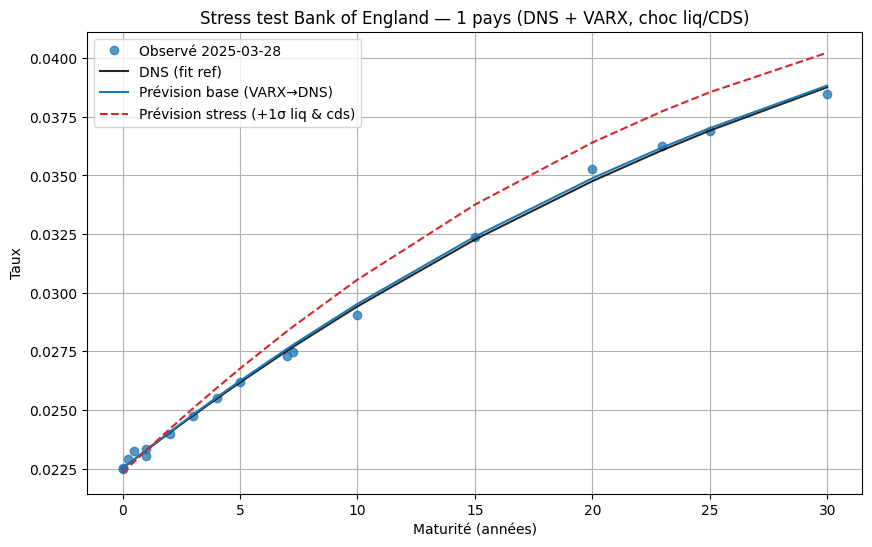

β̂(ref) : {'L': np.float64(-0.06009341522379021), 'S': np.float64(0.0825957766493669), 'C': np.float64(0.2008038570930018)}
β̂_pred_base : {'L': np.float64(-0.07350352231647012), 'S': np.float64(0.09601004244808409), 'C': np.float64(0.21652554380120725)}
β̂_pred_stress : {'L': np.float64(-0.17603039139502194), 'S': np.float64(0.1983489731008236), 'C': np.float64(0.343689784162457)}

Δcourbe (stress - base) par maturité :
0.002738    -0.000187
0.019165    -0.000185
0.249144    -0.000147
0.498289    -0.000108
0.985626    -0.000031
0.999316    -0.000029
1.998631     0.000122
2.997947     0.000264
4.000000     0.000398
4.999316     0.000523
6.997947     0.000750
7.271732     0.000779
9.998631     0.001033
14.997947    0.001361
20.000000    0.001521
22.986995    0.001544
24.999316    0.001531
29.998631    0.001403
dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ================================
# 0) Paramètres et maturités
# ================================
maturites_list = [
    0.002737850787132101, 0.01916495550992471, 0.2491444216290212,
    0.4982888432580425, 0.9856262833675564, 0.999315537303217,
    1.998631074606434, 2.997946611909651, 4.0,
    4.999315537303217, 6.997946611909651, 7.271731690622861,
    9.998631074606434, 14.99794661190965, 20.0,
    22.98699520876112, 24.99931553730322, 29.99863107460643
]
mats = np.array(maturites_list, dtype=float)
lambda_fixed = 0.01317662   # ta valeur globale
ref_date = None             # None -> utilise la dernière date

# Positions utiles (0-based) pour court/long terme
short_idx = 4   # ~1 an (M5)
long_idx  = 12  # ~10 ans (M13 ~ 9.9986)

# ================================
# 1) Utilitaires Nelson–Siegel
# ================================
def ns_loadings(mats, lambd):
    mats = np.asarray(mats, dtype=float)
    term1 = (1 - np.exp(-lambd * mats)) / (lambd * mats)
    term2 = term1 - np.exp(-lambd * mats)
    return np.column_stack([np.ones_like(mats), term1, term2])  # [N,3] -> [L,S,C]

def estimate_dns_factors_ols(y_vec, mats, lambd):
    X = ns_loadings(mats, lambd)  # [N,3]
    beta, *_ = np.linalg.lstsq(X, y_vec, rcond=None)
    return beta  # [L,S,C]

def rebuild_yield_curve(mats, beta, lambd):
    return ns_loadings(mats, lambd) @ beta  # [N]

# ================================
# 2) Helpers robustes pour aligner/reconstruire LIQ/CDS
# ================================
def _ensure_datetime_index(df):
    """Convertit 'Date' en index datetime si présent; sinon tente to_datetime sur l'index."""
    if isinstance(df.index, pd.RangeIndex) and 'Date' in df.columns:
        df = df.copy()
        df['Date'] = pd.to_datetime(df['Date'])
        df = df.set_index('Date')
        return df
    # Sinon on tente de convertir l'index en datetime
    if not np.issubdtype(df.index.dtype, np.datetime64):
        try:
            df = df.copy()
            df.index = pd.to_datetime(df.index)
        except Exception:
            pass
    return df

def _columns_as_positions(df, target_ncols):
    """
    Force les colonnes à être 'M1'..'Mn' par position.
    Si df a moins de colonnes que target_ncols, on duplique la dernière colonne.
    Si df a plus, on tronque.
    """
    df = df.copy()
    if df.shape[1] == 0:
        # vide: on laisse tel quel (sera reconstruit ailleurs)
        return df
    if df.shape[1] < target_ncols:
        last = df.iloc[:, [-1]].copy()
        reps = target_ncols - df.shape[1]
        add = pd.concat([last]*reps, axis=1)
        df = pd.concat([df, add], axis=1)
    elif df.shape[1] > target_ncols:
        df = df.iloc[:, :target_ncols]
    df.columns = [f"M{i+1}" for i in range(target_ncols)]
    return df

def _try_align_to(Y_idx, df_source, how="time"):
    """
    Reindexe df_source sur Y_idx en évitant KeyError:
    - interpolation 'time' si possible, puis ffill/bfill.
    """
    df = df_source.copy()
    # Si déjà exactement les mêmes index:
    if df.index.equals(Y_idx):
        return df
    # On reindexe
    df = df.reindex(Y_idx)
    # Interpolation temporelle si possible (sinon no-op)
    try:
        df = df.interpolate(method="time")
    except Exception:
        pass
    # ffill/bfill pour boucher les trous restants
    df = df.ffill().bfill()
    return df

def _build_liq_proxy_from_Y(Y):
    """Proxy LIQ: rolling std(22 jours) sur chaque maturité."""
    liq = Y.rolling(22, min_periods=5).std()
    # s'il reste des NaN au début, complète par 0
    return liq.fillna(0.0)

def _build_cds_proxy_from_Y(Y):
    """Proxy CDS: spread (long - court) répliqué sur toutes les colonnes."""
    spread = Y.iloc[:, long_idx] - Y.iloc[:, short_idx]
    cds = pd.DataFrame({c: spread.values for c in Y.columns}, index=Y.index)
    return cds

# ================================
# ================================
# 3) Mise en forme / alignement — VERSION ROBUSTE
# ================================
def _ensure_datetime_index(df):
    if 'Date' in df.columns:
        df = df.copy()
        df['Date'] = pd.to_datetime(df['Date'])
        df = df.set_index('Date')
    else:
        # tente conversion de l'index en datetime (au cas où)
        try:
            df = df.copy()
            df.index = pd.to_datetime(df.index)
        except Exception:
            pass
    return df.sort_index()

# Load the data into df_courbe_taux
try:
    df_courbe_taux = pd.read_excel('sample_data/IR_MAD.xlsx')
except FileNotFoundError:
    print("Erreur : Le fichier spécifié est introuvable. Veuillez vérifier le chemin d'accès.")
except Exception as e:
    print(f"Une erreur s'est produite lors de la lecture du fichier Excel : {e}")


# df_courbe_taux est obligatoire
df_courbe_taux = _ensure_datetime_index(df_courbe_taux)
# Colonnes pos (M1..M18) pour éviter toute ambiguïté
col_pos_names = [f"M{i+1}" for i in range(len(maturites_list))]
Y = pd.DataFrame(df_courbe_taux.values, index=df_courbe_taux.index, columns=col_pos_names)

# ---- Reconstruire LIQ et CDS DEPUIS Y pour éviter les trous ----
# LIQ proxy = rolling std (fenêtre 22j), mais min_periods=1 et remplissage
LIQ = Y.rolling(22, min_periods=1).std()
# remplissage des tout premiers NaN éventuels (si 1 seule obs par ex.)
LIQ = LIQ.fillna(0.0)

# CDS proxy = spread (long - court) répliqué; pas de NaN
short_idx = 4   # ~1 an (M5)
long_idx  = 12  # ~10 ans (M13 ~ 9.9986)
spread = Y.iloc[:, long_idx] - Y.iloc[:, short_idx]
CDS = pd.DataFrame({c: spread.values for c in Y.columns}, index=Y.index)

# Sanity checks
print("Tailles après construction:")
print("Y :", Y.shape, "LIQ :", LIQ.shape, "CDS :", CDS.shape)
print("Dates (Y) de", Y.index.min(), "à", Y.index.max())

if len(Y) < 3:
    raise ValueError("Il faut au moins 3 dates pour estimer le VARX. Vérifie l'entrée df_courbe_taux.")

# ================================
# 4) Extraction des facteurs DNS [L,S,C]
# ================================
betas = []
for dt, row in Y.iterrows():
    y_t = row.values.astype(float)
    b_t = estimate_dns_factors_ols(y_t, mats, lambda_fixed)
    betas.append(b_t)
betas = np.vstack(betas)  # [T,3]
df_betas = pd.DataFrame(betas, index=Y.index, columns=["L","S","C"])

# ================================
# 5) Features agrégées (liq/cds) — sans trous
# ================================
liq_mean  = LIQ.mean(axis=1)
cds_mean  = CDS.mean(axis=1)
liq_slope = LIQ.iloc[:, long_idx] - LIQ.iloc[:, short_idx]
cds_slope = CDS.iloc[:, long_idx] - CDS.iloc[:, short_idx]

F = pd.concat([liq_mean, cds_mean, liq_slope, cds_slope], axis=1)
F.columns = ["liq_mean","cds_mean","liq_slope","cds_slope"]
F_std = (F - F.mean()) / (F.std().replace(0, 1.0))

# ================================
# 6) VARX(1) : β_t = c + Φ β_{t-1} + A f_t + u_t
# ================================
if len(Y) < 3:
    raise ValueError("Pas assez d'observations après alignement pour estimer le VARX.")

B_now = df_betas.iloc[1:].values      # [T-1,3]
B_lag = df_betas.iloc[:-1].values     # [T-1,3]
F_now = F_std.iloc[1:].values         # [T-1,4]

Z = np.column_stack([np.ones(B_now.shape[0]), B_lag, F_now])  # [T-1, 1+3+4=8]
Bcoef, _, _, _ = np.linalg.lstsq(Z, B_now, rcond=None)        # [8,3]

c = Bcoef[0, :]                 # [3]
Phi = Bcoef[1:1+3, :].T         # [3x3]
A   = Bcoef[1+3:, :].T          # [3x4]

# ================================
# ================================
# 7) Prévision base & stress (z-score OU quantile extrême)
# ================================
if ref_date is None:
    ref_date = Y.index[-1]
else:
    ref_date = pd.to_datetime(ref_date)

if ref_date == Y.index[0]:
    raise ValueError("ref_date est la première date disponible : pas de lag pour VARX. Choisis une date plus tardière.")

beta_ref = df_betas.loc[ref_date].values
beta_lag = df_betas.shift(1).loc[ref_date].values

# --- Choix du mode de stress ---
STRESS_MODE = "quantile"   # "z" ou "quantile"

# paramètres pour "z"
Z_SCALE = 1.0              # 1.0 (= +1σ), 2.0 (= +2σ), etc.

# paramètres pour "quantile"
Q_HIGH = 0.999             # 99.9% ; mets 0.9999 pour 99.99%
Q_LOW  = 0.001             # 0.1%   ; mets 0.0001 pour 0.01%

# --- features non standardisées au ref_date et stats pour standardisation ---
f_ref_raw = F.loc[ref_date].values                  # shape (4,)
mu_F = F.mean().values                               # moyennes (4,)
sd_F = F.std().replace(0, 1.0).values               # écarts-types (4,)
f_ref_std = (f_ref_raw - mu_F) / sd_F               # = F_std.loc[ref_date].values

if STRESS_MODE.lower() == "z":
    # choc simple en z-score (comme avant, mais paramétrable)
    delta_std = np.array([Z_SCALE, Z_SCALE, Z_SCALE, Z_SCALE])  # tu peux cibler par composante
    f_stress_std = f_ref_std + delta_std

elif STRESS_MODE.lower() == "quantile":
    # on va chercher des cibles aux quantiles sur l'historique "brut" F,
    # puis on les restandardise pour les injecter dans le VARX.
    q_high_vals = F.quantile(Q_HIGH).values  # (4,)
    q_low_vals  = F.quantile(Q_LOW ).values  # (4,)

    # on choisit "le sens" du stress par composante : si q_high est plus loin que q_low de f_ref_raw,
    # on va vers q_high, sinon vers q_low (tu peux forcer high-only si tu préfères).
    dist_high = np.abs(q_high_vals - f_ref_raw)
    dist_low  = np.abs(q_low_vals  - f_ref_raw)
    target_raw = np.where(dist_high >= dist_low, q_high_vals, q_low_vals)

    # convertit la cible "brute" en standardisé pour la dynamique VARX
    f_stress_std = (target_raw - mu_F) / sd_F

else:
    raise ValueError("STRESS_MODE inconnu. Utilise 'z' ou 'quantile'.")

# Prévision base & stress dans l'espace des facteurs
beta_pred_base   = c + Phi @ beta_lag + A @ f_ref_std
beta_pred_stress = c + Phi @ beta_lag + A @ f_stress_std

# ================================
# 8) Reconstruction des courbes
# ================================
y_obs_ref   = Y.loc[ref_date].values.astype(float)
y_fit_ref   = rebuild_yield_curve(mats, beta_ref,        lambda_fixed)
y_hat_base  = rebuild_yield_curve(mats, beta_pred_base,  lambda_fixed)
y_hat_stres = rebuild_yield_curve(mats, beta_pred_stress,lambda_fixed)

# ================================
# 9) Tracé
# ================================
plt.figure(figsize=(10,6))
plt.plot(mats, y_obs_ref, "o", label=f"Observé {ref_date.date()}", alpha=0.75)
plt.plot(mats, y_fit_ref, "-",  label="DNS (fit ref)", color="black", alpha=0.85)
plt.plot(mats, y_hat_base, "-", label="Prévision base (VARX→DNS)", color="tab:blue")
plt.plot(mats, y_hat_stres,"--",label="Prévision stress (+1σ liq & cds)", color="tab:red")
plt.xlabel("Maturité (années)")
plt.ylabel("Taux")
plt.title("Stress test Bank of England — 1 pays (DNS + VARX, choc liq/CDS)")
plt.grid(True); plt.legend(); plt.show()

# ================================
# 10) Résumé
# ================================
print("β̂(ref) :", dict(zip(["L","S","C"], beta_ref)))
print("β̂_pred_base :", dict(zip(["L","S","C"], beta_pred_base)))
print("β̂_pred_stress :", dict(zip(["L","S","C"], beta_pred_stress)))
print("\nΔcourbe (stress - base) par maturité :")
print(pd.Series(y_hat_stres - y_hat_base, index=[f"{m:.6f}" for m in mats]))